# 2. All model results, exact procedures and literature rationale

**Completed-results snapshot: 2026-11-16.** All numbers here are **development validation**, not final-test performance.
The immutable development manifest is `35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b`.
It includes **53,122 recordings / 4,126 people**: train **43,702 visits / 3,397 people**, validation **9,420 visits / 729 people**.
Primary scoring uses **729 canonical initial eligible validation visits: 146 PD, 583 controls**.

This notebook includes all 364 frozen pipelines, the 14 historical adaptation runs, corrected AST and HeAR controls,
downstream/fusion panels, all 18 TabICL comparisons, five completed literature training arms, and all seven XGBoost/control fits.
Smoke tests and cancelled partial runs are not included as completed scientific comparisons.

Read: evidence map → common QC and native model inputs → frozen heads → original and corrected tuning → HeAR/LoRA/SupCon
→ downstream and acoustic search → uncertainty/failures → exact configuration appendix → papers.
All cells run from GitHub aggregates without audio/model downloads or GPU training.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/mpower_preprocessing.yaml').exists())
RESULTS = REPO/'docs/results'
pd.set_option('display.max_colwidth', 120)
def table(relative):
    data = pd.read_csv(RESULTS/relative)
    with pd.option_context('display.max_rows', len(data)+1, 'display.max_columns', None):
        display(data)
    return data
def report(relative):
    display(Markdown('```json\n'+json.dumps(json.loads((RESULTS/relative).read_text()),indent=2)+'\n```'))
def figure(relative):
    display(Image(filename=str(RESULTS/relative)))

## Results at a glance, with comparison boundaries

| Experiment | Validation AUROC | Interpretation |
|---|---:|---|
| Whisper Large-v3, best frozen pipeline | 0.8951 | Selected across representations/contexts/heads; optimistic development maximum. |
| HeAR converged-LP → full fine-tuning | 0.8940 | New matched literature arm, selected epoch 13/20. |
| HeAR converged-LP → Q/V LoRA | 0.8908 | New matched literature arm, selected epoch 18/20. |
| HeAR converged-LP → head-only | 0.8721 | Matched initialization/schedule control. |
| WavLM Large + TabICLv2/PCA128 | 0.8811 | Initial-training-visit classifier experiment. |
| HeAR frozen mean + standardized LR | 0.8700 | Strong earlier repeated-visit probe; starting point for LP-FT. |
| Earlier HeAR full tuning from weak warm-up | 0.8701 | Different head initialization from the converged-LP runs. |
| HuBERT Base CE-only | 0.8604 | 100-epoch, actual balanced-person batch control. |
| HuBERT Base detached CE + SupCon | 0.8527 | Did not improve over matched CE-only. |
| Acoustic XGBoost, initial training visits | 0.8169 | Training-only grouped CV/TPE; acoustic LR reference 0.8210. |
| Acoustic XGBoost, equal-person repeated visits | 0.8380 | More training exposure; fixed primary-selected hyperparameters. |
| Age-only / age+device | 0.9330 / 0.9337 | Confounding controls; not acoustic biomarkers. |

These rows are an evidence map, not a fair single leaderboard: representation, training visit exposure and selection budgets differ.
Use the matched controls and paired intervals below to evaluate a specific modification. AP is average precision, not trapezoidal PR area.

In [2]:
report('frozen_development_summary.json')

```json
{
  "models": 9,
  "conditions": 2,
  "pipelines": 364,
  "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
  "test_labels_read": false,
  "shortlist": [
    {
      "model": "whisper_large_v3",
      "context": "matched_2s",
      "representation": "block_16/mean_sd/window_mean",
      "head": "logistic"
    },
    {
      "model": "whisper_small",
      "context": "matched_2s",
      "representation": "block_6/mean_sd/window_mean",
      "head": "logistic"
    }
  ],
  "status": "development-only shortlist; near-duplicate/task review required before fine-tuning/final evaluation",
  "array_job": "27564045",
  "summary_job": "27564046",
  "all_18_tasks_completed": true,
  "recordings_per_condition": 53122,
  "development_participants": 4126,
  "train_recordings": 43702,
  "train_participants": 3397,
  "validation_recordings": 9420,
  "validation_participants": 729,
  "validation_pd": 146,
  "validation_controls": 583,
  "extraction_failures": 0,
  "all_encoders_unchanged": true,
  "primary_pipelines": 182,
  "sensitivity_pipelines": 182,
  "best_primary_per_model": [
    {
      "model": "whisper_large_v3",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_16/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 2.5861196517944336,
      "seconds_per_recording": 0.7737376534835388,
      "auroc": 0.8950868206489815,
      "log_loss": 0.3055850565433502,
      "participants": 729,
      "threshold": 0.2888533771038056,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.7191780821917808
    },
    {
      "model": "whisper_small",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_6/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 0.386716365814209,
      "seconds_per_recording": 0.1593788229596301,
      "auroc": 0.8877910665194201,
      "log_loss": 0.3207094073295593,
      "participants": 729,
      "threshold": 0.314890593290329,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.6575342465753424
    },
    {
      "model": "ast_audioset",
      "context": "full",
      "arm": "technical_primary",
      "representation": "patches/mean_sd/window_mean",
      "head": "mlp",
      "peak_gpu_gib": 0.3711862564086914,
      "seconds_per_recording": 0.0877026602426195,
      "auroc": 0.8867102140557814,
      "log_loss": 0.3200812041759491,
      "participants": 729,
      "threshold": 0.316516786813736,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.7054794520547946
    },
    {
      "model": "whisper_medium",
      "context": "full",
      "arm": "technical_primary",
      "representation": "block_12/mean_sd/window_mean",
      "head": "mlp",
      "peak_gpu_gib": 1.2213988304138184,
      "seconds_per_recording": 0.0943638384545562,
      "auroc": 0.8866514720740618,
      "log_loss": 0.3141184449195862,
      "participants": 729,
      "threshold": 0.3753456175327301,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.678082191780822
    },
    {
      "model": "wavlm_large",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_12/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 1.227409839630127,
      "seconds_per_recording": 0.1104334924446979,
      "auroc": 0.8821870814633803,
      "log_loss": 0.3232388496398926,
      "participants": 729,
      "threshold": 0.3027372062206269,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.6712328767123288
    },
    {
      "model": "hubert_large",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_12/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 1.2273354530334473,
      "seconds_per_recording": 0.0852826015512458,
      "auroc": 0.8815761648534975,
      "log_loss": 0.3269256949424743,
      "participants": 729,
      "threshold": 0.362633764743805,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.6301369863013698
    },
    {
      "model": "wav2vec2_large_robust",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_12/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 1.2273354530334473,
      "seconds_per_recording": 0.0821139183971381,
      "auroc": 0.8773937357550694,
      "log_loss": 0.3289820551872253,
      "participants": 729,
      "threshold": 0.3028910458087921,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.684931506849315
    },
    {
      "model": "wavlm_base_plus",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_6/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 0.3917651176452636,
      "seconds_per_recording": 0.0596347490795,
      "auroc": 0.8589135083061161,
      "log_loss": 0.3551742136478424,
      "participants": 729,
      "threshold": 0.3519777357578278,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.636986301369863
    },
    {
      "model": "wav2vec2_base_960h",
      "context": "matched_2s",
      "arm": "technical_primary",
      "representation": "block_6/mean_sd/window_mean",
      "head": "logistic",
      "peak_gpu_gib": 0.3917164802551269,
      "seconds_per_recording": 0.0398376934952075,
      "auroc": 0.8243262294696774,
      "log_loss": 0.3817196786403656,
      "participants": 729,
      "threshold": 0.3022591173648835,
      "specificity": 0.8987993138936535,
      "sensitivity": 0.5205479452054794
    }
  ],
  "covariate_baselines": {
    "age_only": {
      "auroc": 0.9330458892361193,
      "log_loss": 0.262331239677317,
      "participants": 729
    },
    "device_only": {
      "auroc": 0.6367572076411571,
      "log_loss": 0.4690389020592014,
      "participants": 729
    },
    "age_device": {
      "auroc": 0.9337390446204094,
      "log_loss": 0.2584594271909789,
      "participants": 729
    }
  },
  "interpretation": "Validation-selected development results, not held-out test performance. Age-only baseline exceeds all audio models; confounding and model-selection optimism remain."
}
```

## A. Data quality, eligibility and leakage controls

1. Join baseline demographics to source voice activity using audited participant keys; preserve unknown/conflicting labels.
2. Use the sustained-phonation source column, never countdown audio. Require successful finite decode and at least two real seconds.
3. Reuse immutable participant/duplicate-component train/validation assignments. Reject test rows before reading labels.
4. Native-channel QC records RMS/peak/DC, clipping runs, zero/flat runs and possible downmix cancellation. It does not certify clinical quality.
5. Derive mono float32 16 kHz PCM once from native decode. No denoising, pre-emphasis, amplitude normalization or adaptive trimming in the shared protocol.
   Checkpoint-native frontends may subsequently apply their required normalization, including HeAR's per-window min/max operation.
6. Keep the first min(N,160,000) real samples. Matched-2s windows use `ceil(N/32,000)` rounded, endpoint-anchored linspace starts.
   The union covers the entire span; windows may overlap. Mean pooled windows receive equal weights.
7. Do not exclude aperiodicity, low amplitude, jitter/HNR failure or abnormal pitch from the technical primary cohort.
   Pitch-detected ≥2 seconds is a separate sensitivity arm. Legacy energy-range pseudo-SNR is not used as a weight.
8. Fit all scaling, imputation/PCA, classifiers and sample-dependent transforms on training data only; re-fit inside CV folds.

Technical quality weights/Huber aggregation, participant-day weighting, automatic task recognition and near-duplicate release review
were proposed separately and are **not** fitted production components. Equal-person visit weighting is implemented and should not
be confused with the proposed technical reliability weights.

## B. Fitting data to each pretrained model

| Family | Native input and readout | Important constraints |
|---|---|---|
| AST AudioSet | Pinned HF extractor: native 128-bin filterbank/normalization and checkpoint frame padding; native pooler or separately named patch statistics. | Native AST path is not resized to 224×224. Padded attention can still influence real tokens. |
| Whisper Small/Medium/Large-v3 | Native checkpoint log-Mel and 30s frontend context; encoder only, last/middle block mean or mean+population SD. | No tokenizer/ASR decoding; waveform normalization explicitly disabled. Checkpoint-specific Mel dimensions retained. |
| wav2vec2, WavLM, HuBERT Large | Native checkpoint waveform extractor/normalization and applicable masks; last/middle hidden states or normalized convolution tap. | Preserve checkpoint-specific group/layer normalization and mask conventions; population SD; no invented token counts. |
| HeAR PyTorch | Exactly 32,000 real mono16k samples/window; vendored pinned Google frontend applied independently to cloned windows. 512D native pooler; window mean or mean+SD. | Frontend extrema span its input batch and can mutate input: independent preprocessing prevents cross-recording coupling. Pool windows inside the gradient graph. |
| HuBERT Base literature arms | Separate 768D `facebook/hubert-base-ls960`; first ≤5 real seconds; native waveform extractor and temporal mean pooling. | CNN frozen; loaded native masking tensor before disabling mask-time/mask-feature/layerdrop on actual model config. |
| ResNet50 historical control | 128-bin power Mel, n_fft/win_length400 (25ms), hop160 (10ms), Hamming; dB clip[-80,0]→[0,1]; bilinear224², three channels, ImageNet mean/SD. | ImageNet1K-V2 weights; BatchNorm running statistics frozen. This is the image model path, not AST preprocessing. |
| Acoustic XGBoost/LR | 22 whole-clip Praat +22 pitched-interval Praat +88 eGeMAPSv02 +52 spectral descriptors. | Existing full-clip acoustic extraction is not recomputed at the encoder 10s cap; native tree missing branches vs train-fit LR imputation. |

Frozen native-inference code: `src/models/frozen.py`; HeAR: `src/models/hear.py` and vendored frontend provenance;
differentiable encoders: `src/training/adaptation_runner.py` and `src/models/literature_adapter.py`.
Model revisions and source asset checksums are included in the configuration appendix; public weights remain outside Git.

## C. Frozen representation and downstream head sweep: all 364 results

Nine checkpoints × full/matched-2s contexts, multiple named feature taps and mean/statistical pooling, LR/MLP,
plus a separately labeled pitch-retention sensitivity arm. There are **182 technical-primary and 182 sensitivity** pipelines.
The sensitivity endpoint includes **725 validation people**, compared with **729 in technical-primary**; do not pair their scores as identical cohorts.
Encoder state hashes were unchanged; zero extraction failures were permitted before fitting common-cohort heads.

LR: inverse-visit weights total one/person in scaler and loss; C∈{.01,.1,1}, training-only 3-fold StratifiedGroupKFold by duplicate component;
max_iter1000. MLP: weighted train scaler; input→64/ReLU→1, AdamW LR.001, weight_decay.0001, batch256 people, ten epochs,
one randomly selected visit/person/epoch; validation AUROC then log loss selects epoch. Native common seed20261112.
Each pipeline's validation score is displayed; the best-per-model ranking additionally selects over contexts/representations/heads.
The originally reported specificity in this older table is .898799 for many rows because of float32 threshold storage;
later analyses use float64 nextafter and report the actual specificity. Do not treat every row as exactly90%.

,model,context,arm,representation,head,auroc,log_loss,participants,threshold,specificity,sensitivity,peak_gpu_gib,seconds_per_recording
0,ast_audioset,full,technical_primary,native_pooler/window_mean,logistic,0.883750,0.326452,729,0.321359,0.898799,0.623288,0.371186,0.087703
1,ast_audioset,full,technical_primary,native_pooler/window_mean,mlp,0.879144,0.332592,729,0.362486,0.898799,0.630137,0.371186,0.087703
2,ast_audioset,full,pitch_sensitivity,native_pooler/window_mean,logistic,0.887586,0.319836,725,0.311362,0.900000,0.641379,0.371186,0.087703
3,ast_audioset,full,pitch_sensitivity,native_pooler/window_mean,mlp,0.877610,0.330801,725,0.368016,0.900000,0.579310,0.371186,0.087703
4,ast_audioset,full,technical_primary,patches/mean/window_mean,logistic,0.880707,0.325963,729,0.319454,0.898799,0.630137,0.371186,0.087703
5,ast_audioset,full,technical_primary,patches/mean/window_mean,mlp,0.881764,0.321436,729,0.351606,0.898799,0.643836,0.371186,0.087703
6,ast_audioset,full,pitch_sensitivity,patches/mean/window_mean,logistic,0.883995,0.322291,725,0.306707,0.900000,0.648276,0.371186,0.087703
7,ast_audioset,full,pitch_sensitivity,patches/mean/window_mean,mlp,0.876849,0.329655,725,0.335142,0.900000,0.627586,0.371186,0.087703
8,ast_audioset,full,technical_primary,patches/mean_sd/window_mean,logistic,0.874398,0.333481,729,0.330544,0.898799,0.623288,0.371186,0.087703
9,ast_audioset,full,technical_primary,patches/mean_sd/window_mean,mlp,0.886710,0.320081,729,0.316517,0.898799,0.705479,0.371186,0.087703


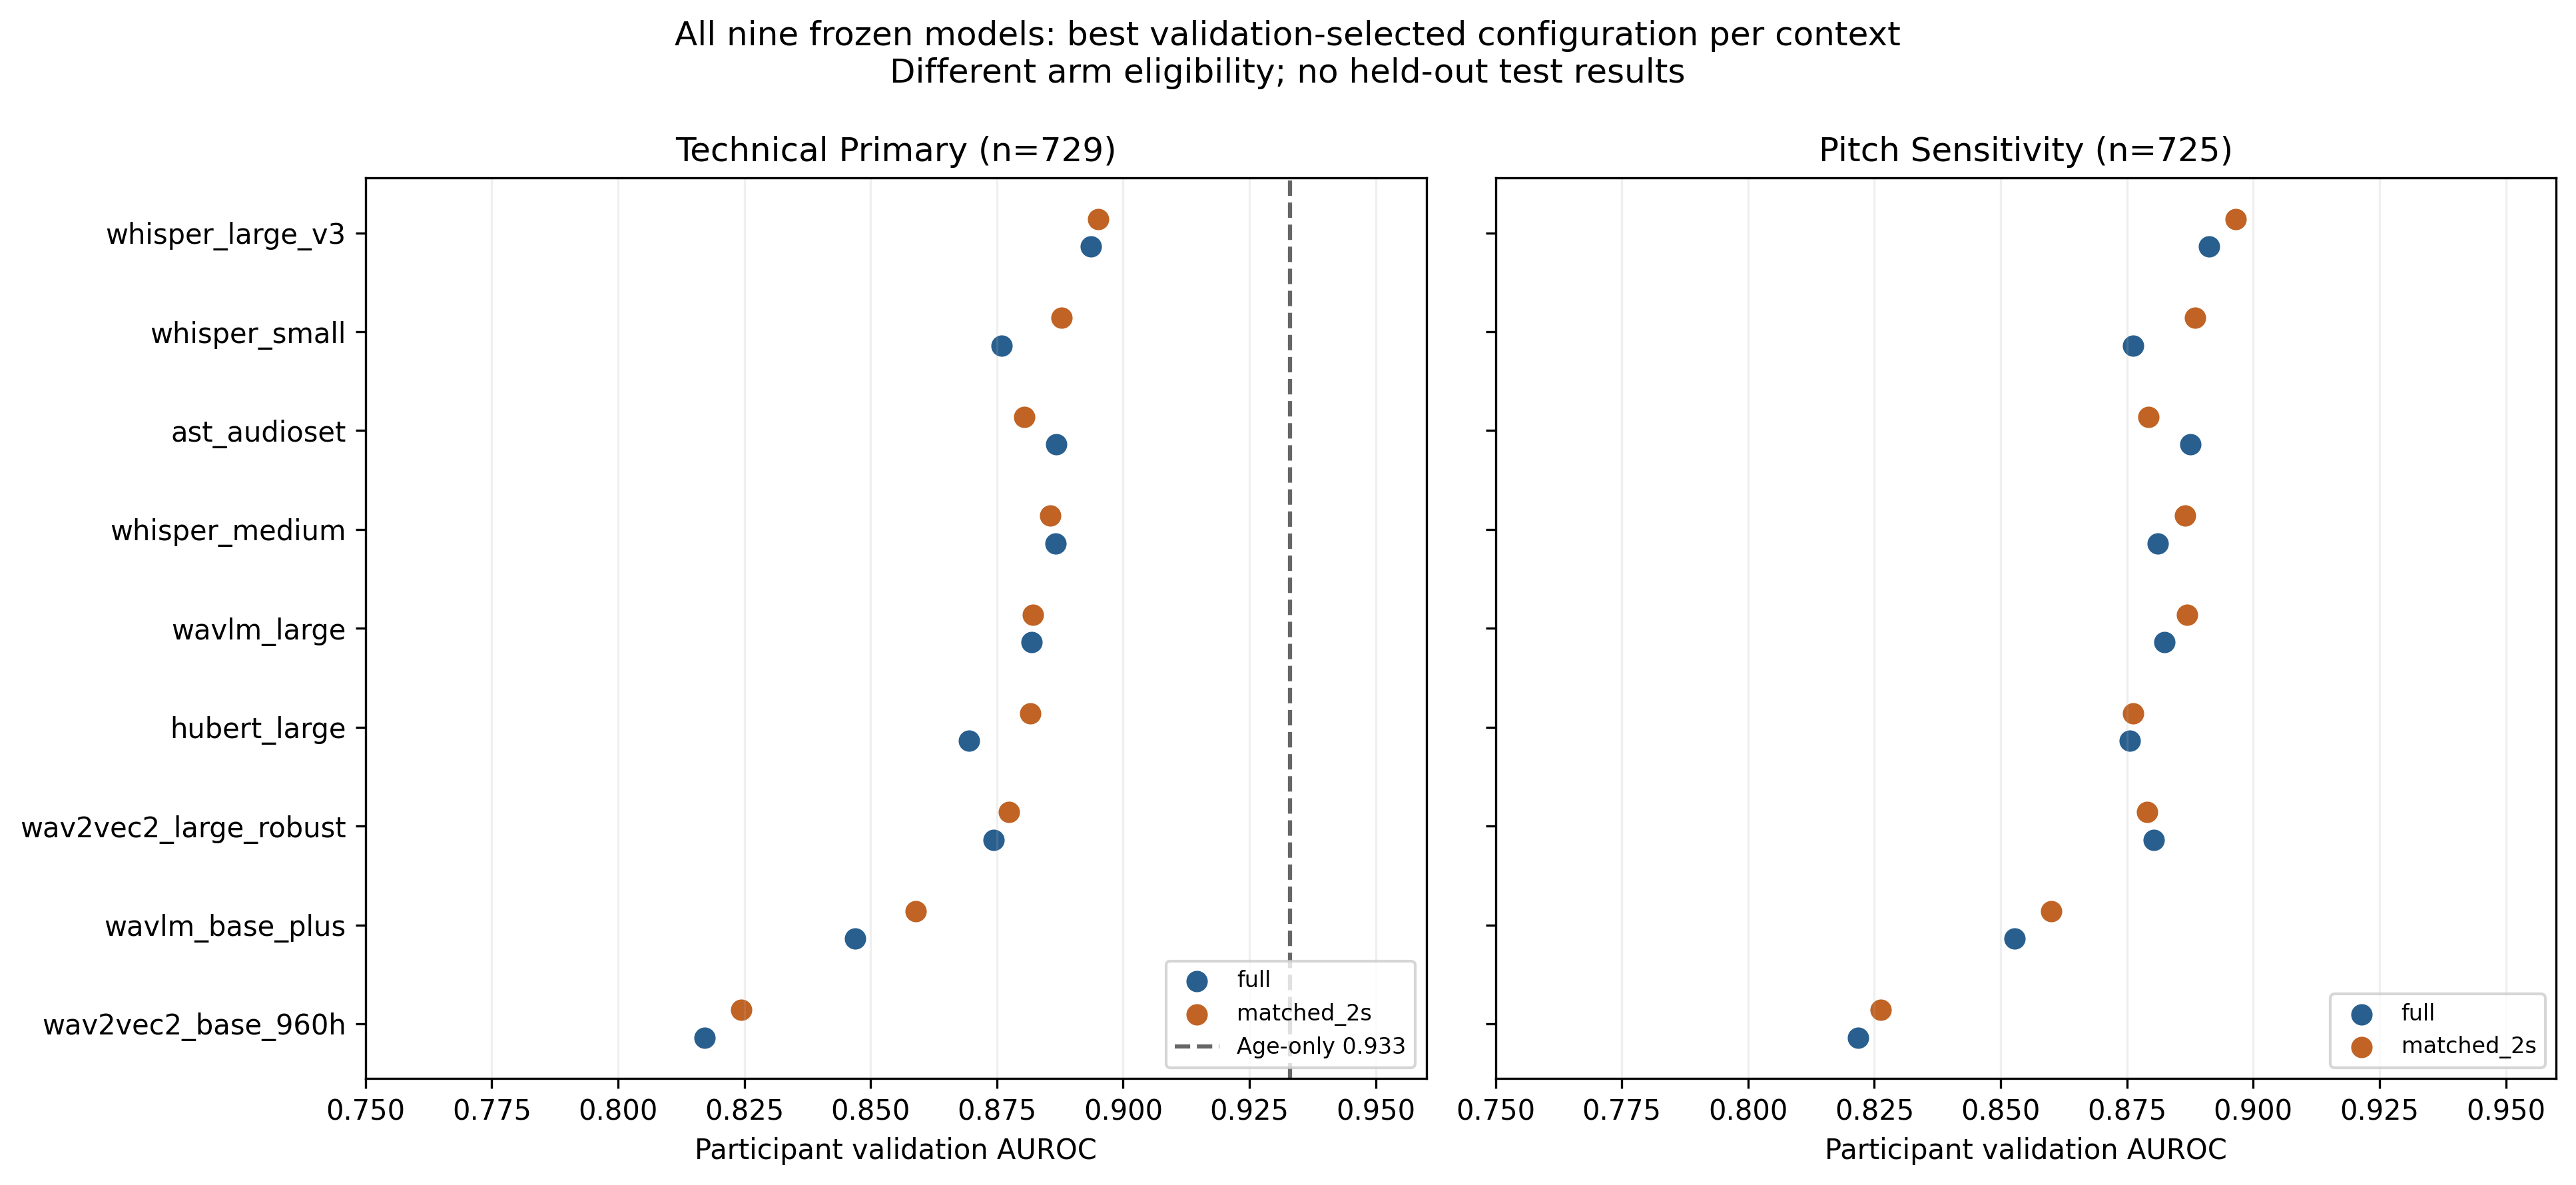

In [3]:
all_frozen = table('all_models/all_364_development_pipelines.csv')
assert len(all_frozen) == 364
figure('all_models/all_models_validation.png')

### Actual selected regularization and neural epochs

Each row below maps to one frozen pipeline above. The complete training-CV and MLP epoch history is also saved in `docs/results/all_models/head_search_history.csv`.

In [4]:
table('all_models/selected_hyperparameters.csv')

,model,context,arm,representation,head,C,cv_auroc,epoch,auroc,log_loss,participants
0,ast_audioset,full,technical_primary,native_pooler/window_mean,logistic,0.01,0.873820,NaN,NaN,NaN,NaN
1,ast_audioset,full,technical_primary,native_pooler/window_mean,mlp,NaN,NaN,8.0,0.879144,0.332592,729.0
2,ast_audioset,full,technical_primary,patches/mean/window_mean,logistic,0.01,0.876382,NaN,NaN,NaN,NaN
3,ast_audioset,full,technical_primary,patches/mean/window_mean,mlp,NaN,NaN,10.0,0.881764,0.321436,729.0
4,ast_audioset,full,technical_primary,patches/mean_sd/window_mean,logistic,0.01,0.882194,NaN,NaN,NaN,NaN
5,ast_audioset,full,technical_primary,patches/mean_sd/window_mean,mlp,NaN,NaN,10.0,0.886710,0.320081,729.0
6,ast_audioset,full,pitch_sensitivity,native_pooler/window_mean,logistic,0.01,0.869972,NaN,NaN,NaN,NaN
7,ast_audioset,full,pitch_sensitivity,native_pooler/window_mean,mlp,NaN,NaN,5.0,0.877610,0.330801,725.0
8,ast_audioset,full,pitch_sensitivity,patches/mean/window_mean,logistic,0.01,0.875192,NaN,NaN,NaN,NaN
9,ast_audioset,full,pitch_sensitivity,patches/mean/window_mean,mlp,NaN,NaN,10.0,0.876849,0.329655,725.0


,model,context,arm,representation,head,C,cv_auroc,epoch,auroc,log_loss,participants
0,ast_audioset,full,technical_primary,native_pooler/window_mean,logistic,0.01,0.873820,NaN,NaN,NaN,NaN
1,ast_audioset,full,technical_primary,native_pooler/window_mean,mlp,NaN,NaN,8.0,0.879144,0.332592,729.0
2,ast_audioset,full,technical_primary,patches/mean/window_mean,logistic,0.01,0.876382,NaN,NaN,NaN,NaN
3,ast_audioset,full,technical_primary,patches/mean/window_mean,mlp,NaN,NaN,10.0,0.881764,0.321436,729.0
4,ast_audioset,full,technical_primary,patches/mean_sd/window_mean,logistic,0.01,0.882194,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
359,whisper_small,matched_2s,pitch_sensitivity,block_6/mean_sd/window_mean,mlp,NaN,NaN,9.0,0.883757,0.323211,725.0
360,whisper_small,matched_2s,pitch_sensitivity,last_hidden/mean/window_mean,logistic,0.10,0.853976,NaN,NaN,NaN,NaN
361,whisper_small,matched_2s,pitch_sensitivity,last_hidden/mean/window_mean,mlp,NaN,NaN,10.0,0.859025,0.353229,725.0
362,whisper_small,matched_2s,pitch_sensitivity,last_hidden/mean_sd/window_mean,logistic,0.01,0.852075,NaN,NaN,NaN,NaN


## D. Historical adaptation batch: complete, but confounded

These 14 runs are retained to explain what actually happened. Each ran ten head warm-up plus20 adaptation epochs, batch32 distinct
people via singleton accumulation, one random visit/person/epoch, BCE, gradient norm clip1, seed20261112.
AST/ResNet use SGD momentum.9/Nesterov weight_decay.01; waveform arms AdamW weight_decay.01.
Warm-up head LR.001. Adapted AST backbone/head start1e-5; ResNet1e-4; waveform backbone5e-6 and head1e-4.
Adaptation cosine endpoint1e-6. Frozen AST/ResNet head branches retained the warm-up LR behavior, confounding the comparison.

Adaptation began from the last warm-up state rather than its best checkpoint. The global selected model could still be from
warm-up. The table therefore explicitly reports **requested policy and selected phase**; requested unfreezing alone does not
establish that the chosen checkpoint benefited from unfreezing. These are actual original-weight updates, not LoRA.
Historical late-resume support was incomplete and is superseded by the corrected runner.

In [5]:
table('historical_adaptation/metrics.csv')

,run,requested_policy,selected_phase,selected_epoch_zero_based,auroc,auprc,log_loss,participants
0,00_ast_audioset_frozen,frozen,frozen,25,0.876654,0.662336,0.337172,729
1,01_ast_audioset_last2,last2,frozen,8,0.868524,0.639840,0.360467,729
2,02_ast_audioset_full,full,full,26,0.869522,0.642560,0.345548,729
3,03_resnet50_frozen,frozen,frozen,23,0.820813,0.551596,0.396596,729
4,04_resnet50_last3,last3,last3,28,0.825701,0.573492,0.385829,729
5,05_resnet50_full,full,full,29,0.836991,0.609448,0.372410,729
6,06_wav2vec2_base_960h_last2,last2,last2,29,0.727919,0.433345,0.449328,729
7,07_wav2vec2_base_960h_last4,last4,last4,29,0.735332,0.421346,0.460616,729
8,08_wav2vec2_large_robust_last2,last2,frozen,3,0.634924,0.319475,0.500390,729
9,09_wav2vec2_large_robust_last4,last4,last4,29,0.635330,0.314717,0.488763,729


,run,requested_policy,selected_phase,selected_epoch_zero_based,auroc,auprc,log_loss,participants
0,00_ast_audioset_frozen,frozen,frozen,25,0.876654,0.662336,0.337172,729
1,01_ast_audioset_last2,last2,frozen,8,0.868524,0.639840,0.360467,729
2,02_ast_audioset_full,full,full,26,0.869522,0.642560,0.345548,729
3,03_resnet50_frozen,frozen,frozen,23,0.820813,0.551596,0.396596,729
4,04_resnet50_last3,last3,last3,28,0.825701,0.573492,0.385829,729
5,05_resnet50_full,full,full,29,0.836991,0.609448,0.372410,729
6,06_wav2vec2_base_960h_last2,last2,last2,29,0.727919,0.433345,0.449328,729
7,07_wav2vec2_base_960h_last4,last4,last4,29,0.735332,0.421346,0.460616,729
8,08_wav2vec2_large_robust_last2,last2,frozen,3,0.634924,0.319475,0.500390,729
9,09_wav2vec2_large_robust_last4,last4,last4,29,0.635330,0.314717,0.488763,729


## E. Corrected paired AST controls

A single best ten-epoch warm-up initialized all three branches; native LayerNorm+Linear head, SGD momentum.9/Nesterov,
weight_decay.01, batch32 (microbatch4), clip1. All branches used the same20-epoch head cosine1e-3→1e-5;
last2/full backbone cosine1e-5→1e-6. Optimizers reset identically at branching. Test rows refused; full RNG/optimizer resume
and production frozen/trainable parameter audits implemented.

**Head-only0.8715, last2 0.8671, full0.8647.** Fine-tuning did not improve this matched AST control.
Tougui et al.'s paper compared from-scratch AST with pretrained+fine-tuned AST, not a final frozen-pretrained control;
its repeated-visit endpoint/cohort/five-seed evaluation differ from this initial-assessment experiment.

## F. Earlier HeAR frozen and weak-warm-up tuning, plus downstream panels

The four cached frozen heads use native512D mean or1024D mean+SD window features and the same LR/MLP development fitting above.
The earlier trainable run used LayerNorm+Linear initialized from a ten-epoch AdamW warm-up at1e-4. Its warm-up AUROC was only.6866.
Three20-epoch branches shared that warm-up: head cosine1e-4→1e-5; adapted backbone5e-6→1e-6, weight_decay.01,
effectivebatch32/microbatch1, clip1, float32. Head-only.7229, last2 .8012, full.8701. These controls show improvement over
a weak head, but full tuning merely matched the much stronger standardized frozen LR probe. The next section fixes that initialization.

Downstream panel: canonical initial training visit/person, train-fold median imputation/StandardScaler; LR C∈{.01,.1,1,10}
crossed with PCA∈{none,32,128}; LinearSVC C∈{.01,.1,1}, no PCA. Training-only grouped3-fold CV selects heads.
SVM probabilities use a training-OOF logistic calibrator. Early fusion concatenates encoder features then fits the same pipeline.
Equal average uses fixed LR C.1; stacking trains LR C.1 on training-OOF predictions, never validation-label fit.
Age/device controls fit imputation/encoding on training only. Acoustic PCA alignment remains a prototype, not a completed contrastive model.

The following full table includes earlier HeAR/AST metrics, every completed fusion and demographic control. Its summary
includes paired intervals and parameter audits. Thresholds target ≥90% specificity **on validation**, so operating points
are exploratory and not independently locked test performance.
The original HeAR cached-head runner saved selected weights but did not persist the LR CV history or selected MLP epoch.
Actual LR C values are recovered from the saved estimators below; the missing MLP epoch is reported as unavailable, never inferred.
Later frozen-sweep and literature runners retain the full histories shown elsewhere in this notebook.

,experiment,auroc,auprc,log_loss,brier,accuracy_at_0_5,threshold,specificity,sensitivity,controls,threshold_selection
0,frozen_mean_logistic,0.869980,0.685787,0.333620,0.101867,0.864198,0.331708,0.900515,0.623288,583,"validation; exploratory, not a locked test operating point"
1,frozen_mean_mlp,0.854649,0.632644,0.353404,0.110258,0.842250,0.359452,0.900515,0.616438,583,"validation; exploratory, not a locked test operating point"
2,frozen_mean_sd_logistic,0.858279,0.689653,0.340511,0.102940,0.866941,0.324928,0.900515,0.623288,583,"validation; exploratory, not a locked test operating point"
3,frozen_mean_sd_mlp,0.857598,0.665921,0.345180,0.105324,0.851852,0.366682,0.900515,0.630137,583,"validation; exploratory, not a locked test operating point"
4,warmup,0.686576,0.359580,0.474420,0.151330,0.799726,0.253718,0.900515,0.253425,583,"validation; exploratory, not a locked test operating point"
5,native_frozen,0.722855,0.399405,0.459326,0.146265,0.802469,0.274880,0.900515,0.335616,583,"validation; exploratory, not a locked test operating point"
6,last2,0.801170,0.527146,0.406874,0.128102,0.825789,0.315304,0.900515,0.452055,583,"validation; exploratory, not a locked test operating point"
7,full,0.870110,0.670167,0.335055,0.100677,0.862826,0.326462,0.900515,0.691781,583,"validation; exploratory, not a locked test operating point"
8,panel_whisper_small,0.866432,0.670230,0.341422,0.104778,0.850480,0.335085,0.900515,0.643836,583,"validation; exploratory, not a locked test operating point"
9,panel_wavlm_large,0.871637,0.674126,0.334312,0.100960,0.872428,0.345416,0.900515,0.636986,583,"validation; exploratory, not a locked test operating point"


```json
{
  "status": "completed_development_analysis",
  "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
  "recordings_extracted": 53122,
  "participants_train": 3397,
  "validation_participants": 729,
  "validation_pd": 146,
  "validation_controls": 583,
  "validation_duplicate_components": 729,
  "test_labels_read": false,
  "branch_initialization_matched": true,
  "training_audits": {
    "warmup": {
      "selected_epoch": 10,
      "initial_auroc": 0.5071782701661223,
      "backbone_changed": false,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    },
    "native_frozen": {
      "selected_epoch": 20,
      "initial_auroc": 0.686576282337461,
      "backbone_changed": false,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    },
    "last2": {
      "selected_epoch": 20,
      "initial_auroc": 0.686576282337461,
      "backbone_changed": true,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    },
    "full": {
      "selected_epoch": 20,
      "initial_auroc": 0.686576282337461,
      "backbone_changed": true,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    }
  },
  "corrected_AST_audits": {
    "frozen": {
      "best_phase_auroc": 0.8714607956014004,
      "selected_epoch": 19,
      "backbone_changed": false,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    },
    "last2": {
      "best_phase_auroc": 0.8671138889541576,
      "selected_epoch": 13,
      "backbone_changed": true,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    },
    "full": {
      "best_phase_auroc": 0.8646702225146269,
      "selected_epoch": 20,
      "backbone_changed": true,
      "head_changed": true,
      "frozen_parameters_unchanged": true
    }
  },
  "metrics": {
    "frozen_mean_logistic": {
      "auroc": 0.8699804976620691,
      "auprc": 0.68578746214767,
      "log_loss": 0.3336195520622898,
      "brier": 0.10186703012252585,
      "accuracy_at_0_5": 0.8641975308641975,
      "threshold": 0.33170798000000007,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6232876712328768,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "frozen_mean_mlp": {
      "auroc": 0.8546488404332808,
      "auprc": 0.6326437029495608,
      "log_loss": 0.3534043720114831,
      "brier": 0.11025821678788111,
      "accuracy_at_0_5": 0.8422496570644719,
      "threshold": 0.35945177000000006,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6164383561643836,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "frozen_mean_sd_logistic": {
      "auroc": 0.8582790949035456,
      "auprc": 0.6896530165452194,
      "log_loss": 0.34051146562537515,
      "brier": 0.10293952261825463,
      "accuracy_at_0_5": 0.8669410150891632,
      "threshold": 0.32492778000000005,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6232876712328768,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "frozen_mean_sd_mlp": {
      "auroc": 0.8575976879155995,
      "auprc": 0.6659214241369521,
      "log_loss": 0.34517982417103416,
      "brier": 0.10532423678036568,
      "accuracy_at_0_5": 0.8518518518518519,
      "threshold": 0.36668220000000007,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6301369863013698,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "warmup": {
      "auroc": 0.686576282337461,
      "auprc": 0.3595803166587126,
      "log_loss": 0.47442015330260995,
      "brier": 0.15133004459506003,
      "accuracy_at_0_5": 0.7997256515775034,
      "threshold": 0.2537175118923188,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.2534246575342466,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "native_frozen": {
      "auroc": 0.7228553302474212,
      "auprc": 0.39940497108160117,
      "log_loss": 0.45932605910507285,
      "brier": 0.14626450090578413,
      "accuracy_at_0_5": 0.8024691358024691,
      "threshold": 0.27488020062446594,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.3356164383561644,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "last2": {
      "auroc": 0.8011701402758523,
      "auprc": 0.5271458214872679,
      "log_loss": 0.40687417228526385,
      "brier": 0.12810172016502325,
      "accuracy_at_0_5": 0.8257887517146777,
      "threshold": 0.31530445814132696,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.4520547945205479,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "full": {
      "auroc": 0.8701097300218521,
      "auprc": 0.6701669612839438,
      "log_loss": 0.3350545505801639,
      "brier": 0.10067686049103625,
      "accuracy_at_0_5": 0.8628257887517147,
      "threshold": 0.32646244764328003,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6917808219178082,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_whisper_small": {
      "auroc": 0.8664324819662114,
      "auprc": 0.6702297415804831,
      "log_loss": 0.34142157246221383,
      "brier": 0.10477831375014512,
      "accuracy_at_0_5": 0.850480109739369,
      "threshold": 0.33508476614952093,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6438356164383562,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_wavlm_large": {
      "auroc": 0.8716370215465589,
      "auprc": 0.6741259643241272,
      "log_loss": 0.33431151585920926,
      "brier": 0.10095956651659875,
      "accuracy_at_0_5": 0.8724279835390947,
      "threshold": 0.3454160392284394,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.636986301369863,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_hear": {
      "auroc": 0.8570455132874362,
      "auprc": 0.6417692197114141,
      "log_loss": 0.3490440697414182,
      "brier": 0.1067650171003752,
      "accuracy_at_0_5": 0.8518518518518519,
      "threshold": 0.3315266072750092,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6027397260273972,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_early_fusion": {
      "auroc": 0.8794027115298763,
      "auprc": 0.7007164946700595,
      "log_loss": 0.32455324808794206,
      "brier": 0.09749861195790986,
      "accuracy_at_0_5": 0.8806584362139918,
      "threshold": 0.3093914687633515,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6575342465753424,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_age_device": {
      "auroc": 0.935195845767053,
      "auprc": 0.750920383756,
      "log_loss": 0.24876305942112706,
      "brier": 0.07675421622896433,
      "accuracy_at_0_5": 0.8861454046639232,
      "threshold": 0.31471467222864374,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.8698630136986302,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_age_device_whisper": {
      "auroc": 0.9357010268098405,
      "auprc": 0.8084874411624792,
      "log_loss": 0.2492493882607425,
      "brier": 0.0738197205745255,
      "accuracy_at_0_5": 0.9026063100137174,
      "threshold": 0.20466637236132368,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.8698630136986302,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_age_device_fusion": {
      "auroc": 0.9141779647078173,
      "auprc": 0.7962179626297952,
      "log_loss": 0.27233562059459626,
      "brier": 0.08066889573224746,
      "accuracy_at_0_5": 0.897119341563786,
      "threshold": 0.24011616737137467,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.773972602739726,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_equal_average": {
      "auroc": 0.8697220329425034,
      "auprc": 0.6737216801019554,
      "log_loss": 0.3391538317259967,
      "brier": 0.10244682567541666,
      "accuracy_at_0_5": 0.869684499314129,
      "threshold": 0.35177779197692877,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6301369863013698,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "panel_oof_stack": {
      "auroc": 0.8710613501257078,
      "auprc": 0.6750603217760949,
      "log_loss": 0.34148631842968263,
      "brier": 0.10306585111920506,
      "accuracy_at_0_5": 0.8600823045267489,
      "threshold": 0.26635339029723015,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6438356164383562,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "two_encoder_early_fusion": {
      "auroc": 0.8758664442303625,
      "auprc": 0.7001688817202493,
      "log_loss": 0.32733536765374166,
      "brier": 0.09807888541871215,
      "accuracy_at_0_5": 0.8655692729766804,
      "threshold": 0.312693864107132,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6575342465753424,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "ast_frozen": {
      "auroc": 0.8714607956014004,
      "auprc": 0.6462113103924285,
      "log_loss": 0.3467638467457591,
      "brier": 0.10922174536200545,
      "accuracy_at_0_5": 0.8463648834019204,
      "threshold": 0.31124743819236755,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.5958904109589042,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "ast_last2": {
      "auroc": 0.8671138889541576,
      "auprc": 0.6370770920674057,
      "log_loss": 0.35147030613518415,
      "brier": 0.11041192586834449,
      "accuracy_at_0_5": 0.8463648834019204,
      "threshold": 0.30676043033599854,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.5958904109589042,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    },
    "ast_full": {
      "auroc": 0.8646702225146269,
      "auprc": 0.6291981842867977,
      "log_loss": 0.35423975806255825,
      "brier": 0.11114756253950965,
      "accuracy_at_0_5": 0.8463648834019204,
      "threshold": 0.30801597237586975,
      "specificity": 0.9005145797598628,
      "sensitivity": 0.6027397260273972,
      "controls": 583,
      "threshold_selection": "validation; exploratory, not a locked test operating point"
    }
  },
  "paired_comparisons": {
    "full_minus_native_frozen": {
      "auroc_delta": 0.1472543997744309,
      "paired_component_bootstrap_95pct": [
        0.10753892251856106,
        0.18754619263414699
      ]
    },
    "last2_minus_native_frozen": {
      "auroc_delta": 0.0783148100284311,
      "paired_component_bootstrap_95pct": [
        0.055852542120790535,
        0.10159156776417307
      ]
    },
    "full_minus_frozen_logistic": {
      "auroc_delta": 0.00012923235978301584,
      "paired_component_bootstrap_95pct": [
        -0.0187355097707551,
        0.01987574006267434
      ]
    },
    "three_encoder_fusion_minus_best_single_WavLM": {
      "auroc_delta": 0.007765689983317392,
      "paired_component_bootstrap_95pct": [
        -0.007317341157012372,
        0.024020155717656887
      ]
    },
    "age_device_three_encoder_fusion_minus_age_device": {
      "auroc_delta": -0.021017881059235632,
      "paired_component_bootstrap_95pct": [
        -0.04464226160322284,
        0.0015054367795020167
      ]
    },
    "age_device_whisper_minus_age_device": {
      "auroc_delta": 0.000505181042787517,
      "paired_component_bootstrap_95pct": [
        -0.01643262983534343,
        0.015292892911001558
      ]
    },
    "three_minus_two_encoder_fusion": {
      "auroc_delta": 0.003536267299513729,
      "paired_component_bootstrap_95pct": [
        -0.005462397647196487,
        0.012424074186189965
      ]
    },
    "AST_full_minus_frozen": {
      "auroc_delta": -0.006790573086773555,
      "paired_component_bootstrap_95pct": [
        -0.011863881881418584,
        -0.0017765677271063128
      ]
    },
    "AST_last2_minus_frozen": {
      "auroc_delta": -0.004346906647242799,
      "paired_component_bootstrap_95pct": [
        -0.007789208469869769,
        -0.0010110550785643853
      ]
    }
  },
  "bootstrap_replicates": 2000,
  "uncertainty_limit": "Exploratory development intervals; conditional on fitted models/selected checkpoints, not corrected for model selection or training seeds.",
  "training_designs": {
    "frozen_probe": "all training visits with equal-person weights; train-CV LR selection",
    "native_adaptation": "one visit/person/epoch; identical LayerNorm+linear head and best warm-up for branches",
    "downstream_panel": "canonical initial training visit/person; train-CV head selection; training OOF calibration/stacking"
  },
  "threshold_selection": "validation only; not a prospective test operating point"
}
```

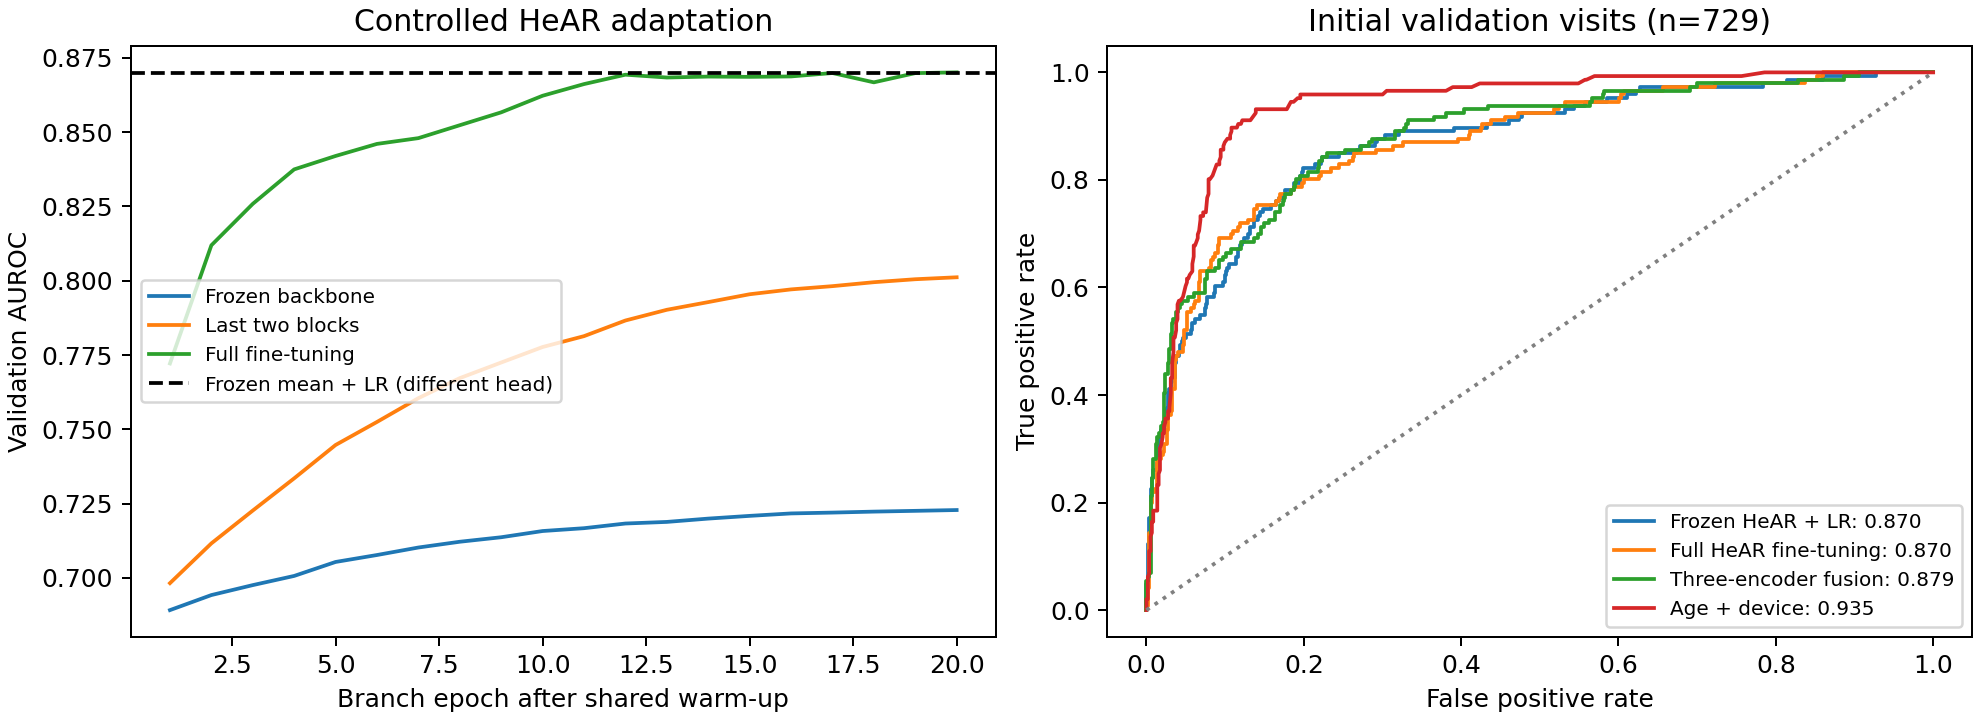

,experiment,spec,cv_auroc,auroc,auprc,log_loss,brier,participants,threshold,specificity,sensitivity,controls,threshold_selection
0,whisper_small,"{""kind"": ""lr"", ""C"": 0.01, ""pca"": null}",0.856410,0.866432,0.670230,0.341422,0.104778,729,0.335085,0.900515,0.643836,583,"validation; exploratory, not a locked test operating point"
1,wavlm_large,"{""kind"": ""lr"", ""C"": 0.01, ""pca"": 128}",0.866071,0.871637,0.674126,0.334312,0.100960,729,0.345416,0.900515,0.636986,583,"validation; exploratory, not a locked test operating point"
2,hear,"{""kind"": ""lr"", ""C"": 0.01, ""pca"": null}",0.853494,0.857046,0.641769,0.349044,0.106765,729,0.331527,0.900515,0.602740,583,"validation; exploratory, not a locked test operating point"
3,early_fusion,"{""kind"": ""lr"", ""C"": 0.01, ""pca"": 128}",0.879675,0.879403,0.700716,0.324553,0.097499,729,0.309391,0.900515,0.657534,583,"validation; exploratory, not a locked test operating point"
4,age_device,"{""kind"": ""lr"", ""C"": 10, ""pca"": null}",0.926653,0.935196,0.750920,0.248763,0.076754,729,0.314715,0.900515,0.869863,583,"validation; exploratory, not a locked test operating point"
5,age_device_whisper,"{""kind"": ""lr"", ""C"": 0.01, ""pca"": 128}",0.924286,0.935701,0.808487,0.249249,0.073820,729,0.204666,0.900515,0.869863,583,"validation; exploratory, not a locked test operating point"
6,age_device_fusion,"{""kind"": ""lr"", ""C"": 0.01, ""pca"": 128}",0.918440,0.914178,0.796218,0.272336,0.080669,729,0.240116,0.900515,0.773973,583,"validation; exploratory, not a locked test operating point"
7,equal_average,NaN,NaN,0.869722,0.673722,0.339154,0.102447,729,0.351778,0.900515,0.630137,583,"validation; exploratory, not a locked test operating point"
8,oof_stack,NaN,NaN,0.871061,0.675060,0.341486,0.103066,729,0.266353,0.900515,0.643836,583,"validation; exploratory, not a locked test operating point"


```json
{
  "age_device_fusion_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.9177508911505831
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.9038183451273216
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8962855441506985
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.8923817536744211
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 32
      },
      "cv_auroc": 0.8377356649764344
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 32
      },
      "cv_auroc": 0.8375226827051252
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 32
      },
      "cv_auroc": 0.8375064533671237
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 32
      },
      "cv_auroc": 0.8375080598062364
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 128
      },
      "cv_auroc": 0.9184398957547236
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 128
      },
      "cv_auroc": 0.9177214015182974
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 128
      },
      "cv_auroc": 0.9174690758319296
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 128
      },
      "cv_auroc": 0.9174186522899546
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8833990051379947
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8717393122816945
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8702249924117266
    }
  ],
  "age_device_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.9234562708197019
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.924895912785732
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.9264125777699407
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.9266526830444856
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.9242693011292781
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.9257487311497637
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.9258039883522837
    }
  ],
  "age_device_whisper_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.9223493589691181
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.9007578634692561
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8846084744998876
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.8800402851899882
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 32
      },
      "cv_auroc": 0.8508871086674877
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 32
      },
      "cv_auroc": 0.8510088107734921
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 32
      },
      "cv_auroc": 0.8510040775153919
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 32
      },
      "cv_auroc": 0.8510057126409173
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 128
      },
      "cv_auroc": 0.9242864376750822
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 128
      },
      "cv_auroc": 0.9194488040620191
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 128
      },
      "cv_auroc": 0.9180306410475199
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 128
      },
      "cv_auroc": 0.9178274408429514
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8893682173307873
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8648881937023628
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8611267810640646
    }
  ],
  "early_fusion_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8735704090358299
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8532142078409203
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8436573401975328
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.8416967960059564
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 32
      },
      "cv_auroc": 0.8248347540709534
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 32
      },
      "cv_auroc": 0.824704790278083
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 32
      },
      "cv_auroc": 0.8246950655841676
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 32
      },
      "cv_auroc": 0.8246982712907901
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 128
      },
      "cv_auroc": 0.8796745621141014
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 128
      },
      "cv_auroc": 0.8786454119568239
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 128
      },
      "cv_auroc": 0.8785468848865032
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 128
      },
      "cv_auroc": 0.8785160183064065
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.820512923673574
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8056545451942815
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8039029169750097
    }
  ],
  "hear_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8534937569329681
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8466598788876866
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8213169034199339
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.79141738532585
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 32
      },
      "cv_auroc": 0.8018935915385869
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 32
      },
      "cv_auroc": 0.8017617129276667
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 32
      },
      "cv_auroc": 0.8016855505018702
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 32
      },
      "cv_auroc": 0.8016888064097151
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 128
      },
      "cv_auroc": 0.850378821291939
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 128
      },
      "cv_auroc": 0.8485506362086959
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 128
      },
      "cv_auroc": 0.8458795654318285
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 128
      },
      "cv_auroc": 0.8454700310321007
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.844273628331206
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8175264529603504
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.7885310373646549
    }
  ],
  "wavlm_large_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8634188612991577
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8342058305764972
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8110822045301639
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.8051593782667549
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 32
      },
      "cv_auroc": 0.8245973883488241
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 32
      },
      "cv_auroc": 0.8241824824183128
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 32
      },
      "cv_auroc": 0.8240750661458476
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 32
      },
      "cv_auroc": 0.8240766654133572
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 128
      },
      "cv_auroc": 0.8660705687474328
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 128
      },
      "cv_auroc": 0.8632949001381508
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 128
      },
      "cv_auroc": 0.862602653969372
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 128
      },
      "cv_auroc": 0.8625294964453087
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8177352900450203
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.7852981647092924
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.7794727359887026
    }
  ],
  "whisper_small_search": [
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8564099674498143
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.8313529094577353
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.8107517191265137
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": null
      },
      "cv_auroc": 0.804638594372661
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 32
      },
      "cv_auroc": 0.8108589561088992
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 32
      },
      "cv_auroc": 0.8108429562621994
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 32
      },
      "cv_auroc": 0.810820093191254
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 32
      },
      "cv_auroc": 0.8108152165010901
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.01,
        "pca": 128
      },
      "cv_auroc": 0.8475661974114587
    },
    {
      "spec": {
        "kind": "lr",
        "C": 0.1,
        "pca": 128
      },
      "cv_auroc": 0.8451858921140163
    },
    {
      "spec": {
        "kind": "lr",
        "C": 1,
        "pca": 128
      },
      "cv_auroc": 0.844696186362313
    },
    {
      "spec": {
        "kind": "lr",
        "C": 10,
        "pca": 128
      },
      "cv_auroc": 0.8446391936318229
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.01,
        "pca": null
      },
      "cv_auroc": 0.8192949631335132
    },
    {
      "spec": {
        "kind": "svm",
        "C": 0.1,
        "pca": null
      },
      "cv_auroc": 0.790282084684069
    },
    {
      "spec": {
        "kind": "svm",
        "C": 1,
        "pca": null
      },
      "cv_auroc": 0.7841096579435014
    }
  ]
}
```

```json
{
  "mean/logistic": {
    "selected_C": 0.1,
    "cv_folds": 3,
    "C_grid": [
      0.01,
      0.1,
      1.0
    ],
    "search_history_saved": false
  },
  "mean/mlp": {
    "input_dim": 512,
    "hidden_dim": 64,
    "epoch_budget": 10,
    "selected_epoch": null,
    "audit_gap": "The original HeAR cached-head runner saved selected weights but did not persist epoch/search metadata."
  },
  "mean_sd/logistic": {
    "selected_C": 0.01,
    "cv_folds": 3,
    "C_grid": [
      0.01,
      0.1,
      1.0
    ],
    "search_history_saved": false
  },
  "mean_sd/mlp": {
    "input_dim": 1024,
    "hidden_dim": 64,
    "epoch_budget": 10,
    "selected_epoch": null,
    "audit_gap": "The original HeAR cached-head runner saved selected weights but did not persist epoch/search metadata."
  }
}
```

In [6]:
table('hear_completed/metrics.csv')
report('hear_completed/summary.json')
figure('hear_completed/learning_and_roc.png')
table('downstream_completed/selected_models.csv')
report('downstream_completed/search_history.json')
report('downstream_completed/hear_frozen_selected_hyperparameters.json')

## G. Literature-inspired strong initialization: LP → full tuning and LoRA

All three arms begin from exactly the same converged train-fitted HeAR standardized logistic probe, AUROC.8700.
Fixed train mean/scale are preserved as buffers; real-waveform initial probabilities were checked against sklearn.
This removes the poor random-head warm-up as the starting point. The initial LP is an explicit epoch-zero selection candidate.

All arms: AdamW betas(.9,.999), fixed head LR1e-4, weight_decay.01,20epochs, batch32/microbatch1, one visit/person/epoch,
no AMP/TF32, clip1, seed20261112. Full tuning: backboneLR5e-6,303,199,744 trainable backbone parameters.
LoRA: original weights frozen, Q/V adapters in all24 blocks, rank8/alpha16/dropout0, adapterLR1e-4,
786,432 trainable adapter parameters (~.26% of original backbone). Update `W+(alpha/r)BA`; zeroB/randomA gives initially identical logits.
Non-reentrant encoder checkpointing is used for full/LoRA. No additional cosine schedule or early-stop patience is invented;
all20epochs complete, with epoch-zero/epoch AUROC then log-loss checkpoint selection.

Selected: head-only epoch18 **.8721**; full epoch13 **.8940**; LoRA epoch18 **.8908**.
These are the first strong matched fine-tuning gains here. Parameter audits confirm full changed original weights and LoRA
changed adapters while original pretrained tensors stayed identical. They are one-seed validation findings, not final-test gains.

Inspiration: Kumar et al. LP-FT (ICLR2022), Hu et al. LoRA (ICLR2022); hyperparameters transferred to HeAR are project hypotheses,
not a claim that the source papers established optimal settings for mPower.

## H. HuBERT Base: precisely what is contrasted

Two matched100-epoch arms use actual batches of up to32 distinct people, class-balanced sampling and one selected training visit/person.
Each epoch uses all679 PD people and a seeded without-replacement subset of679 controls; the majority subset varies across epochs.
Thus each epoch trains on1,358 people, rather than all3,397; the two arms use the same schedule.
The final partial batch can be smaller (observed minimum14). CE classifier losses are weighted by `2*PD_prior` / `2*(1-PD_prior)`
to recover the original training-person prevalence (~.19988). Native768D temporal mean→64/ReLU/dropout.2→2 classifier.
AdamW2e-5 for backbone/head/projector, betas(.9,.999), weight_decay.01, fixedLR, clip1, frozenCNN, mask-time/feature/layerdrop0.

In the contrastive arm, **positive pairs share diagnosis across different participants**; self, same-person and duplicate-component
pairs are masked. Different-diagnosis eligible people supply negatives. A declared single-linear32D projector with normalized vectors
and temperature.07 supplies SupCon. CE sees detached encoder features, so CE updates the classifier while SupCon updates encoder/projector;
objective coefficient1 for each term. The actual contrastive batch graph is retained via checkpointing. Accumulation across separate
batches is not substituted for a larger denominator. In the CE control, CE updates the encoder directly.

**CE .8604 (epoch33); detached SupCon .8527 (epoch37).** The proposed contrastive mechanism did not improve AUROC here.
This adapts a NeuroVoz repeated-sentence method to sustained vowels. The source's hard-negative formula/projector depth and filtering
were underspecified; no formula/filter was fabricated. Project choices and deviations are explicit, so this is not exact numerical SOTA reproduction.

In [7]:
table('literature_completed/metrics.csv')
report('literature_completed/summary.json')

,method,auroc,auprc,log_loss,brier,participants,selected_epoch,selected_stage,threshold,specificity,sensitivity,controls,threshold_selection
0,hear_lp_frozen,0.872107,0.688766,0.331796,0.101425,729,18,adaptation,0.340503,0.900515,0.609589,583,"validation; exploratory, not a locked test operating point"
1,hear_lp_full,0.894041,0.744867,0.312368,0.091968,729,13,adaptation,0.369103,0.900515,0.691781,583,"validation; exploratory, not a locked test operating point"
2,hear_lp_lora,0.890799,0.735052,0.310220,0.093576,729,18,adaptation,0.315665,0.900515,0.678082,583,"validation; exploratory, not a locked test operating point"
3,hubert_ce,0.860359,0.668117,0.417286,0.115540,729,33,adaptation,0.196918,0.900515,0.602740,583,"validation; exploratory, not a locked test operating point"
4,hubert_detached_supcon,0.852710,0.647090,0.410462,0.120068,729,37,adaptation,0.140655,0.900515,0.582192,583,"validation; exploratory, not a locked test operating point"


```json
{
  "status": "all_five_production_arms_verified_complete",
  "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
  "validation_participants": 729,
  "validation_pd": 146,
  "test_labels_read": false,
  "bootstrap_replicates": 2000,
  "bootstrap_seed": 20261116,
  "paired_comparisons": {
    "hear_lp_full_minus_hear_lp_frozen": {
      "auroc_delta": 0.021934255974059513,
      "paired_component_bootstrap_95pct": [
        0.009885013795273396,
        0.03469516805293066
      ]
    },
    "hear_lp_lora_minus_hear_lp_frozen": {
      "auroc_delta": 0.018691698583143346,
      "paired_component_bootstrap_95pct": [
        0.008605872053988902,
        0.029680445284747285
      ]
    },
    "hear_lp_full_minus_hear_lp_lora": {
      "auroc_delta": 0.0032425573909161676,
      "paired_component_bootstrap_95pct": [
        -0.005159974258350436,
        0.011093039284705095
      ]
    },
    "hubert_detached_supcon_minus_hubert_ce": {
      "auroc_delta": -0.0076482060198783675,
      "paired_component_bootstrap_95pct": [
        -0.034410128838170344,
        0.02090511470545643
      ]
    }
  },
  "training_audits": {
    "hear_lp_frozen": {
      "status": "complete",
      "method": "hear_lp_frozen",
      "family": "hear_lpft",
      "policy": "frozen",
      "objective": "bce",
      "selected_epoch": 18,
      "selected_stage": "adaptation",
      "validation_metrics": {
        "epoch": 18,
        "selected_stage": "adaptation",
        "auroc": 0.8721069574003149,
        "auprc": 0.6887662038237261,
        "log_loss": 0.331795666002556,
        "participants": 729
      },
      "initial_validation_metrics": {
        "auroc": 0.8699804976620691,
        "auprc": 0.68578746214767,
        "log_loss": 0.3336195564990903,
        "participants": 729
      },
      "initial_base_sha256": "242905de506698d83e033d0f85cfdc73cc6d2f2cffa0765340674623c0344c66",
      "initial_head_sha256": "8c28383d85902b241886032e940e04c066dd6d86d8e3f0061185d63c27fa3379",
      "pretrained_weights_changed": false,
      "trainable_backbone_or_adapter_changed": false,
      "frozen_parameters_unchanged": true,
      "head_changed": true,
      "projector_changed": false,
      "trainable_backbone_parameters": 0,
      "test_labels_read": false,
      "training_pd_prior": 0.19988224904327348,
      "train_participants": 3397,
      "validation_participants": 729,
      "interpretation": "strong_converged_LP_head_only_control"
    },
    "hear_lp_full": {
      "status": "complete",
      "method": "hear_lp_full",
      "family": "hear_lpft",
      "policy": "full",
      "objective": "bce",
      "selected_epoch": 13,
      "selected_stage": "adaptation",
      "validation_metrics": {
        "epoch": 13,
        "selected_stage": "adaptation",
        "auroc": 0.8940412133743744,
        "auprc": 0.7448673780605315,
        "log_loss": 0.31236844516734924,
        "participants": 729
      },
      "initial_validation_metrics": {
        "auroc": 0.8699804976620691,
        "auprc": 0.68578746214767,
        "log_loss": 0.3336195564990903,
        "participants": 729
      },
      "initial_base_sha256": "242905de506698d83e033d0f85cfdc73cc6d2f2cffa0765340674623c0344c66",
      "initial_head_sha256": "8c28383d85902b241886032e940e04c066dd6d86d8e3f0061185d63c27fa3379",
      "pretrained_weights_changed": true,
      "trainable_backbone_or_adapter_changed": true,
      "frozen_parameters_unchanged": true,
      "head_changed": true,
      "projector_changed": false,
      "trainable_backbone_parameters": 303199744,
      "test_labels_read": false,
      "training_pd_prior": 0.19988224904327348,
      "train_participants": 3397,
      "validation_participants": 729,
      "interpretation": "LP_FT_method_adapted_from_Kumar_ICLR2022_not_original_dataset_replication"
    },
    "hear_lp_lora": {
      "status": "complete",
      "method": "hear_lp_lora",
      "family": "hear_lpft",
      "policy": "lora",
      "objective": "bce",
      "selected_epoch": 18,
      "selected_stage": "adaptation",
      "validation_metrics": {
        "epoch": 18,
        "selected_stage": "adaptation",
        "auroc": 0.8907986559834582,
        "auprc": 0.7350524332039315,
        "log_loss": 0.31022032938925453,
        "participants": 729
      },
      "initial_validation_metrics": {
        "auroc": 0.8699804976620691,
        "auprc": 0.68578746214767,
        "log_loss": 0.3336195564990903,
        "participants": 729
      },
      "initial_base_sha256": "242905de506698d83e033d0f85cfdc73cc6d2f2cffa0765340674623c0344c66",
      "initial_head_sha256": "8c28383d85902b241886032e940e04c066dd6d86d8e3f0061185d63c27fa3379",
      "pretrained_weights_changed": false,
      "trainable_backbone_or_adapter_changed": true,
      "frozen_parameters_unchanged": true,
      "head_changed": true,
      "projector_changed": false,
      "trainable_backbone_parameters": 786432,
      "test_labels_read": false,
      "training_pd_prior": 0.19988224904327348,
      "train_participants": 3397,
      "validation_participants": 729,
      "interpretation": "QV_LoRA_from_converged_LP_original_LoRA_math_with_project_HeAR_hyperparameters"
    },
    "hubert_ce": {
      "status": "complete",
      "method": "hubert_ce",
      "family": "hubert_supcon",
      "policy": "full",
      "objective": "ce",
      "selected_epoch": 33,
      "selected_stage": "adaptation",
      "validation_metrics": {
        "epoch": 33,
        "selected_stage": "adaptation",
        "auroc": 0.8603585610564158,
        "auprc": 0.6681172916434585,
        "log_loss": 0.41728562590852,
        "participants": 729
      },
      "initial_validation_metrics": {
        "auroc": 0.3932423224229893,
        "auprc": 0.16483836272937086,
        "log_loss": 0.6585013977225711,
        "participants": 729
      },
      "initial_base_sha256": "c73e3704cd71b8f81649869cddf910f713ef37ee54dd4b9aa018dd75a8e60740",
      "initial_head_sha256": "d2a5eb5afe36266be841cbb5cd9ec1c4cccb78956db282338c2003480c650559",
      "pretrained_weights_changed": true,
      "trainable_backbone_or_adapter_changed": true,
      "frozen_parameters_unchanged": true,
      "head_changed": true,
      "projector_changed": false,
      "trainable_backbone_parameters": 90170496,
      "test_labels_read": false,
      "training_pd_prior": 0.19988224904327348,
      "train_participants": 3397,
      "validation_participants": 729,
      "interpretation": "NeuroVoz_paper_mechanism_control_adapted_to_mPower_vowels_frozen_CNN_no_unspecified_filtering"
    },
    "hubert_detached_supcon": {
      "status": "complete",
      "method": "hubert_detached_supcon",
      "family": "hubert_supcon",
      "policy": "full",
      "objective": "detached_supcon",
      "selected_epoch": 37,
      "selected_stage": "adaptation",
      "validation_metrics": {
        "epoch": 37,
        "selected_stage": "adaptation",
        "auroc": 0.8527103550365375,
        "auprc": 0.6470902030891951,
        "log_loss": 0.4104623403974814,
        "participants": 729
      },
      "initial_validation_metrics": {
        "auroc": 0.3932423224229893,
        "auprc": 0.16483836272937086,
        "log_loss": 0.6585013977225711,
        "participants": 729
      },
      "initial_base_sha256": "c73e3704cd71b8f81649869cddf910f713ef37ee54dd4b9aa018dd75a8e60740",
      "initial_head_sha256": "d2a5eb5afe36266be841cbb5cd9ec1c4cccb78956db282338c2003480c650559",
      "pretrained_weights_changed": true,
      "trainable_backbone_or_adapter_changed": true,
      "frozen_parameters_unchanged": true,
      "head_changed": true,
      "projector_changed": true,
      "trainable_backbone_parameters": 90170496,
      "test_labels_read": false,
      "training_pd_prior": 0.19988224904327348,
      "train_participants": 3397,
      "validation_participants": 729,
      "interpretation": "NeuroVoz_detached_CE_encoder_SupCon_unscaled_adaptation_missing_mining_formula_not_exact_replication"
    }
  },
  "limitations": [
    "One training seed; validation-selected epochs.",
    "Intervals condition on fitted models; no model-selection or multiplicity correction.",
    "Repeated validation reuse; final test sealed; no clinical or exact paper-SOTA claim."
  ]
}
```

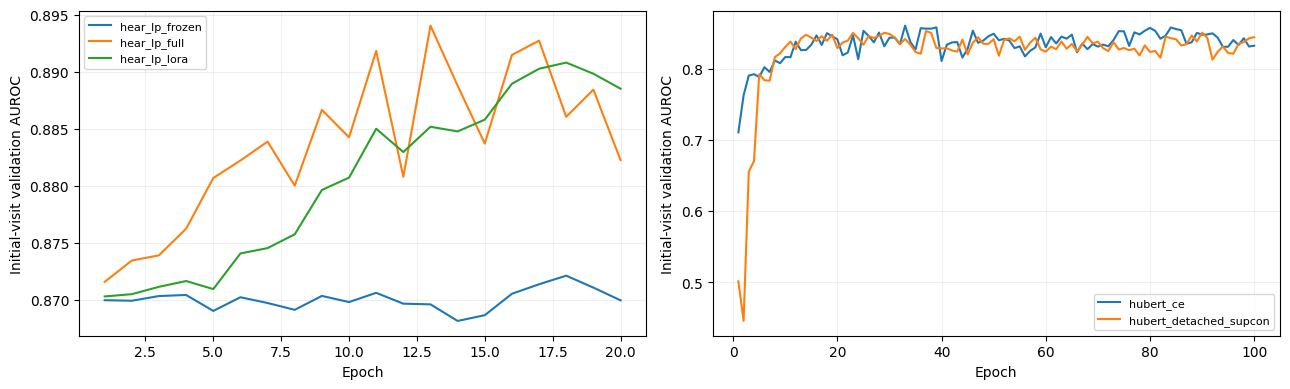

In [8]:
history = pd.read_csv(RESULTS/'literature_completed/learning_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for method, group in history.groupby('method', sort=False):
    axes[0 if method.startswith('hear') else 1].plot(group.epoch, group.auroc, label=method)
for ax in axes:
    ax.set(xlabel='Epoch', ylabel='Initial-visit validation AUROC')
    ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## I. Adjacent small-data classification: all 18 TabICL comparisons

Frozen HeAR/WhisperSmall/WavLMLarge embeddings, one initial training visit/person, StandardScaler+randomizedPCA fit on labeled context.
Full context3,397 people usesPCA128. HeAR label budgets50/100/500 usePCA16/33/128, respectively; fixedseed20261112,
independently sampled stratified contexts, not nested subsets. LR C∈{.001,.01,.1,1}, max_iter2000, three training-only groupedfolds
refitting scaler/PCA. TabICL2025 v1 uses32 estimators; TabICLv2 2026 uses8; library2.2.0, local checkpoint path, no auto-download,
no remote inference, no AMP/FA3, batch_size2/n_jobs4. No participant data are used to pretrain either foundation model.

Full-label WavLM: LR.8718, v1 .8743, v2 .8811. The paired v2−LR interval includes zero.
Compare classifiers **within** a budget; changing PCA dimension and one-seed context limits interpretation of the label-efficiency curve.
TabPFN was reviewed but not run; TabICL's explicit pinned BSD checkpoint was chosen for these controlled comparisons.

In [9]:
table('literature_tabular/metrics.csv')
report('literature_tabular/summary.json')
table('literature_tabular/lr_search_history.csv')

,encoder,labelled_train_people,train_PD,classifier,pca_dim,auroc,auprc,log_loss,brier,participants,threshold,specificity,sensitivity,controls,threshold_selection
0,hear,50,10,lr,16,0.604878,0.290454,0.489055,0.156108,729,0.265990,0.900515,0.178082,583,"validation; exploratory, not a locked test operating point"
1,hear,50,10,tabicl_v1,16,0.643941,0.303942,0.486362,0.155639,729,0.258037,0.900515,0.178082,583,"validation; exploratory, not a locked test operating point"
2,hear,50,10,tabicl_v2,16,0.654174,0.321523,0.477226,0.152656,729,0.275490,0.900515,0.226027,583,"validation; exploratory, not a locked test operating point"
3,hear,100,20,lr,33,0.671010,0.381224,0.472221,0.150336,729,0.264580,0.900515,0.273973,583,"validation; exploratory, not a locked test operating point"
4,hear,100,20,tabicl_v1,33,0.687187,0.435277,0.463943,0.147056,729,0.227487,0.900515,0.342466,583,"validation; exploratory, not a locked test operating point"
5,hear,100,20,tabicl_v2,33,0.632287,0.415063,0.469206,0.146502,729,0.338020,0.900515,0.301370,583,"validation; exploratory, not a locked test operating point"
6,hear,500,100,lr,128,0.791619,0.533623,0.433829,0.133583,729,0.412665,0.900515,0.472603,583,"validation; exploratory, not a locked test operating point"
7,hear,500,100,tabicl_v1,128,0.788106,0.512416,0.413131,0.130858,729,0.292622,0.900515,0.479452,583,"validation; exploratory, not a locked test operating point"
8,hear,500,100,tabicl_v2,128,0.798550,0.517810,0.406698,0.128019,729,0.343843,0.900515,0.445205,583,"validation; exploratory, not a locked test operating point"
9,hear,3397,679,lr,128,0.852158,0.633898,0.355430,0.108938,729,0.348486,0.900515,0.609589,583,"validation; exploratory, not a locked test operating point"


```json
{
  "status": "completed_development_panel",
  "comparisons": 18,
  "validation_participants": 729,
  "validation_PD": 146,
  "test_labels_read": false,
  "paired_comparisons": {
    "hear_v2_minus_LR": {
      "auroc_delta": 0.007730444794285529,
      "paired_component_bootstrap_95pct": [
        -0.0039569765899285046,
        0.021036537728164943
      ]
    },
    "whisper_small_v2_minus_LR": {
      "auroc_delta": -0.0021852017199651685,
      "paired_component_bootstrap_95pct": [
        -0.01642194911620936,
        0.010968937293627268
      ]
    },
    "wavlm_large_v2_minus_LR": {
      "auroc_delta": 0.009339975093399677,
      "paired_component_bootstrap_95pct": [
        -0.003403304286197789,
        0.02314911221694497
      ]
    },
    "wavlm_v2_minus_v1": {
      "auroc_delta": 0.006814069879461537,
      "paired_component_bootstrap_95pct": [
        -0.001980996777246746,
        0.015249418144300116
      ]
    },
    "hear_50_labels_v2_minus_LR": {
      "auroc_delta": 0.049296271059000474,
      "paired_component_bootstrap_95pct": [
        -0.0011490293704862929,
        0.10196853903874747
      ]
    },
    "hear_100_labels_v2_minus_LR": {
      "auroc_delta": -0.03872271434949137,
      "paired_component_bootstrap_95pct": [
        -0.08917286003040642,
        0.013880622987558948
      ]
    },
    "hear_500_labels_v2_minus_LR": {
      "auroc_delta": 0.00693155384290034,
      "paired_component_bootstrap_95pct": [
        -0.014559358629703246,
        0.030567954383124506
      ]
    }
  },
  "bootstrap_replicates": 2000,
  "training_context_seeds": [
    20261112
  ],
  "limitations": [
    "Exploratory validation; no correction for model selection or training-context seed variability.",
    "Single non-nested stratified context per budget; PCA dimensions vary. Compare classifiers within a budget, not a pure causal label-count effect.",
    "TabICL pretraining uses synthetic tables; small labelled context is not foundation training from scratch."
  ]
}
```

,encoder,labelled_train_people,selected,C,cv_auroc
0,hear,100,True,0.001,0.639918
1,hear,100,False,0.010,0.599105
2,hear,100,False,0.100,0.580202
3,hear,100,False,1.000,0.597906
4,hear,3397,False,0.001,0.823440
5,hear,3397,True,0.010,0.850373
6,hear,3397,False,0.100,0.848670
7,hear,3397,False,1.000,0.846035
8,hear,50,True,0.001,0.639805
9,hear,50,False,0.010,0.613248


,encoder,labelled_train_people,selected,C,cv_auroc
0,hear,100,True,0.001,0.639918
1,hear,100,False,0.010,0.599105
2,hear,100,False,0.100,0.580202
3,hear,100,False,1.000,0.597906
4,hear,3397,False,0.001,0.823440
5,hear,3397,True,0.010,0.850373
6,hear,3397,False,0.100,0.848670
7,hear,3397,False,1.000,0.846035
8,hear,50,True,0.001,0.639805
9,hear,50,False,0.010,0.613248


## J. GPU acoustic XGBoost: preprocessing, hyperparameter tree search and all diagnostics

All184 acoustic features, no participant/demographic/device/medication predictors. Source hashes matched the immutable manifest.
Primarytraining3,397 initial visits; nativeNaN branches, infinities→NaN; reject all-missing rows; no scaler/imputer/PCA.
Training-only3-fold StratifiedGroupKFold by participant/duplicate component;60 seeded multivariateTPE trials with12startup trials;
serial trials on oneGPU with4CPU helperthreads. Each CV fit permits2,500 rounds and earlystop75 on training-CV AUROC only.
Outer validation is never supplied to the search. Trial40 selected823trees, depth4, eta.0442857; all exact values below.

Tuned depth2–8, min_child_weight1–64log, eta.005–.2log, subsample.6–1, colsample.5–1,
lambda.001–100log, alpha1e-8–10log, gamma0–5, max_bin∈{128,256,512}. No class weighting.
Feature-family ablations and equal-person repeated-visit sensitivity reuse primary-selected settings; no extra validation search.
The repeatedfit uses43,702 visits with weight1/number_of_person_visits. LRreference: training-fold median imputer+missing indicators,
StandardScaler, C∈{.001,.01,.1,1}, groupedCV; selectedC1.

Official GPUXGBoost3.4.1 verified `cuda:0`/GPUhist at runtime, native model reload, SHAPcontribution sum to rawmargin.
Optuna4.6.0 SQLite/sampler checkpoints support deterministic resume. Smokejob27619782 and searchjob27619783 completed;
production search/diagnostics elapsed4m26s. Trees and per-person SHAP/predictions remain private.
Acoustic features use fullclips, unlike encoder10scap; the repeatedfit also uses more visits than the initialfit.

,experiment,features,boost_rounds,auroc,auprc,log_loss,brier,participants,threshold,specificity,sensitivity,controls,threshold_selection,chosen_C
0,acoustic_primary,184.0,823.0,0.816913,0.567437,0.412738,0.125106,729,0.276112,0.900515,0.520548,583,"validation; exploratory, not a locked test operating point",NaN
1,praat_only,44.0,823.0,0.714103,0.426282,0.467837,0.145332,729,0.340874,0.900515,0.328767,583,"validation; exploratory, not a locked test operating point",NaN
2,egemaps_only,88.0,823.0,0.797152,0.517169,0.426744,0.132238,729,0.325429,0.900515,0.431507,583,"validation; exploratory, not a locked test operating point",NaN
3,spectral_only,52.0,823.0,0.766430,0.467858,0.451075,0.137245,729,0.335842,0.900515,0.410959,583,"validation; exploratory, not a locked test operating point",NaN
4,missingness_only,184.0,823.0,0.518016,0.216776,0.495850,0.158162,729,0.195047,0.987993,0.047945,583,"validation; exploratory, not a locked test operating point",NaN
5,equal_person_repeated_visits,184.0,823.0,0.838048,0.612051,0.368083,0.114603,729,0.381120,0.900515,0.561644,583,"validation; exploratory, not a locked test operating point",NaN
6,logistic_reference,NaN,NaN,0.820966,0.562515,0.399991,0.120393,729,0.389258,0.900515,0.527397,583,"validation; exploratory, not a locked test operating point",1.0


```json
{
  "status": "completed_GPU_acoustic_XGBoost",
  "test_labels_read": false,
  "validation_people": 729,
  "validation_PD": 146,
  "train_people": 3397,
  "repeated_train_recordings": 43702,
  "feature_count": 184,
  "best_search": {
    "params": {
      "max_depth": 4,
      "min_child_weight": 1.4601136400747847,
      "eta": 0.04428572219201701,
      "subsample": 0.7513234299528642,
      "colsample_bytree": 0.9005279768547643,
      "lambda": 4.247342235624237,
      "alpha": 8.80283230032447e-07,
      "gamma": 0.6891017929793257,
      "max_bin": 128
    },
    "boost_rounds": 823,
    "cv_auroc": 0.8064482480332811,
    "cv_auc_std": 0.0034707328649586883,
    "trial": 40,
    "completed_trials": 60,
    "signature": "16ba52331ad9a12e6b963b3d27566cd9cb5d232ddcc6bb9fb2f421f9eb6861f2"
  },
  "paired_comparisons": {
    "primary_minus_logistic": {
      "auroc_difference": -0.004053196738645237,
      "paired_component_bootstrap_95pct": [
        -0.036819804086193904,
        0.028197466506127495
      ]
    },
    "repeated_minus_primary": {
      "auroc_difference": 0.021135365022674435,
      "paired_component_bootstrap_95pct": [
        -0.002704832147335423,
        0.043937314796761384
      ]
    },
    "repeated_minus_logistic": {
      "auroc_difference": 0.017082168284029198,
      "paired_component_bootstrap_95pct": [
        -0.010858337745066334,
        0.046059235308206534
      ]
    }
  },
  "GPU_verification": {
    "requested": "cuda",
    "actual": "cuda:0",
    "CUDA_build": true,
    "histogram_verified": true
  },
  "model_reload_verified": true,
  "SHAP_sum_verified": true,
  "uncertainty": "Exploratory validation intervals conditional on selected models; not corrected for model selection or training seeds.",
  "comparison_design": "Primary versus logistic uses initial training visits. Repeated-visit model uses more training recordings with equal-person weights and fixed primary hyperparameters.",
  "feature_span": "Existing full-clip acoustic measurements; not recomputed at encoder 10s cap."
}
```

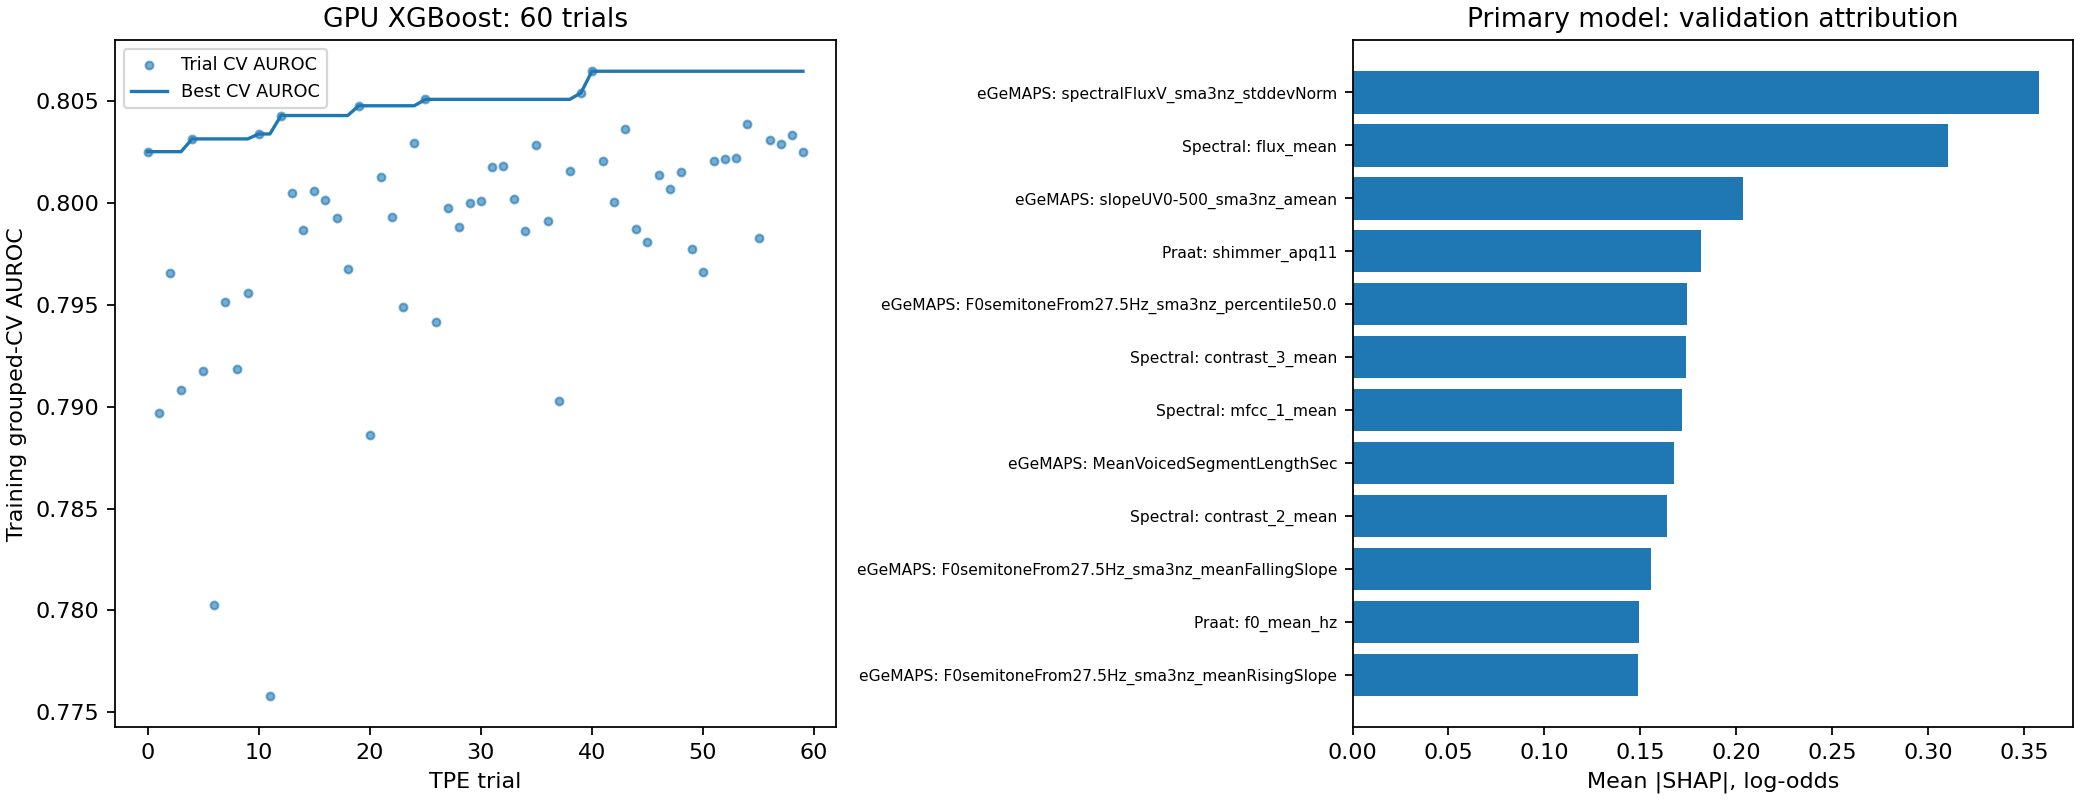

,number,value,params_alpha,params_colsample_bytree,params_eta,params_gamma,params_lambda,params_max_bin,params_max_depth,params_min_child_weight,params_subsample,user_attrs_boost_rounds,user_attrs_cv_auc_std,state
0,0,0.802503,1.000000e-02,0.800000,0.050000,0.000000,5.000000,256,3,5.000000,0.800000,595,0.005014,COMPLETE
1,1,0.789698,2.115397e-06,0.502410,0.009552,3.037548,90.549651,256,2,1.361873,0.781055,2500,0.005669,COMPLETE
2,2,0.796550,3.758377e-06,0.925571,0.011526,1.391173,0.100465,128,8,1.848690,0.800818,769,0.007944,COMPLETE
3,3,0.790819,3.445002e-02,0.544597,0.032025,3.129211,10.797886,512,4,2.357807,0.849828,256,0.002733,COMPLETE
4,4,0.803129,4.416684e-03,0.754482,0.133573,1.074317,38.797207,128,2,2.286442,0.731008,548,0.006762,COMPLETE
5,5,0.791759,2.117454e-08,0.940685,0.095985,3.167177,1.319762,512,6,11.362354,0.612133,197,0.002232,COMPLETE
6,6,0.780274,8.934899e-06,0.962127,0.135831,0.379125,0.002071,512,2,1.433742,0.693422,103,0.002355,COMPLETE
7,7,0.795122,2.399500e-01,0.898984,0.008845,3.053568,0.090473,512,6,54.302617,0.720488,2412,0.006177,COMPLETE
8,8,0.791858,1.522141e-01,0.913670,0.156911,3.698312,2.424934,512,6,33.009602,0.662838,185,0.005160,COMPLETE
9,9,0.795551,9.418869e-07,0.996405,0.050697,3.446784,3.084909,128,7,23.415589,0.882494,371,0.000994,COMPLETE


,feature,mean_abs_SHAP_log_odds,gain
0,egemaps__spectralFluxV_sma3nz_stddevNorm,0.357865,7.624072
1,spectral__flux_mean,0.310183,3.846681
2,egemaps__slopeUV0-500_sma3nz_amean,0.203588,3.882401
3,praat_full__shimmer_apq11,0.181656,4.201209
4,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,0.174234,8.101262
5,spectral__contrast_3_mean,0.173812,4.701400
6,spectral__mfcc_1_mean,0.171530,3.832895
7,egemaps__MeanVoicedSegmentLengthSec,0.167525,3.606843
8,spectral__contrast_2_mean,0.163891,4.863178
9,egemaps__F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,0.155609,6.289565


,feature,mean_abs_SHAP_log_odds,gain
0,egemaps__spectralFluxV_sma3nz_stddevNorm,0.357865,7.624072
1,spectral__flux_mean,0.310183,3.846681
2,egemaps__slopeUV0-500_sma3nz_amean,0.203588,3.882401
3,praat_full__shimmer_apq11,0.181656,4.201209
4,egemaps__F0semitoneFrom27.5Hz_sma3nz_percentile50.0,0.174234,8.101262
...,...,...,...
179,praat_stable__shimmer_dda,0.002909,4.570499
180,praat_stable__jitter_ddp,0.000792,1.313550
181,praat_stable__pitch_valid_fraction,0.000624,1.706847
182,praat_stable__unvoiced_fraction,0.000000,0.000000


In [10]:
table('acoustic_xgboost/metrics.csv')
report('acoustic_xgboost/summary.json')
figure('acoustic_xgboost/search_and_importance.png')
table('acoustic_xgboost/search_trials.csv')
table('acoustic_xgboost/feature_importance.csv')

## K. Interpretation, uncertainty and what remains unfinished

HeAR LP-FT and LoRA improve the matched head-only control on this validation cohort; detached HuBERT SupCon does not.
Acoustic initialvisitXGBoost does not beat matchedLR; repeatedvisitXGBoost is higher but changes training exposure and its pairedinterval includeszero.
Age/device strongly predict labels. Audio model scores alone cannot establish added disease-specific value.

Bootstrap intervals resample validation duplicate-connected components (here each of729 components is one person),2,000replicates,
seed20261116. They condition on fitted/selected models; they do not correct repeated validation selection, epoch selection,
hyperparameter search, training-seed variability or multiple comparisons. AUROC is ranking, AP depends on prevalence,
logloss/Brier assess probability quality, and sensitivity depends on the development-selected operating threshold.
Missingness-only XGBoost has tied predictions and achieved98.8% specificity, so its sensitivity is not an exact90%-specificity comparison.

No independent final-test results are released. No five-seed replication has been completed.
Near-duplicate/task review, demographic-common-support and device robustness, multiseed checks and a locked final protocol remain required.
Whisper/acoustic paired alignment and proposed quality/medication weighting are documented prototypes, not trained winners.
No unsupported claim of reproducing another cohort's clinical SOTA is made.

## L. Execution failures and their resolution

| Event | Cause / outcome |
|---|---|
| Initial full acoustic run timed out | Worker/Librosa-Numba zero-crossing path failed; repaired deterministic NumPy ZCR and bounded CPU parallelism; completed full retry. |
| Remaining49 source decode failures | Matched original Synapse object sizes/checksums; normal/error-tolerant decoding produced no samples. Preserved failures. |
| Initial pretrained downloads | Historical networking/cache failures; later pinned downloads and offlineGPU smoke completed. |
| HeAR access403 | Model-gate access not granted initially; authorized download and hash verification later completed; all current HeAR runs finished. |
| Original AST comparison | HeadLR and warm-up checkpoint confounds; corrected paired runner and separate phase labels. |
| First HuBERT literature load | Disabling masking before nativeconstruction hid a tensor; fixed fullnative load, then disabled augmentation on actual copiedconfig. Cancelled partial run excluded. |
| CPU-onlyXGBoost build | Replaced with officialGPU3.4.1 wheel in privateenv; rejectedCPU fallback in production. |
| Optuna/SQLite import ABI | Child-process-only libstdc++ preload wrapper; no global system changes. |

Relevant synthetic checks verify split refusal, transforms/weights, native batching/padding, LoRA identity/base invariance,
LP prediction equivalence, SupCon gradient routes, exactresume, GPUfallback rejection and searchresumption. Passing software checks
establishes execution correctness for their scope, not clinical validity.

## M. Exact configuration and provenance appendix

The checked-in YAML below records declared schedules/search spaces; aggregate run provenance records actual selected epochs,
parameter-update audits and versions. Historical design-only YAML is explicitly marked and does not prove execution.
Native checkpoint locks retain revisions and asset hashes. The completed snapshot remains immutable even if working templates change.

### `configs/mpower_preprocessing.yaml`

```yaml
# Paths are resolved from environment; derived participant data stay outside Git.
data_root_env: MPOWER_DATA_ROOT
output_root_env: MPOWER_OUTPUT_ROOT
metadata: voice_activity/Voice_Activity.csv
demographics: demographics/Demographics.csv
columns:
  participant: healthCode
  recording: recordId
  timestamp: createdOn
  audio: audio_path
  handle: audio_audio.m4a
  medication: medTimepoint
  # Unavailable in the inspected Voice Activity table. Configure only after auditing.
  diagnosis: null
  age: null
  sex: null
# Explicit value mappings; medication is never used as a diagnosis proxy.
diagnosis_values:
  pd: ['true']
  control: ['false']
seed: 20261112
pilot_size: 120
workers: 2
sample_rate: 16000
max_decode_seconds: 180
pitch:
  floor: 60
  ceiling: 500
  max_period_factor: 1.3
  max_amplitude_factor: 1.6
  sensitivity_ranges: [[50, 400], [75, 600]]
qc:
  frame_ms: 30
  hop_ms: 10
  near_silence_rms: 0.0001
  low_amplitude_rms: 0.001
  energy_db_below_peak: 35
  min_duration_s: 2
  min_voiced_s: 2
  clipping_amplitude: 0.999
  clipping_fraction: 0.01
  estimated_snr_db: 10
  min_pitch_fraction: 0.5
split_fractions: [0.70, 0.15, 0.15]
age_restriction: [50, 80]

```

### `configs/frozen_model_testing.yaml`

```yaml
seed: 20261112
threads: 4
device: auto
mixed_precision: false
data_root_env: MPOWER_DATA_ROOT
eda_root_env: MPOWER_OUTPUT_ROOT
benchmark_root_env: MPOWER_BENCHMARK_ROOT
manifest: null
cohort: B
quality:
  min_duration_s: 2
  reject_flags:
  - flag_near_silent
  - flag_short
audio:
  sample_rate: 16000
  segment_seconds: 10
  hop_seconds: 10
  max_decode_seconds: 180
  max_segments: 12
batch_size: 1
participant_aggregation: mean
pooling: mean
layers:
- -1
heads:
- logistic
- mlp
head:
  max_iter: 300
  hidden_dim: 64
  epochs: 10
  learning_rate: 0.001
  weight_decay: 0.0001
  batch_size: 256
  cv_folds: 3
  C_grid:
  - 0.01
  - 0.1
  - 1.0
  specificity_target: 0.9
split_fractions:
- 0.7
- 0.15
- 0.15
smoke_participants_per_class: 1
models:
  ast_audioset:
    checkpoint: MIT/ast-finetuned-audioset-10-10-0.4593
    revision: f826b80d28226b62986cc218e5cec390b1096902
    local_alias: ast_audioset
  hubert_large:
    checkpoint: facebook/hubert-large-ll60k
    revision: ff022d095678a2995f3c49bab18a96a9e553f782
    local_alias: hubert_large
  wav2vec2_base_960h:
    checkpoint: facebook/wav2vec2-base-960h
    revision: 22aad52d435eb6dbaf354bdad9b0da84ce7d6156
    local_alias: wav2vec2_base_960h
  wav2vec2_large_robust:
    checkpoint: facebook/wav2vec2-large-robust
    revision: 2493a2c576276145c3e066d9243b0e391fab673a
    local_alias: wav2vec2_large_robust
  wavlm_base_plus:
    checkpoint: microsoft/wavlm-base-plus
    revision: 4c66d4806a428f2e922ccfa1a962776e232d487b
    local_alias: wavlm_base_plus
  wavlm_large:
    checkpoint: microsoft/wavlm-large
    revision: c1423ed94bb01d80a3f5ce5bc39f6026a0f4828c
    local_alias: wavlm_large
  whisper_large_v3:
    checkpoint: openai/whisper-large-v3
    revision: 06f233fe06e710322aca913c1bc4249a0d71fce1
    local_alias: whisper_large_v3
  whisper_medium:
    checkpoint: openai/whisper-medium
    revision: abdf7c39ab9d0397620ccaea8974cc764cd0953e
    local_alias: whisper_medium
  whisper_small:
    checkpoint: openai/whisper-small
    revision: 973afd24965f72e36ca33b3055d56a652f456b4d
    local_alias: whisper_small
model_root_env: MPOWER_MODEL_ROOT
require_gpu: true
feature_taps:
  audio-spectrogram-transformer:
  - native_pooler
  - patches
  whisper:
  - last_hidden
  - block_middle
  wav2vec2:
  - last_hidden
  - block_middle
  - conv_normalized
  wavlm:
  - last_hidden
  - block_middle
  - conv_normalized
  hubert:
  - last_hidden
  - block_middle
  - conv_normalized
protocol:
  span: first_10s
  contexts:
  - full
  - matched_2s
  primary_cohort: technical A >=2s; source-column task; provisional
  primary_assessment: first eligible recording per validation participant
  train_weight: inverse recording count per training participant
  selection_metric: validation participant AUROC
  shortlist: 2
  max_peak_gpu_gib: 32
  max_seconds_per_recording: 30
  tie_break:
  - log_loss
  - lexical_name
  seed: 20261112
  final_test: sealed
  fine_tuning: separate later stage after prespecified shortlist

```

### `configs/adaptation_run.yaml`

```yaml
seed: 20261112
head_epochs: 10
adaptation_epochs: 20
effective_batch_size: 32
partial_backbone_lr: 0.000005
head_lr: 0.0001
max_grad_norm: 1.0
smoke_participants_per_cell: 4
runs:
- {model: ast_audioset, policy: frozen}
- {model: ast_audioset, policy: last2}
- {model: ast_audioset, policy: full}
- {model: resnet50, policy: frozen}
- {model: resnet50, policy: last3}
- {model: resnet50, policy: full}
- {model: wav2vec2_base_960h, policy: last2}
- {model: wav2vec2_base_960h, policy: last4}
- {model: wav2vec2_large_robust, policy: last2}
- {model: wav2vec2_large_robust, policy: last4}
- {model: wavlm_base_plus, policy: last2}
- {model: wavlm_base_plus, policy: last4}
- {model: wavlm_large, policy: last2}
- {model: wavlm_large, policy: last4}

```

### `configs/ast_controlled_finetuning.yaml`

```yaml
seed: 20261112
model: ast_audioset
head_kind: layernorm_linear
optimizer: sgd
weight_decay: 0.01
warmup_epochs: 10
adaptation_epochs: 20
warmup_head_lr: 0.001
adapt_head_lr: 0.001
head_min_lr: 0.00001
backbone_lr: 0.00001
backbone_min_lr: 0.000001
effective_batch_size: 32
microbatch_size: 4
max_grad_norm: 1.0
policies: [frozen, last2, full]
selection_metric: validation_initial_assessment_AUROC_then_log_loss
final_test: sealed
interpretation: controlled_AST_experiment_not_exact_paper_replication

```

### `configs/hear_protocol.yaml`

```yaml
seed: 20261112
model: hear_pytorch
head_kind: layernorm_linear
optimizer: adamw
weight_decay: 0.01
warmup_epochs: 10
adaptation_epochs: 20
warmup_head_lr: 0.0001
adapt_head_lr: 0.0001
head_min_lr: 0.00001
backbone_lr: 0.000005
backbone_min_lr: 0.000001
effective_batch_size: 32
microbatch_size: 1
max_grad_norm: 1.0
policies: [frozen, last2, full]
# Verified against the pinned, fully loaded 24-block ViT checkpoint.
block_path: encoder.layer
final_test: sealed
interpretation: proposed_controlled_HeAR_experiment_not_paper_replication

```

### `configs/literature_benchmarks.yaml`

```yaml
# Source methodology cards are in docs/literature/. These are mPower adaptations.
seed: 20261112
methods:
  hear_lp_frozen:
    family: hear_lpft
    policy: frozen
    objective: bce
    epochs: 20
    head_lr: 0.0001
    backbone_lr: 0.000005
    weight_decay: 0.01
    batch_size: 32
    microbatch_size: 1
    gradient_checkpointing: false
    interpretation: strong_converged_LP_head_only_control
  hear_lp_full:
    family: hear_lpft
    policy: full
    objective: bce
    epochs: 20
    head_lr: 0.0001
    backbone_lr: 0.000005
    weight_decay: 0.01
    batch_size: 32
    microbatch_size: 1
    gradient_checkpointing: true
    interpretation: LP_FT_method_adapted_from_Kumar_ICLR2022_not_original_dataset_replication
  hear_lp_lora:
    family: hear_lpft
    policy: lora
    objective: bce
    epochs: 20
    head_lr: 0.0001
    backbone_lr: 0.0001
    weight_decay: 0.01
    batch_size: 32
    microbatch_size: 1
    gradient_checkpointing: true
    lora_rank: 8
    lora_alpha: 16
    lora_dropout: 0.0
    interpretation: QV_LoRA_from_converged_LP_original_LoRA_math_with_project_HeAR_hyperparameters
  hubert_ce:
    family: hubert_supcon
    policy: full
    objective: ce
    epochs: 100
    head_lr: 0.00002
    backbone_lr: 0.00002
    weight_decay: 0.01
    batch_size: 32
    microbatch_size: 1
    gradient_checkpointing: true
    interpretation: NeuroVoz_paper_mechanism_control_adapted_to_mPower_vowels_frozen_CNN_no_unspecified_filtering
  hubert_detached_supcon:
    family: hubert_supcon
    policy: full
    objective: detached_supcon
    epochs: 100
    head_lr: 0.00002
    backbone_lr: 0.00002
    weight_decay: 0.01
    batch_size: 32
    microbatch_size: 1
    gradient_checkpointing: true
    temperature: 0.07
    interpretation: NeuroVoz_detached_CE_encoder_SupCon_unscaled_adaptation_missing_mining_formula_not_exact_replication
final_test: sealed
declared_deviations:
  - mPower_sustained_vowels_instead_of_NeuroVoz_repeated_sentences
  - fixed_participant_duplicate_component_development_splits_instead_of_original_dataset_split
  - HuBERT_CNN_frozen_in_both_speech_arms_as_project_choice
  - speech_first_up_to_5_real_seconds_no_padding_or_unspecified_lowpass_filter
  - balanced_distinct_people_and_duplicate_masks_for_SupCon
  - speech_CE_importance_weighted_to_training_person_prevalence
  - projection_single_linear32_depth_unspecified_by_paper
  - no_hard_negative_factor_because_mining_formula_unavailable
  - fixed_AdamW_LR_no_invented_scheduler
  - gradient_clip_norm1_project_stability_choice
  - LoRA_head_and_adapter_LRs_differ_from_full_backbone_LR

```

### `configs/acoustic_xgboost.yaml`

```yaml
seed: 20261112
device: cuda
threads: 4
cv_folds: 3
trials: 60
max_rounds: 2500
early_stopping_rounds: 75
primary_training: canonical_initial_visit_per_participant
selection: training_grouped_CV_AUROC_only
missing_values: native_XGBoost_missing_branches_no_validation_imputation
search_algorithm: seeded_multivariate_TPE
class_weight: none
diagnostics: [praat_only, egemaps_only, spectral_only, missingness_only]
repeated_visit_sensitivity: same_selected_hyperparameters_equal_person_weight
final_test: sealed

```

In [11]:
report('native_frontends.json')
report('literature_completed/provenance.json')
report('historical_adaptation/configurations.json')

```json
{
  "whisper_large_v3": {
    "chunk_length": 30,
    "feature_extractor_type": "WhisperFeatureExtractor",
    "feature_size": 128,
    "hop_length": 160,
    "n_fft": 400,
    "n_samples": 480000,
    "nb_max_frames": 3000,
    "padding_side": "right",
    "padding_value": 0.0,
    "processor_class": "WhisperProcessor",
    "return_attention_mask": false,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "7ccc62c6f2765af1f3b46c00c9b5894426835a05021c8b9c01eecb6dfb542711"
  },
  "whisper_small": {
    "chunk_length": 30,
    "feature_extractor_type": "WhisperFeatureExtractor",
    "feature_size": 80,
    "hop_length": 160,
    "mel_filters": {
      "shape": [
        80,
        201
      ],
      "canonical_json_sha256": "caf5779874f82b52482dfa6e753a45d35181e78bb2bbbccdfd0c226c2a6410c1",
      "note": "Native checkpoint matrix retained in original asset; report summarizes rather than prints every constant."
    },
    "n_fft": 400,
    "n_samples": 480000,
    "nb_max_frames": 3000,
    "padding_side": "right",
    "padding_value": 0.0,
    "processor_class": "WhisperProcessor",
    "return_attention_mask": false,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "9b5cd03a36fbb8a627c64d98a5b5b126ead95a77720723944487311f0110b666"
  },
  "ast_audioset": {
    "do_normalize": true,
    "feature_extractor_type": "ASTFeatureExtractor",
    "feature_size": 1,
    "max_length": 1024,
    "mean": -4.2677393,
    "num_mel_bins": 128,
    "padding_side": "right",
    "padding_value": 0.0,
    "return_attention_mask": false,
    "sampling_rate": 16000,
    "std": 4.5689974,
    "preprocessor_config_sha256": "8d04ba5a9c6fca5d39d0de2b1fd05ecf79deb589fbba279728bbebac39934231"
  },
  "whisper_medium": {
    "chunk_length": 30,
    "feature_extractor_type": "WhisperFeatureExtractor",
    "feature_size": 80,
    "hop_length": 160,
    "mel_filters": {
      "shape": [
        80,
        201
      ],
      "canonical_json_sha256": "caf5779874f82b52482dfa6e753a45d35181e78bb2bbbccdfd0c226c2a6410c1",
      "note": "Native checkpoint matrix retained in original asset; report summarizes rather than prints every constant."
    },
    "n_fft": 400,
    "n_samples": 480000,
    "nb_max_frames": 3000,
    "padding_side": "right",
    "padding_value": 0.0,
    "processor_class": "WhisperProcessor",
    "return_attention_mask": false,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "9b5cd03a36fbb8a627c64d98a5b5b126ead95a77720723944487311f0110b666"
  },
  "wavlm_large": {
    "do_normalize": true,
    "feature_extractor_type": "Wav2Vec2FeatureExtractor",
    "feature_size": 1,
    "padding_side": "right",
    "padding_value": 0.0,
    "return_attention_mask": true,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "60ca5a31e13f69ee2fbf147504c8676db5f6398fd7a6b12294341dff838edfcf"
  },
  "hubert_large": {
    "do_normalize": true,
    "feature_extractor_type": "Wav2Vec2FeatureExtractor",
    "feature_size": 1,
    "padding_side": "right",
    "padding_value": 0,
    "return_attention_mask": true,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "a2254a5b58f72cd4de3632f8eee64f3f098b7c1402128d2f419e7d00ae13e335"
  },
  "wav2vec2_large_robust": {
    "do_normalize": true,
    "feature_size": 1,
    "padding_side": "right",
    "padding_value": 0.0,
    "return_attention_mask": true,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "c403ce09975b90dff0dd8302c42d422e9de1f166cd7772df23490069893cb0cf"
  },
  "wavlm_base_plus": {
    "do_normalize": false,
    "feature_extractor_type": "Wav2Vec2FeatureExtractor",
    "feature_size": 1,
    "padding_side": "right",
    "padding_value": 0.0,
    "return_attention_mask": true,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "99272fe8ccfab114b68b478681ea47ee3a1ce62bb788cb92dd6e4f69fb1f1da2"
  },
  "wav2vec2_base_960h": {
    "do_normalize": true,
    "feature_size": 1,
    "padding_side": "right",
    "padding_value": 0.0,
    "return_attention_mask": false,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "b225d617c025463b9e157e06afea8b90dc7078fc70b013c533328423e0486b4a"
  },
  "hubert_base_ls960": {
    "do_normalize": true,
    "feature_extractor_type": "Wav2Vec2FeatureExtractor",
    "feature_size": 1,
    "padding_side": "right",
    "padding_value": 0,
    "return_attention_mask": false,
    "sampling_rate": 16000,
    "preprocessor_config_sha256": "4a93853b74278b7c769d07f5a861e5d12ceb5db2bced5620d335f87238cb9e86"
  },
  "hear_pytorch": {
    "source": "src/models/hear_vendor/audio_utils.py; pinned source revision in provenance appendix",
    "sample_rate": 16000,
    "real_samples_per_window": 32000,
    "waveform_normalization": "minmax to [-1,1] independently per cloned window; epsilon1e-8",
    "frame_length": 400,
    "fft_length": 400,
    "frame_step": 160,
    "window": "periodic Hann",
    "pad_end": true,
    "spectral_power": 2,
    "mel_bins": 128,
    "mel_scale": "HTK",
    "mel_min_hz": 0,
    "mel_max_hz": 8000,
    "PCEN": {
      "alpha": 0.8,
      "smooth_coef": 0.04,
      "delta": 2.0,
      "root": 2.0,
      "floor": 1e-08
    },
    "resize": "TF-compatible bilinear to [1,192,128]; no antialias",
    "recording_pool": "equal-window mean512D or mean+populationSD1024D"
  }
}
```

```json
{
  "hear_lp_frozen": {
    "config": {
      "family": "hear_lpft",
      "policy": "frozen",
      "objective": "bce",
      "epochs": 20,
      "head_lr": 0.0001,
      "backbone_lr": 5e-06,
      "weight_decay": 0.01,
      "batch_size": 32,
      "microbatch_size": 1,
      "gradient_checkpointing": false,
      "interpretation": "strong_converged_LP_head_only_control",
      "method": "hear_lp_frozen",
      "seed": 20261112,
      "declared_deviations": [
        "mPower_sustained_vowels_instead_of_NeuroVoz_repeated_sentences",
        "fixed_participant_duplicate_component_development_splits_instead_of_original_dataset_split",
        "HuBERT_CNN_frozen_in_both_speech_arms_as_project_choice",
        "speech_first_up_to_5_real_seconds_no_padding_or_unspecified_lowpass_filter",
        "balanced_distinct_people_and_duplicate_masks_for_SupCon",
        "speech_CE_importance_weighted_to_training_person_prevalence",
        "projection_single_linear32_depth_unspecified_by_paper",
        "no_hard_negative_factor_because_mining_formula_unavailable",
        "fixed_AdamW_LR_no_invented_scheduler",
        "gradient_clip_norm1_project_stability_choice",
        "LoRA_head_and_adapter_LRs_differ_from_full_backbone_LR"
      ],
      "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
      "lp_head_sha256": "4739400adfdf98fd1475b32e9c89fe57f32cde40a956371411a13a34cd9ff128",
      "lp_source_signature": "b972f634221390a990b1bbc5f1eb15a39520f3b9b9746dcbd9fd6b44230d4204",
      "model_revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "converged_LP_prediction_equivalence_verified": true
    },
    "asset": {
      "repo_id": "google/hear-pytorch",
      "revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "gated": "auto",
      "files": [
        {
          "name": "README.md",
          "bytes": 12423,
          "sha256": null,
          "git_blob": "0e816d6f46274ef526c84eed82ff650c9725178e"
        },
        {
          "name": "config.json",
          "bytes": 533,
          "sha256": null,
          "git_blob": "c4b37afd6b7c262c494f97f6e9b3d1984672daa7"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1212947234,
          "sha256": "d44d355816ee4315f67d7810da274409e9b1a6570325fc5ba9ae27555fd81723",
          "git_blob": null
        }
      ]
    },
    "lora_targets": [],
    "torch": "2.15.0+cu132",
    "claim": "method_adaptation_not_original_paper_SOTA_reproduction"
  },
  "hear_lp_full": {
    "config": {
      "family": "hear_lpft",
      "policy": "full",
      "objective": "bce",
      "epochs": 20,
      "head_lr": 0.0001,
      "backbone_lr": 5e-06,
      "weight_decay": 0.01,
      "batch_size": 32,
      "microbatch_size": 1,
      "gradient_checkpointing": true,
      "interpretation": "LP_FT_method_adapted_from_Kumar_ICLR2022_not_original_dataset_replication",
      "method": "hear_lp_full",
      "seed": 20261112,
      "declared_deviations": [
        "mPower_sustained_vowels_instead_of_NeuroVoz_repeated_sentences",
        "fixed_participant_duplicate_component_development_splits_instead_of_original_dataset_split",
        "HuBERT_CNN_frozen_in_both_speech_arms_as_project_choice",
        "speech_first_up_to_5_real_seconds_no_padding_or_unspecified_lowpass_filter",
        "balanced_distinct_people_and_duplicate_masks_for_SupCon",
        "speech_CE_importance_weighted_to_training_person_prevalence",
        "projection_single_linear32_depth_unspecified_by_paper",
        "no_hard_negative_factor_because_mining_formula_unavailable",
        "fixed_AdamW_LR_no_invented_scheduler",
        "gradient_clip_norm1_project_stability_choice",
        "LoRA_head_and_adapter_LRs_differ_from_full_backbone_LR"
      ],
      "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
      "lp_head_sha256": "4739400adfdf98fd1475b32e9c89fe57f32cde40a956371411a13a34cd9ff128",
      "lp_source_signature": "b972f634221390a990b1bbc5f1eb15a39520f3b9b9746dcbd9fd6b44230d4204",
      "model_revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "converged_LP_prediction_equivalence_verified": true
    },
    "asset": {
      "repo_id": "google/hear-pytorch",
      "revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "gated": "auto",
      "files": [
        {
          "name": "README.md",
          "bytes": 12423,
          "sha256": null,
          "git_blob": "0e816d6f46274ef526c84eed82ff650c9725178e"
        },
        {
          "name": "config.json",
          "bytes": 533,
          "sha256": null,
          "git_blob": "c4b37afd6b7c262c494f97f6e9b3d1984672daa7"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1212947234,
          "sha256": "d44d355816ee4315f67d7810da274409e9b1a6570325fc5ba9ae27555fd81723",
          "git_blob": null
        }
      ]
    },
    "lora_targets": [],
    "torch": "2.15.0+cu132",
    "claim": "method_adaptation_not_original_paper_SOTA_reproduction"
  },
  "hear_lp_lora": {
    "config": {
      "family": "hear_lpft",
      "policy": "lora",
      "objective": "bce",
      "epochs": 20,
      "head_lr": 0.0001,
      "backbone_lr": 0.0001,
      "weight_decay": 0.01,
      "batch_size": 32,
      "microbatch_size": 1,
      "gradient_checkpointing": true,
      "lora_rank": 8,
      "lora_alpha": 16,
      "lora_dropout": 0.0,
      "interpretation": "QV_LoRA_from_converged_LP_original_LoRA_math_with_project_HeAR_hyperparameters",
      "method": "hear_lp_lora",
      "seed": 20261112,
      "declared_deviations": [
        "mPower_sustained_vowels_instead_of_NeuroVoz_repeated_sentences",
        "fixed_participant_duplicate_component_development_splits_instead_of_original_dataset_split",
        "HuBERT_CNN_frozen_in_both_speech_arms_as_project_choice",
        "speech_first_up_to_5_real_seconds_no_padding_or_unspecified_lowpass_filter",
        "balanced_distinct_people_and_duplicate_masks_for_SupCon",
        "speech_CE_importance_weighted_to_training_person_prevalence",
        "projection_single_linear32_depth_unspecified_by_paper",
        "no_hard_negative_factor_because_mining_formula_unavailable",
        "fixed_AdamW_LR_no_invented_scheduler",
        "gradient_clip_norm1_project_stability_choice",
        "LoRA_head_and_adapter_LRs_differ_from_full_backbone_LR"
      ],
      "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
      "lp_head_sha256": "4739400adfdf98fd1475b32e9c89fe57f32cde40a956371411a13a34cd9ff128",
      "lp_source_signature": "b972f634221390a990b1bbc5f1eb15a39520f3b9b9746dcbd9fd6b44230d4204",
      "model_revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "converged_LP_prediction_equivalence_verified": true
    },
    "asset": {
      "repo_id": "google/hear-pytorch",
      "revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "gated": "auto",
      "files": [
        {
          "name": "README.md",
          "bytes": 12423,
          "sha256": null,
          "git_blob": "0e816d6f46274ef526c84eed82ff650c9725178e"
        },
        {
          "name": "config.json",
          "bytes": 533,
          "sha256": null,
          "git_blob": "c4b37afd6b7c262c494f97f6e9b3d1984672daa7"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1212947234,
          "sha256": "d44d355816ee4315f67d7810da274409e9b1a6570325fc5ba9ae27555fd81723",
          "git_blob": null
        }
      ]
    },
    "lora_targets": [
      "encoder.layer.0.attention.attention.query",
      "encoder.layer.0.attention.attention.value",
      "encoder.layer.1.attention.attention.query",
      "encoder.layer.1.attention.attention.value",
      "encoder.layer.2.attention.attention.query",
      "encoder.layer.2.attention.attention.value",
      "encoder.layer.3.attention.attention.query",
      "encoder.layer.3.attention.attention.value",
      "encoder.layer.4.attention.attention.query",
      "encoder.layer.4.attention.attention.value",
      "encoder.layer.5.attention.attention.query",
      "encoder.layer.5.attention.attention.value",
      "encoder.layer.6.attention.attention.query",
      "encoder.layer.6.attention.attention.value",
      "encoder.layer.7.attention.attention.query",
      "encoder.layer.7.attention.attention.value",
      "encoder.layer.8.attention.attention.query",
      "encoder.layer.8.attention.attention.value",
      "encoder.layer.9.attention.attention.query",
      "encoder.layer.9.attention.attention.value",
      "encoder.layer.10.attention.attention.query",
      "encoder.layer.10.attention.attention.value",
      "encoder.layer.11.attention.attention.query",
      "encoder.layer.11.attention.attention.value",
      "encoder.layer.12.attention.attention.query",
      "encoder.layer.12.attention.attention.value",
      "encoder.layer.13.attention.attention.query",
      "encoder.layer.13.attention.attention.value",
      "encoder.layer.14.attention.attention.query",
      "encoder.layer.14.attention.attention.value",
      "encoder.layer.15.attention.attention.query",
      "encoder.layer.15.attention.attention.value",
      "encoder.layer.16.attention.attention.query",
      "encoder.layer.16.attention.attention.value",
      "encoder.layer.17.attention.attention.query",
      "encoder.layer.17.attention.attention.value",
      "encoder.layer.18.attention.attention.query",
      "encoder.layer.18.attention.attention.value",
      "encoder.layer.19.attention.attention.query",
      "encoder.layer.19.attention.attention.value",
      "encoder.layer.20.attention.attention.query",
      "encoder.layer.20.attention.attention.value",
      "encoder.layer.21.attention.attention.query",
      "encoder.layer.21.attention.attention.value",
      "encoder.layer.22.attention.attention.query",
      "encoder.layer.22.attention.attention.value",
      "encoder.layer.23.attention.attention.query",
      "encoder.layer.23.attention.attention.value"
    ],
    "torch": "2.15.0+cu132",
    "claim": "method_adaptation_not_original_paper_SOTA_reproduction"
  },
  "hubert_ce": {
    "config": {
      "family": "hubert_supcon",
      "policy": "full",
      "objective": "ce",
      "epochs": 100,
      "head_lr": 2e-05,
      "backbone_lr": 2e-05,
      "weight_decay": 0.01,
      "batch_size": 32,
      "microbatch_size": 1,
      "gradient_checkpointing": true,
      "interpretation": "NeuroVoz_paper_mechanism_control_adapted_to_mPower_vowels_frozen_CNN_no_unspecified_filtering",
      "method": "hubert_ce",
      "seed": 20261112,
      "declared_deviations": [
        "mPower_sustained_vowels_instead_of_NeuroVoz_repeated_sentences",
        "fixed_participant_duplicate_component_development_splits_instead_of_original_dataset_split",
        "HuBERT_CNN_frozen_in_both_speech_arms_as_project_choice",
        "speech_first_up_to_5_real_seconds_no_padding_or_unspecified_lowpass_filter",
        "balanced_distinct_people_and_duplicate_masks_for_SupCon",
        "speech_CE_importance_weighted_to_training_person_prevalence",
        "projection_single_linear32_depth_unspecified_by_paper",
        "no_hard_negative_factor_because_mining_formula_unavailable",
        "fixed_AdamW_LR_no_invented_scheduler",
        "gradient_clip_norm1_project_stability_choice",
        "LoRA_head_and_adapter_LRs_differ_from_full_backbone_LR"
      ],
      "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
      "model_revision": "dba3bb02fda4248b6e082697eee756de8fe8aa8a",
      "actual_encoder_augmentation": {
        "mask_time_prob": 0.0,
        "mask_feature_prob": 0.0,
        "layerdrop": 0.0
      }
    },
    "asset": {
      "repo_id": "facebook/hubert-base-ls960",
      "revision": "dba3bb02fda4248b6e082697eee756de8fe8aa8a",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 2596,
          "sha256": null,
          "git_blob": "1e39166dd1c0b9bc1d66ecbeddf074c788dea1df"
        },
        {
          "name": "config.json",
          "bytes": 1385,
          "sha256": null,
          "git_blob": "5d89400e973a3e0330ca2f517e65d3231e44c762"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 213,
          "sha256": null,
          "git_blob": "8df8da1de6563b3f11638f4df5f2336f4ca94c04"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 377569754,
          "sha256": "062249fffb353eab67547a2fbc129f7c31a2f459faf641b19e8fb007cc5c48ad",
          "git_blob": null
        }
      ],
      "loading_info": {
        "missing_keys": [],
        "unexpected_keys": [],
        "mismatched_keys": [],
        "error_msgs": []
      }
    },
    "lora_targets": [],
    "torch": "2.15.0+cu132",
    "claim": "method_adaptation_not_original_paper_SOTA_reproduction"
  },
  "hubert_detached_supcon": {
    "config": {
      "family": "hubert_supcon",
      "policy": "full",
      "objective": "detached_supcon",
      "epochs": 100,
      "head_lr": 2e-05,
      "backbone_lr": 2e-05,
      "weight_decay": 0.01,
      "batch_size": 32,
      "microbatch_size": 1,
      "gradient_checkpointing": true,
      "temperature": 0.07,
      "interpretation": "NeuroVoz_detached_CE_encoder_SupCon_unscaled_adaptation_missing_mining_formula_not_exact_replication",
      "method": "hubert_detached_supcon",
      "seed": 20261112,
      "declared_deviations": [
        "mPower_sustained_vowels_instead_of_NeuroVoz_repeated_sentences",
        "fixed_participant_duplicate_component_development_splits_instead_of_original_dataset_split",
        "HuBERT_CNN_frozen_in_both_speech_arms_as_project_choice",
        "speech_first_up_to_5_real_seconds_no_padding_or_unspecified_lowpass_filter",
        "balanced_distinct_people_and_duplicate_masks_for_SupCon",
        "speech_CE_importance_weighted_to_training_person_prevalence",
        "projection_single_linear32_depth_unspecified_by_paper",
        "no_hard_negative_factor_because_mining_formula_unavailable",
        "fixed_AdamW_LR_no_invented_scheduler",
        "gradient_clip_norm1_project_stability_choice",
        "LoRA_head_and_adapter_LRs_differ_from_full_backbone_LR"
      ],
      "manifest_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
      "model_revision": "dba3bb02fda4248b6e082697eee756de8fe8aa8a",
      "actual_encoder_augmentation": {
        "mask_time_prob": 0.0,
        "mask_feature_prob": 0.0,
        "layerdrop": 0.0
      }
    },
    "asset": {
      "repo_id": "facebook/hubert-base-ls960",
      "revision": "dba3bb02fda4248b6e082697eee756de8fe8aa8a",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 2596,
          "sha256": null,
          "git_blob": "1e39166dd1c0b9bc1d66ecbeddf074c788dea1df"
        },
        {
          "name": "config.json",
          "bytes": 1385,
          "sha256": null,
          "git_blob": "5d89400e973a3e0330ca2f517e65d3231e44c762"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 213,
          "sha256": null,
          "git_blob": "8df8da1de6563b3f11638f4df5f2336f4ca94c04"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 377569754,
          "sha256": "062249fffb353eab67547a2fbc129f7c31a2f459faf641b19e8fb007cc5c48ad",
          "git_blob": null
        }
      ],
      "loading_info": {
        "missing_keys": [],
        "unexpected_keys": [],
        "mismatched_keys": [],
        "error_msgs": []
      }
    },
    "lora_targets": [],
    "torch": "2.15.0+cu132",
    "claim": "method_adaptation_not_original_paper_SOTA_reproduction"
  }
}
```

```json
{
  "00_ast_audioset_frozen": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "ast_audioset",
      "policy": "frozen"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 86187264,
      "trainable_parameters": 0,
      "trainable_names": []
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "01_ast_audioset_last2": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "ast_audioset",
      "policy": "last2"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 86187264,
      "trainable_parameters": 14175744,
      "trainable_names": [
        "encoder.layer.10.attention.attention.query.weight",
        "encoder.layer.10.attention.attention.query.bias",
        "encoder.layer.10.attention.attention.key.weight",
        "encoder.layer.10.attention.attention.key.bias",
        "encoder.layer.10.attention.attention.value.weight",
        "encoder.layer.10.attention.attention.value.bias",
        "encoder.layer.10.attention.output.dense.weight",
        "encoder.layer.10.attention.output.dense.bias",
        "encoder.layer.10.intermediate.dense.weight",
        "encoder.layer.10.intermediate.dense.bias",
        "encoder.layer.10.output.dense.weight",
        "encoder.layer.10.output.dense.bias",
        "encoder.layer.10.layernorm_before.weight",
        "encoder.layer.10.layernorm_before.bias",
        "encoder.layer.10.layernorm_after.weight",
        "encoder.layer.10.layernorm_after.bias",
        "encoder.layer.11.attention.attention.query.weight",
        "encoder.layer.11.attention.attention.query.bias",
        "encoder.layer.11.attention.attention.key.weight",
        "encoder.layer.11.attention.attention.key.bias",
        "encoder.layer.11.attention.attention.value.weight",
        "encoder.layer.11.attention.attention.value.bias",
        "encoder.layer.11.attention.output.dense.weight",
        "encoder.layer.11.attention.output.dense.bias",
        "encoder.layer.11.intermediate.dense.weight",
        "encoder.layer.11.intermediate.dense.bias",
        "encoder.layer.11.output.dense.weight",
        "encoder.layer.11.output.dense.bias",
        "encoder.layer.11.layernorm_before.weight",
        "encoder.layer.11.layernorm_before.bias",
        "encoder.layer.11.layernorm_after.weight",
        "encoder.layer.11.layernorm_after.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "02_ast_audioset_full": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "ast_audioset",
      "policy": "full"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 86187264,
      "trainable_parameters": 86187264,
      "trainable_names": [
        "embeddings.cls_token",
        "embeddings.distillation_token",
        "embeddings.position_embeddings",
        "embeddings.patch_embeddings.projection.weight",
        "embeddings.patch_embeddings.projection.bias",
        "encoder.layer.0.attention.attention.query.weight",
        "encoder.layer.0.attention.attention.query.bias",
        "encoder.layer.0.attention.attention.key.weight",
        "encoder.layer.0.attention.attention.key.bias",
        "encoder.layer.0.attention.attention.value.weight",
        "encoder.layer.0.attention.attention.value.bias",
        "encoder.layer.0.attention.output.dense.weight",
        "encoder.layer.0.attention.output.dense.bias",
        "encoder.layer.0.intermediate.dense.weight",
        "encoder.layer.0.intermediate.dense.bias",
        "encoder.layer.0.output.dense.weight",
        "encoder.layer.0.output.dense.bias",
        "encoder.layer.0.layernorm_before.weight",
        "encoder.layer.0.layernorm_before.bias",
        "encoder.layer.0.layernorm_after.weight",
        "encoder.layer.0.layernorm_after.bias",
        "encoder.layer.1.attention.attention.query.weight",
        "encoder.layer.1.attention.attention.query.bias",
        "encoder.layer.1.attention.attention.key.weight",
        "encoder.layer.1.attention.attention.key.bias",
        "encoder.layer.1.attention.attention.value.weight",
        "encoder.layer.1.attention.attention.value.bias",
        "encoder.layer.1.attention.output.dense.weight",
        "encoder.layer.1.attention.output.dense.bias",
        "encoder.layer.1.intermediate.dense.weight",
        "encoder.layer.1.intermediate.dense.bias",
        "encoder.layer.1.output.dense.weight",
        "encoder.layer.1.output.dense.bias",
        "encoder.layer.1.layernorm_before.weight",
        "encoder.layer.1.layernorm_before.bias",
        "encoder.layer.1.layernorm_after.weight",
        "encoder.layer.1.layernorm_after.bias",
        "encoder.layer.2.attention.attention.query.weight",
        "encoder.layer.2.attention.attention.query.bias",
        "encoder.layer.2.attention.attention.key.weight",
        "encoder.layer.2.attention.attention.key.bias",
        "encoder.layer.2.attention.attention.value.weight",
        "encoder.layer.2.attention.attention.value.bias",
        "encoder.layer.2.attention.output.dense.weight",
        "encoder.layer.2.attention.output.dense.bias",
        "encoder.layer.2.intermediate.dense.weight",
        "encoder.layer.2.intermediate.dense.bias",
        "encoder.layer.2.output.dense.weight",
        "encoder.layer.2.output.dense.bias",
        "encoder.layer.2.layernorm_before.weight",
        "encoder.layer.2.layernorm_before.bias",
        "encoder.layer.2.layernorm_after.weight",
        "encoder.layer.2.layernorm_after.bias",
        "encoder.layer.3.attention.attention.query.weight",
        "encoder.layer.3.attention.attention.query.bias",
        "encoder.layer.3.attention.attention.key.weight",
        "encoder.layer.3.attention.attention.key.bias",
        "encoder.layer.3.attention.attention.value.weight",
        "encoder.layer.3.attention.attention.value.bias",
        "encoder.layer.3.attention.output.dense.weight",
        "encoder.layer.3.attention.output.dense.bias",
        "encoder.layer.3.intermediate.dense.weight",
        "encoder.layer.3.intermediate.dense.bias",
        "encoder.layer.3.output.dense.weight",
        "encoder.layer.3.output.dense.bias",
        "encoder.layer.3.layernorm_before.weight",
        "encoder.layer.3.layernorm_before.bias",
        "encoder.layer.3.layernorm_after.weight",
        "encoder.layer.3.layernorm_after.bias",
        "encoder.layer.4.attention.attention.query.weight",
        "encoder.layer.4.attention.attention.query.bias",
        "encoder.layer.4.attention.attention.key.weight",
        "encoder.layer.4.attention.attention.key.bias",
        "encoder.layer.4.attention.attention.value.weight",
        "encoder.layer.4.attention.attention.value.bias",
        "encoder.layer.4.attention.output.dense.weight",
        "encoder.layer.4.attention.output.dense.bias",
        "encoder.layer.4.intermediate.dense.weight",
        "encoder.layer.4.intermediate.dense.bias",
        "encoder.layer.4.output.dense.weight",
        "encoder.layer.4.output.dense.bias",
        "encoder.layer.4.layernorm_before.weight",
        "encoder.layer.4.layernorm_before.bias",
        "encoder.layer.4.layernorm_after.weight",
        "encoder.layer.4.layernorm_after.bias",
        "encoder.layer.5.attention.attention.query.weight",
        "encoder.layer.5.attention.attention.query.bias",
        "encoder.layer.5.attention.attention.key.weight",
        "encoder.layer.5.attention.attention.key.bias",
        "encoder.layer.5.attention.attention.value.weight",
        "encoder.layer.5.attention.attention.value.bias",
        "encoder.layer.5.attention.output.dense.weight",
        "encoder.layer.5.attention.output.dense.bias",
        "encoder.layer.5.intermediate.dense.weight",
        "encoder.layer.5.intermediate.dense.bias",
        "encoder.layer.5.output.dense.weight",
        "encoder.layer.5.output.dense.bias",
        "encoder.layer.5.layernorm_before.weight",
        "encoder.layer.5.layernorm_before.bias",
        "encoder.layer.5.layernorm_after.weight",
        "encoder.layer.5.layernorm_after.bias",
        "encoder.layer.6.attention.attention.query.weight",
        "encoder.layer.6.attention.attention.query.bias",
        "encoder.layer.6.attention.attention.key.weight",
        "encoder.layer.6.attention.attention.key.bias",
        "encoder.layer.6.attention.attention.value.weight",
        "encoder.layer.6.attention.attention.value.bias",
        "encoder.layer.6.attention.output.dense.weight",
        "encoder.layer.6.attention.output.dense.bias",
        "encoder.layer.6.intermediate.dense.weight",
        "encoder.layer.6.intermediate.dense.bias",
        "encoder.layer.6.output.dense.weight",
        "encoder.layer.6.output.dense.bias",
        "encoder.layer.6.layernorm_before.weight",
        "encoder.layer.6.layernorm_before.bias",
        "encoder.layer.6.layernorm_after.weight",
        "encoder.layer.6.layernorm_after.bias",
        "encoder.layer.7.attention.attention.query.weight",
        "encoder.layer.7.attention.attention.query.bias",
        "encoder.layer.7.attention.attention.key.weight",
        "encoder.layer.7.attention.attention.key.bias",
        "encoder.layer.7.attention.attention.value.weight",
        "encoder.layer.7.attention.attention.value.bias",
        "encoder.layer.7.attention.output.dense.weight",
        "encoder.layer.7.attention.output.dense.bias",
        "encoder.layer.7.intermediate.dense.weight",
        "encoder.layer.7.intermediate.dense.bias",
        "encoder.layer.7.output.dense.weight",
        "encoder.layer.7.output.dense.bias",
        "encoder.layer.7.layernorm_before.weight",
        "encoder.layer.7.layernorm_before.bias",
        "encoder.layer.7.layernorm_after.weight",
        "encoder.layer.7.layernorm_after.bias",
        "encoder.layer.8.attention.attention.query.weight",
        "encoder.layer.8.attention.attention.query.bias",
        "encoder.layer.8.attention.attention.key.weight",
        "encoder.layer.8.attention.attention.key.bias",
        "encoder.layer.8.attention.attention.value.weight",
        "encoder.layer.8.attention.attention.value.bias",
        "encoder.layer.8.attention.output.dense.weight",
        "encoder.layer.8.attention.output.dense.bias",
        "encoder.layer.8.intermediate.dense.weight",
        "encoder.layer.8.intermediate.dense.bias",
        "encoder.layer.8.output.dense.weight",
        "encoder.layer.8.output.dense.bias",
        "encoder.layer.8.layernorm_before.weight",
        "encoder.layer.8.layernorm_before.bias",
        "encoder.layer.8.layernorm_after.weight",
        "encoder.layer.8.layernorm_after.bias",
        "encoder.layer.9.attention.attention.query.weight",
        "encoder.layer.9.attention.attention.query.bias",
        "encoder.layer.9.attention.attention.key.weight",
        "encoder.layer.9.attention.attention.key.bias",
        "encoder.layer.9.attention.attention.value.weight",
        "encoder.layer.9.attention.attention.value.bias",
        "encoder.layer.9.attention.output.dense.weight",
        "encoder.layer.9.attention.output.dense.bias",
        "encoder.layer.9.intermediate.dense.weight",
        "encoder.layer.9.intermediate.dense.bias",
        "encoder.layer.9.output.dense.weight",
        "encoder.layer.9.output.dense.bias",
        "encoder.layer.9.layernorm_before.weight",
        "encoder.layer.9.layernorm_before.bias",
        "encoder.layer.9.layernorm_after.weight",
        "encoder.layer.9.layernorm_after.bias",
        "encoder.layer.10.attention.attention.query.weight",
        "encoder.layer.10.attention.attention.query.bias",
        "encoder.layer.10.attention.attention.key.weight",
        "encoder.layer.10.attention.attention.key.bias",
        "encoder.layer.10.attention.attention.value.weight",
        "encoder.layer.10.attention.attention.value.bias",
        "encoder.layer.10.attention.output.dense.weight",
        "encoder.layer.10.attention.output.dense.bias",
        "encoder.layer.10.intermediate.dense.weight",
        "encoder.layer.10.intermediate.dense.bias",
        "encoder.layer.10.output.dense.weight",
        "encoder.layer.10.output.dense.bias",
        "encoder.layer.10.layernorm_before.weight",
        "encoder.layer.10.layernorm_before.bias",
        "encoder.layer.10.layernorm_after.weight",
        "encoder.layer.10.layernorm_after.bias",
        "encoder.layer.11.attention.attention.query.weight",
        "encoder.layer.11.attention.attention.query.bias",
        "encoder.layer.11.attention.attention.key.weight",
        "encoder.layer.11.attention.attention.key.bias",
        "encoder.layer.11.attention.attention.value.weight",
        "encoder.layer.11.attention.attention.value.bias",
        "encoder.layer.11.attention.output.dense.weight",
        "encoder.layer.11.attention.output.dense.bias",
        "encoder.layer.11.intermediate.dense.weight",
        "encoder.layer.11.intermediate.dense.bias",
        "encoder.layer.11.output.dense.weight",
        "encoder.layer.11.output.dense.bias",
        "encoder.layer.11.layernorm_before.weight",
        "encoder.layer.11.layernorm_before.bias",
        "encoder.layer.11.layernorm_after.weight",
        "encoder.layer.11.layernorm_after.bias",
        "layernorm.weight",
        "layernorm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "03_resnet50_frozen": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "resnet50",
      "policy": "frozen"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 23508032,
      "trainable_parameters": 0,
      "trainable_names": []
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "04_resnet50_last3": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "resnet50",
      "policy": "last3"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 23508032,
      "trainable_parameters": 14964736,
      "trainable_names": [
        "layer4.0.conv1.weight",
        "layer4.0.bn1.weight",
        "layer4.0.bn1.bias",
        "layer4.0.conv2.weight",
        "layer4.0.bn2.weight",
        "layer4.0.bn2.bias",
        "layer4.0.conv3.weight",
        "layer4.0.bn3.weight",
        "layer4.0.bn3.bias",
        "layer4.0.downsample.0.weight",
        "layer4.0.downsample.1.weight",
        "layer4.0.downsample.1.bias",
        "layer4.1.conv1.weight",
        "layer4.1.bn1.weight",
        "layer4.1.bn1.bias",
        "layer4.1.conv2.weight",
        "layer4.1.bn2.weight",
        "layer4.1.bn2.bias",
        "layer4.1.conv3.weight",
        "layer4.1.bn3.weight",
        "layer4.1.bn3.bias",
        "layer4.2.conv1.weight",
        "layer4.2.bn1.weight",
        "layer4.2.bn1.bias",
        "layer4.2.conv2.weight",
        "layer4.2.bn2.weight",
        "layer4.2.bn2.bias",
        "layer4.2.conv3.weight",
        "layer4.2.bn3.weight",
        "layer4.2.bn3.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "05_resnet50_full": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "resnet50",
      "policy": "full"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 23508032,
      "trainable_parameters": 23508032,
      "trainable_names": [
        "conv1.weight",
        "bn1.weight",
        "bn1.bias",
        "layer1.0.conv1.weight",
        "layer1.0.bn1.weight",
        "layer1.0.bn1.bias",
        "layer1.0.conv2.weight",
        "layer1.0.bn2.weight",
        "layer1.0.bn2.bias",
        "layer1.0.conv3.weight",
        "layer1.0.bn3.weight",
        "layer1.0.bn3.bias",
        "layer1.0.downsample.0.weight",
        "layer1.0.downsample.1.weight",
        "layer1.0.downsample.1.bias",
        "layer1.1.conv1.weight",
        "layer1.1.bn1.weight",
        "layer1.1.bn1.bias",
        "layer1.1.conv2.weight",
        "layer1.1.bn2.weight",
        "layer1.1.bn2.bias",
        "layer1.1.conv3.weight",
        "layer1.1.bn3.weight",
        "layer1.1.bn3.bias",
        "layer1.2.conv1.weight",
        "layer1.2.bn1.weight",
        "layer1.2.bn1.bias",
        "layer1.2.conv2.weight",
        "layer1.2.bn2.weight",
        "layer1.2.bn2.bias",
        "layer1.2.conv3.weight",
        "layer1.2.bn3.weight",
        "layer1.2.bn3.bias",
        "layer2.0.conv1.weight",
        "layer2.0.bn1.weight",
        "layer2.0.bn1.bias",
        "layer2.0.conv2.weight",
        "layer2.0.bn2.weight",
        "layer2.0.bn2.bias",
        "layer2.0.conv3.weight",
        "layer2.0.bn3.weight",
        "layer2.0.bn3.bias",
        "layer2.0.downsample.0.weight",
        "layer2.0.downsample.1.weight",
        "layer2.0.downsample.1.bias",
        "layer2.1.conv1.weight",
        "layer2.1.bn1.weight",
        "layer2.1.bn1.bias",
        "layer2.1.conv2.weight",
        "layer2.1.bn2.weight",
        "layer2.1.bn2.bias",
        "layer2.1.conv3.weight",
        "layer2.1.bn3.weight",
        "layer2.1.bn3.bias",
        "layer2.2.conv1.weight",
        "layer2.2.bn1.weight",
        "layer2.2.bn1.bias",
        "layer2.2.conv2.weight",
        "layer2.2.bn2.weight",
        "layer2.2.bn2.bias",
        "layer2.2.conv3.weight",
        "layer2.2.bn3.weight",
        "layer2.2.bn3.bias",
        "layer2.3.conv1.weight",
        "layer2.3.bn1.weight",
        "layer2.3.bn1.bias",
        "layer2.3.conv2.weight",
        "layer2.3.bn2.weight",
        "layer2.3.bn2.bias",
        "layer2.3.conv3.weight",
        "layer2.3.bn3.weight",
        "layer2.3.bn3.bias",
        "layer3.0.conv1.weight",
        "layer3.0.bn1.weight",
        "layer3.0.bn1.bias",
        "layer3.0.conv2.weight",
        "layer3.0.bn2.weight",
        "layer3.0.bn2.bias",
        "layer3.0.conv3.weight",
        "layer3.0.bn3.weight",
        "layer3.0.bn3.bias",
        "layer3.0.downsample.0.weight",
        "layer3.0.downsample.1.weight",
        "layer3.0.downsample.1.bias",
        "layer3.1.conv1.weight",
        "layer3.1.bn1.weight",
        "layer3.1.bn1.bias",
        "layer3.1.conv2.weight",
        "layer3.1.bn2.weight",
        "layer3.1.bn2.bias",
        "layer3.1.conv3.weight",
        "layer3.1.bn3.weight",
        "layer3.1.bn3.bias",
        "layer3.2.conv1.weight",
        "layer3.2.bn1.weight",
        "layer3.2.bn1.bias",
        "layer3.2.conv2.weight",
        "layer3.2.bn2.weight",
        "layer3.2.bn2.bias",
        "layer3.2.conv3.weight",
        "layer3.2.bn3.weight",
        "layer3.2.bn3.bias",
        "layer3.3.conv1.weight",
        "layer3.3.bn1.weight",
        "layer3.3.bn1.bias",
        "layer3.3.conv2.weight",
        "layer3.3.bn2.weight",
        "layer3.3.bn2.bias",
        "layer3.3.conv3.weight",
        "layer3.3.bn3.weight",
        "layer3.3.bn3.bias",
        "layer3.4.conv1.weight",
        "layer3.4.bn1.weight",
        "layer3.4.bn1.bias",
        "layer3.4.conv2.weight",
        "layer3.4.bn2.weight",
        "layer3.4.bn2.bias",
        "layer3.4.conv3.weight",
        "layer3.4.bn3.weight",
        "layer3.4.bn3.bias",
        "layer3.5.conv1.weight",
        "layer3.5.bn1.weight",
        "layer3.5.bn1.bias",
        "layer3.5.conv2.weight",
        "layer3.5.bn2.weight",
        "layer3.5.bn2.bias",
        "layer3.5.conv3.weight",
        "layer3.5.bn3.weight",
        "layer3.5.bn3.bias",
        "layer4.0.conv1.weight",
        "layer4.0.bn1.weight",
        "layer4.0.bn1.bias",
        "layer4.0.conv2.weight",
        "layer4.0.bn2.weight",
        "layer4.0.bn2.bias",
        "layer4.0.conv3.weight",
        "layer4.0.bn3.weight",
        "layer4.0.bn3.bias",
        "layer4.0.downsample.0.weight",
        "layer4.0.downsample.1.weight",
        "layer4.0.downsample.1.bias",
        "layer4.1.conv1.weight",
        "layer4.1.bn1.weight",
        "layer4.1.bn1.bias",
        "layer4.1.conv2.weight",
        "layer4.1.bn2.weight",
        "layer4.1.bn2.bias",
        "layer4.1.conv3.weight",
        "layer4.1.bn3.weight",
        "layer4.1.bn3.bias",
        "layer4.2.conv1.weight",
        "layer4.2.bn1.weight",
        "layer4.2.bn1.bias",
        "layer4.2.conv2.weight",
        "layer4.2.bn2.weight",
        "layer4.2.bn2.bias",
        "layer4.2.conv3.weight",
        "layer4.2.bn3.weight",
        "layer4.2.bn3.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "06_wav2vec2_base_960h_last2": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wav2vec2_base_960h",
      "policy": "last2"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 94370944,
      "trainable_parameters": 14175744,
      "trainable_names": [
        "encoder.layers.10.attention.k_proj.weight",
        "encoder.layers.10.attention.k_proj.bias",
        "encoder.layers.10.attention.v_proj.weight",
        "encoder.layers.10.attention.v_proj.bias",
        "encoder.layers.10.attention.q_proj.weight",
        "encoder.layers.10.attention.q_proj.bias",
        "encoder.layers.10.attention.out_proj.weight",
        "encoder.layers.10.attention.out_proj.bias",
        "encoder.layers.10.layer_norm.weight",
        "encoder.layers.10.layer_norm.bias",
        "encoder.layers.10.feed_forward.intermediate_dense.weight",
        "encoder.layers.10.feed_forward.intermediate_dense.bias",
        "encoder.layers.10.feed_forward.output_dense.weight",
        "encoder.layers.10.feed_forward.output_dense.bias",
        "encoder.layers.10.final_layer_norm.weight",
        "encoder.layers.10.final_layer_norm.bias",
        "encoder.layers.11.attention.k_proj.weight",
        "encoder.layers.11.attention.k_proj.bias",
        "encoder.layers.11.attention.v_proj.weight",
        "encoder.layers.11.attention.v_proj.bias",
        "encoder.layers.11.attention.q_proj.weight",
        "encoder.layers.11.attention.q_proj.bias",
        "encoder.layers.11.attention.out_proj.weight",
        "encoder.layers.11.attention.out_proj.bias",
        "encoder.layers.11.layer_norm.weight",
        "encoder.layers.11.layer_norm.bias",
        "encoder.layers.11.feed_forward.intermediate_dense.weight",
        "encoder.layers.11.feed_forward.intermediate_dense.bias",
        "encoder.layers.11.feed_forward.output_dense.weight",
        "encoder.layers.11.feed_forward.output_dense.bias",
        "encoder.layers.11.final_layer_norm.weight",
        "encoder.layers.11.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "07_wav2vec2_base_960h_last4": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wav2vec2_base_960h",
      "policy": "last4"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 94370944,
      "trainable_parameters": 28351488,
      "trainable_names": [
        "encoder.layers.8.attention.k_proj.weight",
        "encoder.layers.8.attention.k_proj.bias",
        "encoder.layers.8.attention.v_proj.weight",
        "encoder.layers.8.attention.v_proj.bias",
        "encoder.layers.8.attention.q_proj.weight",
        "encoder.layers.8.attention.q_proj.bias",
        "encoder.layers.8.attention.out_proj.weight",
        "encoder.layers.8.attention.out_proj.bias",
        "encoder.layers.8.layer_norm.weight",
        "encoder.layers.8.layer_norm.bias",
        "encoder.layers.8.feed_forward.intermediate_dense.weight",
        "encoder.layers.8.feed_forward.intermediate_dense.bias",
        "encoder.layers.8.feed_forward.output_dense.weight",
        "encoder.layers.8.feed_forward.output_dense.bias",
        "encoder.layers.8.final_layer_norm.weight",
        "encoder.layers.8.final_layer_norm.bias",
        "encoder.layers.9.attention.k_proj.weight",
        "encoder.layers.9.attention.k_proj.bias",
        "encoder.layers.9.attention.v_proj.weight",
        "encoder.layers.9.attention.v_proj.bias",
        "encoder.layers.9.attention.q_proj.weight",
        "encoder.layers.9.attention.q_proj.bias",
        "encoder.layers.9.attention.out_proj.weight",
        "encoder.layers.9.attention.out_proj.bias",
        "encoder.layers.9.layer_norm.weight",
        "encoder.layers.9.layer_norm.bias",
        "encoder.layers.9.feed_forward.intermediate_dense.weight",
        "encoder.layers.9.feed_forward.intermediate_dense.bias",
        "encoder.layers.9.feed_forward.output_dense.weight",
        "encoder.layers.9.feed_forward.output_dense.bias",
        "encoder.layers.9.final_layer_norm.weight",
        "encoder.layers.9.final_layer_norm.bias",
        "encoder.layers.10.attention.k_proj.weight",
        "encoder.layers.10.attention.k_proj.bias",
        "encoder.layers.10.attention.v_proj.weight",
        "encoder.layers.10.attention.v_proj.bias",
        "encoder.layers.10.attention.q_proj.weight",
        "encoder.layers.10.attention.q_proj.bias",
        "encoder.layers.10.attention.out_proj.weight",
        "encoder.layers.10.attention.out_proj.bias",
        "encoder.layers.10.layer_norm.weight",
        "encoder.layers.10.layer_norm.bias",
        "encoder.layers.10.feed_forward.intermediate_dense.weight",
        "encoder.layers.10.feed_forward.intermediate_dense.bias",
        "encoder.layers.10.feed_forward.output_dense.weight",
        "encoder.layers.10.feed_forward.output_dense.bias",
        "encoder.layers.10.final_layer_norm.weight",
        "encoder.layers.10.final_layer_norm.bias",
        "encoder.layers.11.attention.k_proj.weight",
        "encoder.layers.11.attention.k_proj.bias",
        "encoder.layers.11.attention.v_proj.weight",
        "encoder.layers.11.attention.v_proj.bias",
        "encoder.layers.11.attention.q_proj.weight",
        "encoder.layers.11.attention.q_proj.bias",
        "encoder.layers.11.attention.out_proj.weight",
        "encoder.layers.11.attention.out_proj.bias",
        "encoder.layers.11.layer_norm.weight",
        "encoder.layers.11.layer_norm.bias",
        "encoder.layers.11.feed_forward.intermediate_dense.weight",
        "encoder.layers.11.feed_forward.intermediate_dense.bias",
        "encoder.layers.11.feed_forward.output_dense.weight",
        "encoder.layers.11.feed_forward.output_dense.bias",
        "encoder.layers.11.final_layer_norm.weight",
        "encoder.layers.11.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "08_wav2vec2_large_robust_last2": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wav2vec2_large_robust",
      "policy": "last2"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 315437696,
      "trainable_parameters": 25192448,
      "trainable_names": [
        "encoder.layers.22.attention.k_proj.weight",
        "encoder.layers.22.attention.k_proj.bias",
        "encoder.layers.22.attention.v_proj.weight",
        "encoder.layers.22.attention.v_proj.bias",
        "encoder.layers.22.attention.q_proj.weight",
        "encoder.layers.22.attention.q_proj.bias",
        "encoder.layers.22.attention.out_proj.weight",
        "encoder.layers.22.attention.out_proj.bias",
        "encoder.layers.22.layer_norm.weight",
        "encoder.layers.22.layer_norm.bias",
        "encoder.layers.22.feed_forward.intermediate_dense.weight",
        "encoder.layers.22.feed_forward.intermediate_dense.bias",
        "encoder.layers.22.feed_forward.output_dense.weight",
        "encoder.layers.22.feed_forward.output_dense.bias",
        "encoder.layers.22.final_layer_norm.weight",
        "encoder.layers.22.final_layer_norm.bias",
        "encoder.layers.23.attention.k_proj.weight",
        "encoder.layers.23.attention.k_proj.bias",
        "encoder.layers.23.attention.v_proj.weight",
        "encoder.layers.23.attention.v_proj.bias",
        "encoder.layers.23.attention.q_proj.weight",
        "encoder.layers.23.attention.q_proj.bias",
        "encoder.layers.23.attention.out_proj.weight",
        "encoder.layers.23.attention.out_proj.bias",
        "encoder.layers.23.layer_norm.weight",
        "encoder.layers.23.layer_norm.bias",
        "encoder.layers.23.feed_forward.intermediate_dense.weight",
        "encoder.layers.23.feed_forward.intermediate_dense.bias",
        "encoder.layers.23.feed_forward.output_dense.weight",
        "encoder.layers.23.feed_forward.output_dense.bias",
        "encoder.layers.23.final_layer_norm.weight",
        "encoder.layers.23.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "09_wav2vec2_large_robust_last4": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wav2vec2_large_robust",
      "policy": "last4"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 315437696,
      "trainable_parameters": 50384896,
      "trainable_names": [
        "encoder.layers.20.attention.k_proj.weight",
        "encoder.layers.20.attention.k_proj.bias",
        "encoder.layers.20.attention.v_proj.weight",
        "encoder.layers.20.attention.v_proj.bias",
        "encoder.layers.20.attention.q_proj.weight",
        "encoder.layers.20.attention.q_proj.bias",
        "encoder.layers.20.attention.out_proj.weight",
        "encoder.layers.20.attention.out_proj.bias",
        "encoder.layers.20.layer_norm.weight",
        "encoder.layers.20.layer_norm.bias",
        "encoder.layers.20.feed_forward.intermediate_dense.weight",
        "encoder.layers.20.feed_forward.intermediate_dense.bias",
        "encoder.layers.20.feed_forward.output_dense.weight",
        "encoder.layers.20.feed_forward.output_dense.bias",
        "encoder.layers.20.final_layer_norm.weight",
        "encoder.layers.20.final_layer_norm.bias",
        "encoder.layers.21.attention.k_proj.weight",
        "encoder.layers.21.attention.k_proj.bias",
        "encoder.layers.21.attention.v_proj.weight",
        "encoder.layers.21.attention.v_proj.bias",
        "encoder.layers.21.attention.q_proj.weight",
        "encoder.layers.21.attention.q_proj.bias",
        "encoder.layers.21.attention.out_proj.weight",
        "encoder.layers.21.attention.out_proj.bias",
        "encoder.layers.21.layer_norm.weight",
        "encoder.layers.21.layer_norm.bias",
        "encoder.layers.21.feed_forward.intermediate_dense.weight",
        "encoder.layers.21.feed_forward.intermediate_dense.bias",
        "encoder.layers.21.feed_forward.output_dense.weight",
        "encoder.layers.21.feed_forward.output_dense.bias",
        "encoder.layers.21.final_layer_norm.weight",
        "encoder.layers.21.final_layer_norm.bias",
        "encoder.layers.22.attention.k_proj.weight",
        "encoder.layers.22.attention.k_proj.bias",
        "encoder.layers.22.attention.v_proj.weight",
        "encoder.layers.22.attention.v_proj.bias",
        "encoder.layers.22.attention.q_proj.weight",
        "encoder.layers.22.attention.q_proj.bias",
        "encoder.layers.22.attention.out_proj.weight",
        "encoder.layers.22.attention.out_proj.bias",
        "encoder.layers.22.layer_norm.weight",
        "encoder.layers.22.layer_norm.bias",
        "encoder.layers.22.feed_forward.intermediate_dense.weight",
        "encoder.layers.22.feed_forward.intermediate_dense.bias",
        "encoder.layers.22.feed_forward.output_dense.weight",
        "encoder.layers.22.feed_forward.output_dense.bias",
        "encoder.layers.22.final_layer_norm.weight",
        "encoder.layers.22.final_layer_norm.bias",
        "encoder.layers.23.attention.k_proj.weight",
        "encoder.layers.23.attention.k_proj.bias",
        "encoder.layers.23.attention.v_proj.weight",
        "encoder.layers.23.attention.v_proj.bias",
        "encoder.layers.23.attention.q_proj.weight",
        "encoder.layers.23.attention.q_proj.bias",
        "encoder.layers.23.attention.out_proj.weight",
        "encoder.layers.23.attention.out_proj.bias",
        "encoder.layers.23.layer_norm.weight",
        "encoder.layers.23.layer_norm.bias",
        "encoder.layers.23.feed_forward.intermediate_dense.weight",
        "encoder.layers.23.feed_forward.intermediate_dense.bias",
        "encoder.layers.23.feed_forward.output_dense.weight",
        "encoder.layers.23.feed_forward.output_dense.bias",
        "encoder.layers.23.final_layer_norm.weight",
        "encoder.layers.23.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "10_wavlm_base_plus_last2": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wavlm_base_plus",
      "policy": "last2"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 94381168,
      "trainable_parameters": 14176808,
      "trainable_names": [
        "encoder.layers.10.attention.gru_rel_pos_const",
        "encoder.layers.10.attention.k_proj.weight",
        "encoder.layers.10.attention.k_proj.bias",
        "encoder.layers.10.attention.v_proj.weight",
        "encoder.layers.10.attention.v_proj.bias",
        "encoder.layers.10.attention.q_proj.weight",
        "encoder.layers.10.attention.q_proj.bias",
        "encoder.layers.10.attention.out_proj.weight",
        "encoder.layers.10.attention.out_proj.bias",
        "encoder.layers.10.attention.gru_rel_pos_linear.weight",
        "encoder.layers.10.attention.gru_rel_pos_linear.bias",
        "encoder.layers.10.layer_norm.weight",
        "encoder.layers.10.layer_norm.bias",
        "encoder.layers.10.feed_forward.intermediate_dense.weight",
        "encoder.layers.10.feed_forward.intermediate_dense.bias",
        "encoder.layers.10.feed_forward.output_dense.weight",
        "encoder.layers.10.feed_forward.output_dense.bias",
        "encoder.layers.10.final_layer_norm.weight",
        "encoder.layers.10.final_layer_norm.bias",
        "encoder.layers.11.attention.gru_rel_pos_const",
        "encoder.layers.11.attention.k_proj.weight",
        "encoder.layers.11.attention.k_proj.bias",
        "encoder.layers.11.attention.v_proj.weight",
        "encoder.layers.11.attention.v_proj.bias",
        "encoder.layers.11.attention.q_proj.weight",
        "encoder.layers.11.attention.q_proj.bias",
        "encoder.layers.11.attention.out_proj.weight",
        "encoder.layers.11.attention.out_proj.bias",
        "encoder.layers.11.attention.gru_rel_pos_linear.weight",
        "encoder.layers.11.attention.gru_rel_pos_linear.bias",
        "encoder.layers.11.layer_norm.weight",
        "encoder.layers.11.layer_norm.bias",
        "encoder.layers.11.feed_forward.intermediate_dense.weight",
        "encoder.layers.11.feed_forward.intermediate_dense.bias",
        "encoder.layers.11.feed_forward.output_dense.weight",
        "encoder.layers.11.feed_forward.output_dense.bias",
        "encoder.layers.11.final_layer_norm.weight",
        "encoder.layers.11.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "11_wavlm_base_plus_last4": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wavlm_base_plus",
      "policy": "last4"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 94381168,
      "trainable_parameters": 28353616,
      "trainable_names": [
        "encoder.layers.8.attention.gru_rel_pos_const",
        "encoder.layers.8.attention.k_proj.weight",
        "encoder.layers.8.attention.k_proj.bias",
        "encoder.layers.8.attention.v_proj.weight",
        "encoder.layers.8.attention.v_proj.bias",
        "encoder.layers.8.attention.q_proj.weight",
        "encoder.layers.8.attention.q_proj.bias",
        "encoder.layers.8.attention.out_proj.weight",
        "encoder.layers.8.attention.out_proj.bias",
        "encoder.layers.8.attention.gru_rel_pos_linear.weight",
        "encoder.layers.8.attention.gru_rel_pos_linear.bias",
        "encoder.layers.8.layer_norm.weight",
        "encoder.layers.8.layer_norm.bias",
        "encoder.layers.8.feed_forward.intermediate_dense.weight",
        "encoder.layers.8.feed_forward.intermediate_dense.bias",
        "encoder.layers.8.feed_forward.output_dense.weight",
        "encoder.layers.8.feed_forward.output_dense.bias",
        "encoder.layers.8.final_layer_norm.weight",
        "encoder.layers.8.final_layer_norm.bias",
        "encoder.layers.9.attention.gru_rel_pos_const",
        "encoder.layers.9.attention.k_proj.weight",
        "encoder.layers.9.attention.k_proj.bias",
        "encoder.layers.9.attention.v_proj.weight",
        "encoder.layers.9.attention.v_proj.bias",
        "encoder.layers.9.attention.q_proj.weight",
        "encoder.layers.9.attention.q_proj.bias",
        "encoder.layers.9.attention.out_proj.weight",
        "encoder.layers.9.attention.out_proj.bias",
        "encoder.layers.9.attention.gru_rel_pos_linear.weight",
        "encoder.layers.9.attention.gru_rel_pos_linear.bias",
        "encoder.layers.9.layer_norm.weight",
        "encoder.layers.9.layer_norm.bias",
        "encoder.layers.9.feed_forward.intermediate_dense.weight",
        "encoder.layers.9.feed_forward.intermediate_dense.bias",
        "encoder.layers.9.feed_forward.output_dense.weight",
        "encoder.layers.9.feed_forward.output_dense.bias",
        "encoder.layers.9.final_layer_norm.weight",
        "encoder.layers.9.final_layer_norm.bias",
        "encoder.layers.10.attention.gru_rel_pos_const",
        "encoder.layers.10.attention.k_proj.weight",
        "encoder.layers.10.attention.k_proj.bias",
        "encoder.layers.10.attention.v_proj.weight",
        "encoder.layers.10.attention.v_proj.bias",
        "encoder.layers.10.attention.q_proj.weight",
        "encoder.layers.10.attention.q_proj.bias",
        "encoder.layers.10.attention.out_proj.weight",
        "encoder.layers.10.attention.out_proj.bias",
        "encoder.layers.10.attention.gru_rel_pos_linear.weight",
        "encoder.layers.10.attention.gru_rel_pos_linear.bias",
        "encoder.layers.10.layer_norm.weight",
        "encoder.layers.10.layer_norm.bias",
        "encoder.layers.10.feed_forward.intermediate_dense.weight",
        "encoder.layers.10.feed_forward.intermediate_dense.bias",
        "encoder.layers.10.feed_forward.output_dense.weight",
        "encoder.layers.10.feed_forward.output_dense.bias",
        "encoder.layers.10.final_layer_norm.weight",
        "encoder.layers.10.final_layer_norm.bias",
        "encoder.layers.11.attention.gru_rel_pos_const",
        "encoder.layers.11.attention.k_proj.weight",
        "encoder.layers.11.attention.k_proj.bias",
        "encoder.layers.11.attention.v_proj.weight",
        "encoder.layers.11.attention.v_proj.bias",
        "encoder.layers.11.attention.q_proj.weight",
        "encoder.layers.11.attention.q_proj.bias",
        "encoder.layers.11.attention.out_proj.weight",
        "encoder.layers.11.attention.out_proj.bias",
        "encoder.layers.11.attention.gru_rel_pos_linear.weight",
        "encoder.layers.11.attention.gru_rel_pos_linear.bias",
        "encoder.layers.11.layer_norm.weight",
        "encoder.layers.11.layer_norm.bias",
        "encoder.layers.11.feed_forward.intermediate_dense.weight",
        "encoder.layers.11.feed_forward.intermediate_dense.bias",
        "encoder.layers.11.feed_forward.output_dense.weight",
        "encoder.layers.11.feed_forward.output_dense.bias",
        "encoder.layers.11.final_layer_norm.weight",
        "encoder.layers.11.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "12_wavlm_large_last2": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wavlm_large",
      "policy": "last2"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 315452096,
      "trainable_parameters": 25193520,
      "trainable_names": [
        "encoder.layers.22.attention.gru_rel_pos_const",
        "encoder.layers.22.attention.k_proj.weight",
        "encoder.layers.22.attention.k_proj.bias",
        "encoder.layers.22.attention.v_proj.weight",
        "encoder.layers.22.attention.v_proj.bias",
        "encoder.layers.22.attention.q_proj.weight",
        "encoder.layers.22.attention.q_proj.bias",
        "encoder.layers.22.attention.out_proj.weight",
        "encoder.layers.22.attention.out_proj.bias",
        "encoder.layers.22.attention.gru_rel_pos_linear.weight",
        "encoder.layers.22.attention.gru_rel_pos_linear.bias",
        "encoder.layers.22.layer_norm.weight",
        "encoder.layers.22.layer_norm.bias",
        "encoder.layers.22.feed_forward.intermediate_dense.weight",
        "encoder.layers.22.feed_forward.intermediate_dense.bias",
        "encoder.layers.22.feed_forward.output_dense.weight",
        "encoder.layers.22.feed_forward.output_dense.bias",
        "encoder.layers.22.final_layer_norm.weight",
        "encoder.layers.22.final_layer_norm.bias",
        "encoder.layers.23.attention.gru_rel_pos_const",
        "encoder.layers.23.attention.k_proj.weight",
        "encoder.layers.23.attention.k_proj.bias",
        "encoder.layers.23.attention.v_proj.weight",
        "encoder.layers.23.attention.v_proj.bias",
        "encoder.layers.23.attention.q_proj.weight",
        "encoder.layers.23.attention.q_proj.bias",
        "encoder.layers.23.attention.out_proj.weight",
        "encoder.layers.23.attention.out_proj.bias",
        "encoder.layers.23.attention.gru_rel_pos_linear.weight",
        "encoder.layers.23.attention.gru_rel_pos_linear.bias",
        "encoder.layers.23.layer_norm.weight",
        "encoder.layers.23.layer_norm.bias",
        "encoder.layers.23.feed_forward.intermediate_dense.weight",
        "encoder.layers.23.feed_forward.intermediate_dense.bias",
        "encoder.layers.23.feed_forward.output_dense.weight",
        "encoder.layers.23.feed_forward.output_dense.bias",
        "encoder.layers.23.final_layer_norm.weight",
        "encoder.layers.23.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  },
  "13_wavlm_large_last4": {
    "snapshot_sha256": "35e5a70030b4bc116a8f11854119f80c0d70f2d059171931269e8c065988c53b",
    "task": {
      "model": "wavlm_large",
      "policy": "last4"
    },
    "config": {
      "seed": 20261112,
      "head_epochs": 10,
      "adaptation_epochs": 20,
      "effective_batch_size": 32,
      "partial_backbone_lr": 5e-06,
      "head_lr": 0.0001,
      "max_grad_norm": 1.0,
      "smoke_participants_per_cell": 4,
      "runs": [
        {
          "model": "ast_audioset",
          "policy": "frozen"
        },
        {
          "model": "ast_audioset",
          "policy": "last2"
        },
        {
          "model": "ast_audioset",
          "policy": "full"
        },
        {
          "model": "resnet50",
          "policy": "frozen"
        },
        {
          "model": "resnet50",
          "policy": "last3"
        },
        {
          "model": "resnet50",
          "policy": "full"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_base_960h",
          "policy": "last4"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last2"
        },
        {
          "model": "wav2vec2_large_robust",
          "policy": "last4"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last2"
        },
        {
          "model": "wavlm_base_plus",
          "policy": "last4"
        },
        {
          "model": "wavlm_large",
          "policy": "last2"
        },
        {
          "model": "wavlm_large",
          "policy": "last4"
        }
      ]
    },
    "schedule": {
      "total_parameters": 315452096,
      "trainable_parameters": 50387040,
      "trainable_names": [
        "encoder.layers.20.attention.gru_rel_pos_const",
        "encoder.layers.20.attention.k_proj.weight",
        "encoder.layers.20.attention.k_proj.bias",
        "encoder.layers.20.attention.v_proj.weight",
        "encoder.layers.20.attention.v_proj.bias",
        "encoder.layers.20.attention.q_proj.weight",
        "encoder.layers.20.attention.q_proj.bias",
        "encoder.layers.20.attention.out_proj.weight",
        "encoder.layers.20.attention.out_proj.bias",
        "encoder.layers.20.attention.gru_rel_pos_linear.weight",
        "encoder.layers.20.attention.gru_rel_pos_linear.bias",
        "encoder.layers.20.layer_norm.weight",
        "encoder.layers.20.layer_norm.bias",
        "encoder.layers.20.feed_forward.intermediate_dense.weight",
        "encoder.layers.20.feed_forward.intermediate_dense.bias",
        "encoder.layers.20.feed_forward.output_dense.weight",
        "encoder.layers.20.feed_forward.output_dense.bias",
        "encoder.layers.20.final_layer_norm.weight",
        "encoder.layers.20.final_layer_norm.bias",
        "encoder.layers.21.attention.gru_rel_pos_const",
        "encoder.layers.21.attention.k_proj.weight",
        "encoder.layers.21.attention.k_proj.bias",
        "encoder.layers.21.attention.v_proj.weight",
        "encoder.layers.21.attention.v_proj.bias",
        "encoder.layers.21.attention.q_proj.weight",
        "encoder.layers.21.attention.q_proj.bias",
        "encoder.layers.21.attention.out_proj.weight",
        "encoder.layers.21.attention.out_proj.bias",
        "encoder.layers.21.attention.gru_rel_pos_linear.weight",
        "encoder.layers.21.attention.gru_rel_pos_linear.bias",
        "encoder.layers.21.layer_norm.weight",
        "encoder.layers.21.layer_norm.bias",
        "encoder.layers.21.feed_forward.intermediate_dense.weight",
        "encoder.layers.21.feed_forward.intermediate_dense.bias",
        "encoder.layers.21.feed_forward.output_dense.weight",
        "encoder.layers.21.feed_forward.output_dense.bias",
        "encoder.layers.21.final_layer_norm.weight",
        "encoder.layers.21.final_layer_norm.bias",
        "encoder.layers.22.attention.gru_rel_pos_const",
        "encoder.layers.22.attention.k_proj.weight",
        "encoder.layers.22.attention.k_proj.bias",
        "encoder.layers.22.attention.v_proj.weight",
        "encoder.layers.22.attention.v_proj.bias",
        "encoder.layers.22.attention.q_proj.weight",
        "encoder.layers.22.attention.q_proj.bias",
        "encoder.layers.22.attention.out_proj.weight",
        "encoder.layers.22.attention.out_proj.bias",
        "encoder.layers.22.attention.gru_rel_pos_linear.weight",
        "encoder.layers.22.attention.gru_rel_pos_linear.bias",
        "encoder.layers.22.layer_norm.weight",
        "encoder.layers.22.layer_norm.bias",
        "encoder.layers.22.feed_forward.intermediate_dense.weight",
        "encoder.layers.22.feed_forward.intermediate_dense.bias",
        "encoder.layers.22.feed_forward.output_dense.weight",
        "encoder.layers.22.feed_forward.output_dense.bias",
        "encoder.layers.22.final_layer_norm.weight",
        "encoder.layers.22.final_layer_norm.bias",
        "encoder.layers.23.attention.gru_rel_pos_const",
        "encoder.layers.23.attention.k_proj.weight",
        "encoder.layers.23.attention.k_proj.bias",
        "encoder.layers.23.attention.v_proj.weight",
        "encoder.layers.23.attention.v_proj.bias",
        "encoder.layers.23.attention.q_proj.weight",
        "encoder.layers.23.attention.q_proj.bias",
        "encoder.layers.23.attention.out_proj.weight",
        "encoder.layers.23.attention.out_proj.bias",
        "encoder.layers.23.attention.gru_rel_pos_linear.weight",
        "encoder.layers.23.attention.gru_rel_pos_linear.bias",
        "encoder.layers.23.layer_norm.weight",
        "encoder.layers.23.layer_norm.bias",
        "encoder.layers.23.feed_forward.intermediate_dense.weight",
        "encoder.layers.23.feed_forward.intermediate_dense.bias",
        "encoder.layers.23.feed_forward.output_dense.weight",
        "encoder.layers.23.feed_forward.output_dense.bias",
        "encoder.layers.23.final_layer_norm.weight",
        "encoder.layers.23.final_layer_norm.bias"
      ]
    },
    "framework": "2.15.0+cu132",
    "code_sha256": "238cf06f625dcb7b9836de317460ef6332bf7a827c35b8b620466f294c1eda4b",
    "frontend": "native checkpoint frontend; ResNet128mel25ms10ms resized224RGB fixed [-80,0]dB ImageNet normalized",
    "batchnorm": "all ResNet running statistics frozen",
    "sampling": "one random recording per training participant per epoch"
  }
}
```

### `configs/pretrained_models.lock.json`

```json
{
  "resolved_at": "2026-11-14T02:42:31.028225+00:00",
  "models": {
    "ast_audioset": {
      "repo_id": "MIT/ast-finetuned-audioset-10-10-0.4593",
      "revision": "f826b80d28226b62986cc218e5cec390b1096902",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 1165,
          "sha256": null,
          "git_blob": "fc4ece98b629cab4731db057bebdc4240fda9239"
        },
        {
          "name": "config.json",
          "bytes": 26763,
          "sha256": null,
          "git_blob": "9b822c630bc1a61312ac702cca4d8fb5a524e729"
        },
        {
          "name": "model.safetensors",
          "bytes": 346404948,
          "sha256": "ae0c1e2ad4e1381d851fa9bf298ba13ebc9c5a914cdee2dbe427a6583869924d",
          "git_blob": null
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 297,
          "sha256": null,
          "git_blob": "d93e9e561c374604096fd5868c97e08130638f72"
        }
      ]
    },
    "hear_pytorch": {
      "repo_id": "google/hear-pytorch",
      "revision": "f791cd42437c3e268c8ac84707e3508900f65f1a",
      "gated": "auto",
      "files": [
        {
          "name": "README.md",
          "bytes": 12423,
          "sha256": null,
          "git_blob": "0e816d6f46274ef526c84eed82ff650c9725178e"
        },
        {
          "name": "config.json",
          "bytes": 533,
          "sha256": null,
          "git_blob": "c4b37afd6b7c262c494f97f6e9b3d1984672daa7"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1212947234,
          "sha256": "d44d355816ee4315f67d7810da274409e9b1a6570325fc5ba9ae27555fd81723",
          "git_blob": null
        }
      ]
    },
    "hubert_large": {
      "repo_id": "facebook/hubert-large-ll60k",
      "revision": "ff022d095678a2995f3c49bab18a96a9e553f782",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 2687,
          "sha256": null,
          "git_blob": "06eb8848a81df36a00164f0216518eb2497b0b77"
        },
        {
          "name": "config.json",
          "bytes": 1600,
          "sha256": null,
          "git_blob": "ff2572ee9f62b3b1956f65469b09b22e96720208"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 212,
          "sha256": null,
          "git_blob": "36ebe8b7c1cc967b3059f0494ae8a1069dd67655"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1261920069,
          "sha256": "45a299050945479a68cffe2ab7a63fd08931718ba18f05a42dbb86a5164178e0",
          "git_blob": null
        }
      ]
    },
    "wav2vec2_base_960h": {
      "repo_id": "facebook/wav2vec2-base-960h",
      "revision": "22aad52d435eb6dbaf354bdad9b0da84ce7d6156",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 4431,
          "sha256": null,
          "git_blob": "c7fe2047d7ac9b9816848c657b2a492ee95b264b"
        },
        {
          "name": "config.json",
          "bytes": 1596,
          "sha256": null,
          "git_blob": "8ca9cc7496e145e37d09cec17d0c3bf9b8523c8e"
        },
        {
          "name": "feature_extractor_config.json",
          "bytes": 158,
          "sha256": null,
          "git_blob": "52fdd74dc06f40033506e402269fbde5e7adc21d"
        },
        {
          "name": "model.safetensors",
          "bytes": 377607901,
          "sha256": "8aa76ab2243c81747a1f832954586bc566090c83a0ac167df6f31f0fa917d74a",
          "git_blob": null
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 159,
          "sha256": null,
          "git_blob": "3f24dc078fcba55ee1d417a413847ead40c093a3"
        },
        {
          "name": "special_tokens_map.json",
          "bytes": 85,
          "sha256": null,
          "git_blob": "25bc39604f72700b3b8e10bd69bb2f227157edd1"
        },
        {
          "name": "tokenizer_config.json",
          "bytes": 163,
          "sha256": null,
          "git_blob": "978a15a96dbb2d23e2afbc70137cae6c5ce38c8d"
        },
        {
          "name": "vocab.json",
          "bytes": 291,
          "sha256": null,
          "git_blob": "88181b954aa14df68be9b444b3c36585f3078c0a"
        }
      ]
    },
    "wav2vec2_large_robust": {
      "repo_id": "facebook/wav2vec2-large-robust",
      "revision": "2493a2c576276145c3e066d9243b0e391fab673a",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 2918,
          "sha256": null,
          "git_blob": "80ca2d66f9d64cff4d8906776e3bcb60ce668c83"
        },
        {
          "name": "config.json",
          "bytes": 1583,
          "sha256": null,
          "git_blob": "a52cf9097910107f4e0d1bccf82fd4e08d4e4b66"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 158,
          "sha256": null,
          "git_blob": "0886a48276922a77013d8aa4681192138ae90d90"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1269726951,
          "sha256": "717f79822e6be28ed996955b74dff39f3ca131ba293212152119dce6aa7f3642",
          "git_blob": null
        }
      ]
    },
    "wavlm_base_plus": {
      "repo_id": "microsoft/wavlm-base-plus",
      "revision": "4c66d4806a428f2e922ccfa1a962776e232d487b",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 3904,
          "sha256": null,
          "git_blob": "1192671605727eff94113d3b599161892688b9d5"
        },
        {
          "name": "config.json",
          "bytes": 2232,
          "sha256": null,
          "git_blob": "b7b4e5f6c410f71283a59e26250e40855ca99310"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 215,
          "sha256": null,
          "git_blob": "10f6def8c83d70a2b087a567dcf523b75152a80b"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 377617425,
          "sha256": "3bb273a6ace99408b50cfc81afdbb7ef2de02da2eab0234e18db608ce692fe51",
          "git_blob": null
        }
      ]
    },
    "wavlm_large": {
      "repo_id": "microsoft/wavlm-large",
      "revision": "c1423ed94bb01d80a3f5ce5bc39f6026a0f4828c",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 3891,
          "sha256": null,
          "git_blob": "02b19adcbff4fe72cccfefb2f23345f4e8c3372e"
        },
        {
          "name": "config.json",
          "bytes": 2222,
          "sha256": null,
          "git_blob": "b1d1becf90dd05db908a9114148c204484ebec69"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 214,
          "sha256": null,
          "git_blob": "73caa151574001d3d495fae897e1d38968249712"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 1261990257,
          "sha256": "fdee460e529396ddb2f8c8e8ce0ad74cfb747b726bc6f612e666c7c1e1963c9d",
          "git_blob": null
        }
      ]
    },
    "whisper_large_v3": {
      "repo_id": "openai/whisper-large-v3",
      "revision": "06f233fe06e710322aca913c1bc4249a0d71fce1",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 21829,
          "sha256": null,
          "git_blob": "f98e6afab120b2c8cc504933527659c5adcc6d30"
        },
        {
          "name": "added_tokens.json",
          "bytes": 34648,
          "sha256": null,
          "git_blob": "1b33526d33aaa60d79f78ae8651dae50b730185a"
        },
        {
          "name": "config.json",
          "bytes": 1272,
          "sha256": null,
          "git_blob": "14c6c8cf48b64ebb1cb8b637e2b0fab3a9774972"
        },
        {
          "name": "generation_config.json",
          "bytes": 3903,
          "sha256": null,
          "git_blob": "f3294dfe3654ac4e362570867369ec48104af59f"
        },
        {
          "name": "merges.txt",
          "bytes": 493869,
          "sha256": null,
          "git_blob": "6038932a2a1f09a66991b1c2adae0d14066fa29e"
        },
        {
          "name": "model.safetensors",
          "bytes": 3087130976,
          "sha256": "a8e94b85976e5864ba3e9525c7e6c83b2a1eca42d4b797a0c7c24d778e40fd95",
          "git_blob": null
        },
        {
          "name": "model.safetensors.index.fp32.json",
          "bytes": 117893,
          "sha256": null,
          "git_blob": "86031debbf168a1fc779d34876f4f098015e199c"
        },
        {
          "name": "normalizer.json",
          "bytes": 52666,
          "sha256": null,
          "git_blob": "dd6ae819ad738ac1a546e9f9282ef325c33b9ea0"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 340,
          "sha256": null,
          "git_blob": "931c77a740890c46365c7ae0c9d350ba3cca908f"
        },
        {
          "name": "pytorch_model.bin.index.fp32.json",
          "bytes": 117957,
          "sha256": null,
          "git_blob": "af5d0b9220a56eff9caa873e4b9d2c9006177ac4"
        },
        {
          "name": "special_tokens_map.json",
          "bytes": 2072,
          "sha256": null,
          "git_blob": "3c18e97162d572f2b1d62e7e1c7b805f1be11dbe"
        },
        {
          "name": "tokenizer.json",
          "bytes": 2480617,
          "sha256": null,
          "git_blob": "3a5e2ba63acdcac9a19ba56cf9bd27f185bfff61"
        },
        {
          "name": "tokenizer_config.json",
          "bytes": 282843,
          "sha256": null,
          "git_blob": "06ffdc8308eae6bb7bd1fdd81e94b0a881a539ab"
        },
        {
          "name": "vocab.json",
          "bytes": 1036558,
          "sha256": null,
          "git_blob": "0f3456460629e21d559c6daa23ab6ce3644e8271"
        }
      ]
    },
    "whisper_medium": {
      "repo_id": "openai/whisper-medium",
      "revision": "abdf7c39ab9d0397620ccaea8974cc764cd0953e",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 19807,
          "sha256": null,
          "git_blob": "609cc5f9f8c2cdefa42a8012381a3ae85b1a4d76"
        },
        {
          "name": "added_tokens.json",
          "bytes": 34604,
          "sha256": null,
          "git_blob": "e3d256c988462aa153dcabe2aa38b8e9b436c06f"
        },
        {
          "name": "config.json",
          "bytes": 1991,
          "sha256": null,
          "git_blob": "eda91ab1edc34a7c54512ed7a53e643b202387af"
        },
        {
          "name": "generation_config.json",
          "bytes": 3755,
          "sha256": null,
          "git_blob": "dda8239f83dec12c4a47e4b4c82af3e7f3391855"
        },
        {
          "name": "merges.txt",
          "bytes": 493869,
          "sha256": null,
          "git_blob": "6038932a2a1f09a66991b1c2adae0d14066fa29e"
        },
        {
          "name": "model.safetensors",
          "bytes": 3055544304,
          "sha256": "62f73550fa6db24b0c6f6c5962bd0dae80fa644e93cde9cd9c3792971b47fd28",
          "git_blob": null
        },
        {
          "name": "normalizer.json",
          "bytes": 52666,
          "sha256": null,
          "git_blob": "dd6ae819ad738ac1a546e9f9282ef325c33b9ea0"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 184990,
          "sha256": null,
          "git_blob": "c2048dfa9fd94a052e62e908d2c4dfb18534b4d2"
        },
        {
          "name": "special_tokens_map.json",
          "bytes": 2194,
          "sha256": null,
          "git_blob": "bf69932dca4b3719b59fdd8f6cc1978109509f6c"
        },
        {
          "name": "tokenizer.json",
          "bytes": 2480466,
          "sha256": null,
          "git_blob": "1e95340ff836fad1b5932e800fb7b8c5e6d78a74"
        },
        {
          "name": "tokenizer_config.json",
          "bytes": 282683,
          "sha256": null,
          "git_blob": "d13b786c04765fb1a06492b53587752cd67665ea"
        },
        {
          "name": "vocab.json",
          "bytes": 835550,
          "sha256": null,
          "git_blob": "d7016e21da8776c8a9d577d0f559600f09a240eb"
        }
      ]
    },
    "whisper_small": {
      "repo_id": "openai/whisper-small",
      "revision": "973afd24965f72e36ca33b3055d56a652f456b4d",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 20153,
          "sha256": null,
          "git_blob": "0277360c2131c5d741658f7fe5d26c1377bcfb9a"
        },
        {
          "name": "added_tokens.json",
          "bytes": 34604,
          "sha256": null,
          "git_blob": "e3d256c988462aa153dcabe2aa38b8e9b436c06f"
        },
        {
          "name": "config.json",
          "bytes": 1967,
          "sha256": null,
          "git_blob": "113bb3efe3a7396f2ea629eef12637bd8085238d"
        },
        {
          "name": "generation_config.json",
          "bytes": 3868,
          "sha256": null,
          "git_blob": "d3823179a367fa912e3b911b3d2e71ab2a028290"
        },
        {
          "name": "merges.txt",
          "bytes": 493869,
          "sha256": null,
          "git_blob": "6038932a2a1f09a66991b1c2adae0d14066fa29e"
        },
        {
          "name": "model.safetensors",
          "bytes": 966995080,
          "sha256": "1d7734884874f1a1513ed9aa760a4f8e97aaa02fd6d93a3a85d27b2ae9ca596b",
          "git_blob": null
        },
        {
          "name": "normalizer.json",
          "bytes": 52666,
          "sha256": null,
          "git_blob": "dd6ae819ad738ac1a546e9f9282ef325c33b9ea0"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 184990,
          "sha256": null,
          "git_blob": "c2048dfa9fd94a052e62e908d2c4dfb18534b4d2"
        },
        {
          "name": "special_tokens_map.json",
          "bytes": 2194,
          "sha256": null,
          "git_blob": "bf69932dca4b3719b59fdd8f6cc1978109509f6c"
        },
        {
          "name": "tokenizer.json",
          "bytes": 2480466,
          "sha256": null,
          "git_blob": "1e95340ff836fad1b5932e800fb7b8c5e6d78a74"
        },
        {
          "name": "tokenizer_config.json",
          "bytes": 282683,
          "sha256": null,
          "git_blob": "d13b786c04765fb1a06492b53587752cd67665ea"
        },
        {
          "name": "vocab.json",
          "bytes": 835550,
          "sha256": null,
          "git_blob": "d7016e21da8776c8a9d577d0f559600f09a240eb"
        }
      ]
    }
  }
}

```

### `configs/literature_models.lock.json`

```json
{
  "resolved_at": "2026-11-16T08:46:49.123722+00:00",
  "models": {
    "hubert_base_ls960": {
      "repo_id": "facebook/hubert-base-ls960",
      "revision": "dba3bb02fda4248b6e082697eee756de8fe8aa8a",
      "gated": false,
      "files": [
        {
          "name": "README.md",
          "bytes": 2596,
          "sha256": null,
          "git_blob": "1e39166dd1c0b9bc1d66ecbeddf074c788dea1df"
        },
        {
          "name": "config.json",
          "bytes": 1385,
          "sha256": null,
          "git_blob": "5d89400e973a3e0330ca2f517e65d3231e44c762"
        },
        {
          "name": "preprocessor_config.json",
          "bytes": 213,
          "sha256": null,
          "git_blob": "8df8da1de6563b3f11638f4df5f2336f4ca94c04"
        },
        {
          "name": "pytorch_model.bin",
          "bytes": 377569754,
          "sha256": "062249fffb353eab67547a2fbc129f7c31a2f459faf641b19e8fb007cc5c48ad",
          "git_blob": null
        }
      ]
    }
  }
}

```

### `configs/tabicl_models.lock.json`

```json
{
  "models": {
    "tabicl_v1": {
      "repo_id": "jingang/TabICL",
      "revision": "4dcd344ece2c00be9e831fdd35bed57b5ad83e19",
      "gated": false,
      "files": [
        {
          "name": "tabicl-classifier-v1-20250208.ckpt",
          "bytes": 108317991,
          "sha256": "04c5c1d261c1f782dc9b263990dcfa5152b1949ed8451ad16c010cdafbea07e0",
          "git_blob": null
        }
      ]
    },
    "tabicl_v2": {
      "repo_id": "jingang/TabICL",
      "revision": "4dcd344ece2c00be9e831fdd35bed57b5ad83e19",
      "gated": false,
      "files": [
        {
          "name": "tabicl-classifier-v2-20260212.ckpt",
          "bytes": 110368038,
          "sha256": "bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0",
          "git_blob": null
        }
      ]
    }
  }
}

```

### `src/models/hear_vendor/provenance.json`

```json
{
  "repository": "https://github.com/Google-Health/hear",
  "revision": "3cba3ba843350a9166227cf56e2a4a58399640d3",
  "license": "Apache-2.0",
  "files": {
    "audio_utils.py": {
      "source": "python/data_processing/audio_utils.py",
      "sha256": "1f2dcc0406e86d1162c97c91782e8488f290b9f41006d7f5fd5035bbf4c88957"
    },
    "LICENSE": {
      "source": "LICENSE",
      "sha256": "cfc7749b96f63bd31c3c42b5c471bf756814053e847c10f3eb003417bc523d30"
    }
  }
}

```

## N. Papers: what was implemented, adapted or only considered

The single requested literature agent reviewed13 fullPDFs; PDFhashes, extraction lengths and page references are retained in
method cards below. Fulltext/PDFs stay in private research storage. Method summaries are original paraphrases.
Implemented: LP-FT initialization, LoRA Q/V mechanism, unscaled detached-classifier SupCon adaptation, TabICL v1/v2.
Reviewed inspiration only: LungAdapter, device-adversarialSG-SCL, dysarthricASR/AdaLoRA, VoiceFM, WavLMemotion and TabPFN.
Different endpoints/labels/datasets mean their reported scores are not mPower targets or directly comparable AUROCs.

# Full-PDF methods audit: PD and adjacent small-data learning

Reviewed 2026-11-16 by the single literature-review agent requested for this
project. Primary PDFs and full `pdftotext -layout` extractions are retained under
`$MPOWER_BENCHMARK_ROOT/literature_review/`, outside Git. The public method cards
contain bibliographic metadata, hashes, page references and original summaries;
they do not redistribute full papers, patient data, or authors' code.

The current mPower endpoint is sustained phonation, participant/component-
disjoint development data, one canonical initial validation assessment, and a
sealed final test. Published numbers below use different cohorts/endpoints and
cannot be compared numerically with our AUROC as if they were the same benchmark.
No single reviewed paper establishes a universal best model for this endpoint.

## Methods suitable for implementation now

| Priority | Evidence | Executable comparison | Fidelity |
|---|---|---|---|
| 1 | LP-FT, ICLR 2022 | Converged standardized HeAR linear probe, then matched head-only/full updates | Transfer of an established vision method to health audio |
| 2 | LoRA, ICLR 2022 | Same LP initialization; freeze backbone and update query/value low-rank matrices plus head | Original mechanism; HeAR/rank/optimizer combination is a project adaptation |
| 3 | PD SupCon, Bioengineering 2025 | HuBERT-base CE versus SupCon with detached classifier input | Preserves the paper's gradient mechanism; mPower phonation differs from NeuroVoz sentences |
| 4 | TabICL, ICML 2025 | Local pretrained classifier on fold-fitted PCA128 cached embeddings; matched LR control | Adjacent tabular method, not established audio SOTA |

Start with one debugging/screening seed and confirm a narrow finalist across
three seeds. Preserve identical visit schedules, people, input spans and head
initialization within matched comparisons. Actual contrastive batches must
contain the intended people simultaneously; accumulation of gradients alone
does not enlarge the contrastive denominator.

## Direct Parkinson's evidence

**Tougui et al., Scientific Reports 2024.** The mPower AST paper uses sustained
phonation, a selected medication/multimodal-overlap cohort, and both subject-wise
and record-wise splits. Its subject-wise mean-of-record-predictions AST AUROC is
.9589, with no final frozen-pretrained AST control. Methods pp14–17: 16kHz,
repeat shorter recordings to 10s, 128-bin log-Mel, 25ms Hamming/10ms hop; AST
keeps its native grid. BCE, batch32, SGD momentum.9/Nesterov/weight-decay.01;
10 frozen-head epochs at .001, then20 transformer-tuning epochs at 1e-5 with
cosine floor1e-6, five runs. Our initial-visit endpoint and no-repeat waveform
policy differ. An authors' mPower-trained checkpoint exists, but unresolved
participant overlap makes direct testing on our held-out split inappropriate.
[Paper](https://www.nature.com/articles/s41598-024-81824-x),
[authors' notebook](https://github.com/Jetliqs/PDVAT).

**Malekroodi et al., Bioengineering 2025.** Full PDF pp3–8 and17–19 establishes
112 NeuroVoz speakers (54PD/58HC), 1,695 recordings of16 repeated sentences;
these experiments do not use the database's sustained vowels. Preprocess at16kHz,
trim ends, pad/crop5s, and augment training with low-pass filtering. Mean sequence
pooling feeds768→64/ReLU/dropout.2→2 classification; projection size32 and
temperature.07. AdamW2e-5, betas(.9,.999), weight-decay.01, batch32, up to100
epochs; speaker-disjoint80/20 holdout and five-fold training CV. Crucially,
classification gradients stop before the encoder: SupCon updates the encoder/
projector, while CE trains the classifier on detached features. Hard-negative
scaling1.5 is reported, but its mining/application formula, projection topology,
scheduler and convolution-freezing policy remain underspecified. Code is
available on request. Main text reports F1 .9000 Wav2Vec2/.8899 HuBERT.
[Paper](https://www.mdpi.com/2306-5354/12/7/728).

This warrants an explicitly **unscaled, adapted detached-SupCon** arm, not a
claim to exact reproduction of the paper's best number. The listed Hugging Face
models are not perfectly mapped to variants in the text; `facebook/hubert-base-ls960`
unambiguously matches the12-layer768D HuBERT description. Existing HuBERT-large
is a different model. The inaccessible supplementary attachment is recorded as
a reproducibility gap, not silently filled with guessed settings.

## Adjacent methods with direct implementation lessons

**LP-FT, Kumar et al., ICLR 2022.** Vision experiments show that converged
linear-probe initialization can reduce feature distortion during later tuning.
Appendix B pp47–48 includes ImageNet batch128, five LP plus five FT epochs,
LP rates [.01,.03,.1], subsequent FT rates [1e-5,3e-5,1e-4]. Other datasets use
different budgets. This supports the initialization principle, not copying those
image learning rates as proven audio optima. A trained standardized LR can be
folded into a raw-embedding linear head, or its frozen scaler can remain in the
differentiable graph. Preserve initial logits before any encoder update.
[Full paper](https://arxiv.org/abs/2202.10054),
[official code](https://github.com/AnanyaKumar/transfer_learning).

**LoRA, Hu et al., ICLR 2022.** Sections4 and7 and Appendix Table9 specify
frozen base weights with additive `(alpha/r) B A`, random A and zero B.
Query/value targeting and rank8/alpha16 occur in RoBERTa-large experiments;
rank8/alpha8 is used for RoBERTa-base. Head/adapter optimizers and rates remain
task-specific. Initial HeAR rank8/alpha16/dropout0 therefore has a real mechanism
and rank precedent, but is not a published PD optimum. Test unchanged initial
logits, nonzero adapter gradients, unchanged base parameters, checkpoint reload
and merged/unmerged agreement. LoRA is distinct from last-block or full tuning.
[Paper](https://arxiv.org/abs/2106.09685),
[MIT implementation](https://github.com/microsoft/LoRA).

**LungAdapter, Interspeech 2024.** On ~5.5h ICBHI lung sounds, official split
has79 training/49 testing patients. Frozen AST adds a serial attention adapter
(width16; depthwise3/5/7 convolutions) and parallel residual MLP adapter
(bottleneck ratio.15), 2.48M trainable parameters. PDF p3:16kHz,8s,128-Mel,
25ms Hamming/10ms hop, normalization(-4.27,4.57); weighted CE, Adam5e-4,
cosine, batch8,50epochs, five runs. Four-class score .6240 is comparable to
the cited .6237 reference; binary score is .6953. This motivates parameter-
efficient adaptation in limited clinical audio, not replacing HeAR with a lung
diagnostic model. Official code/license were not verified.
[Paper](https://www.isca-archive.org/interspeech_2024/xiao24_interspeech.pdf).

**SG-SCL, ICASSP 2024.** The full equation matters: positives are grouped by
the **same device**, with adversarial gradient reversal and stopped target
gradients; it is not ordinary same-diagnosis/different-device SupCon. AST uses
16kHz8s log-Mel, projector768→768 MLPs, tau.06, batch8,50epochs and five seeds.
Official script uses Adam5e-5, weight-decay1e-6, cosine and a moving-average
update. It reports ICBHI score.6171 versus.5955 CE. A mPower device-adversarial
pilot would require common support across diagnosis/device groups and explicit
person/duplicate masking. Do not implement a simplified loss under this name.
[Paper](https://arxiv.org/abs/2312.09603),
[official code](https://github.com/kaen2891/stethoscope-guided_supervised_contrastive_learning).

**CBA-Whisper, Interspeech 2025.** This is dysarthric ASR, not PD detection.
Whisper-large-v2 AdaLoRA starts rank12 and targets4; AdamW1e-3,50 warm-up
steps, batch6, up to2epochs on four GPUs. Transcript-based curriculum,
loudness/VAD preprocessing and text postprocessing contribute to WER10.51.
The '<one-fifth' statement refers to53.48h of official train data; additional
41.23h development data,6.92h UA-Speech and.13h TORGO were also used. Its
improvements do not imply that normalization or transcript filtering preserves
PD phonation biomarkers. Use PEFT as inspiration; do not import its ASR pipeline
or WER number as a diagnosis benchmark.
[Paper](https://www.isca-archive.org/interspeech_2025/tan25b_interspeech.pdf),
[official code](https://github.com/tan90xx/CBA-Whisper).

## New model families and evidence boundaries

**HeAR, Baur et al., 2024.** The original paper evaluates frozen embeddings
with cross-validated ridge/logistic probes, not full fine-tuning. Grouping follows
individual/clip/site where available. Appendix F tests6.25–100% label fractions.
Its313M-scale pretraining corpus provides low-label transfer; this is not training
a303M model from scratch on a few clinical participants. The paper motivates
retaining our strong frozen probe and a label-efficiency curve as essential
controls. [Full paper and appendices](https://arxiv.org/abs/2403.02522).

**VoiceFM, Elemento et al., medRxiv May2026.** This non-peer-reviewed study
uses846 Bridge2AI participants and138 later enrollees. Whisper-large-v2 last4
blocks feed256D vectors aligned to a44-feature clinical TabTransformer. Targets
include diagnoses, demographics and questionnaires, rather than acoustic metrics.
InfoNCE uses learned temperature plus category-BCE.1 and age-MSE.05;
AdamW backbone1e-5/head1e-4, cosine10%warmup, batch32/accumulation2, up to200
epochs/patience25. Its mPower fine-tune reports AUROC.87 under another cohort
and mean-visit endpoint; sustained-vowel NeuroVoz is weaker than sentences.
The MIT repository is code-only; pretrained weights require separate access.
Replacing clinical metadata with ten Praat metrics would be a distinct method.
[Full paper](https://www.medrxiv.org/content/10.64898/2026.05.28.26354346v1.full.pdf),
[official repository](https://github.com/oelemento/VoiceFM-public).

**TabPFNv2 and TabICL.** Small-data tabular foundation models are a useful
additional downstream family: initial-visit cached embeddings create a table
of3,397 training participants. Nature2025 TabPFNv2 targets <=10k rows/500
features; its weight license adds attribution conditions. ICML2025 TabICL has
permissive BSD-3-Clause weights and local sklearn-style inference. Compare a
version-pinned TabICL on train-fold PCA128 to a matched LR pipeline. Current
TabICL defaults point to newer2026 weights, so the original2025 checkpoint and
its original32-member ensemble must be explicit for historical reproduction.
No remote inference, validation-label context, or whole-cohort PCA is allowed.
[TabPFN paper](https://www.nature.com/articles/s41586-024-08328-6),
[TabICL paper](https://proceedings.mlr.press/v267/qu25d.html),
[official API and weights](https://github.com/soda-inria/tabicl).

**Speech-emotion adaptation.** The reviewed WavLM-Large paper uses learned
layer aggregation, time pooling, a small head, frozen CNN frontend, AdamW1e-5,
weight-decay.01, batch32 and20epochs with5s training crops. Its pooling/text/
gender ablations motivate small controlled readouts, but its emotion labels and
semantic tasks differ from sustained phonation. No evidence here justifies
downloading another large audio decoder ahead of the methods above.
[Paper](https://arxiv.org/abs/2405.04485).

## Reproduction requirements

Record dataset selection, sample unit, source span, augmentation, split keys,
head initialization, loss gradient routes, actual contrastive batch size, trainable
names and checkpoint selection. Separate exact numerical reproduction on the
original dataset from method adaptation to mPower. Keep controls for age/device,
missingness and participant identity. Report AUROC, average precision, calibration
and locked-threshold operating points; a published WER/F1/ICBHI score is not an
interchangeable target. No reviewed source guarantees improvement on our cohort.

### Transformer-based transfer learning on self-reported voice recordings for Parkinson’s disease diagnosis (2024)

[Primary PDF](https://www.nature.com/articles/s41598-024-81824-x.pdf)

```json
{
  "id": "ast_pd",
  "title": "Transformer-based transfer learning on self-reported voice recordings for Parkinson\u2019s disease diagnosis",
  "year": 2024,
  "doi_or_arxiv": "10.1038/s41598-024-81824-x",
  "primary_pdf": {
    "url": "https://www.nature.com/articles/s41598-024-81824-x.pdf",
    "bytes": 4517927,
    "sha256": "3ca9714435c0043375bcb3ad9ae1c4cc2086b3e63a103f887844af105a1c51da",
    "pdf_pages": 21,
    "text_characters": 129235,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "14\u201317 methods",
    "Tables3\u20134 subject-wise results"
  ],
  "method": {
    "sample_unit": "10s sustained vowel; repeated recordings/person",
    "cohort": "selected medication and multimodal-overlap mPower participants",
    "input": "16k mono; repeat short audio to10s;128-Mel;25ms Hamming/10ms hop;native AST grid",
    "pretraining": "AudioSet AST",
    "loss": "binary cross entropy",
    "optimizer": "SGD momentum.9 Nesterov weight_decay.01",
    "batch_size": 32,
    "epochs": {
      "frozen_head": 10,
      "fine_tuning": 20
    },
    "lr": {
      "head_warmup": 0.001,
      "transformer_ft_initial": 1e-05,
      "cosine_floor": 1e-06
    },
    "seeds": 5,
    "evaluation": "subject-wise and record-wise; mean/max/vote across repeated recordings",
    "reported_subject_mean_auroc": 0.9589
  },
  "missing_or_ambiguous_details": [
    "no final frozen-pretrained control",
    "authors notebook/paper settings differ",
    "trained author checkpoint overlap with our subjects unresolved"
  ],
  "mpower_transfer": [
    "primary comparison remains participant-disjoint",
    "no repeat-padding in our primary protocol",
    "initial-visit endpoint differs from mean-of-record-predictions",
    "initialize from AudioSet, not authors mPower-trained checkpoint"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/Jetliqs/PDVAT",
    "head_sha": "f8e240c88c49affc03c48d86a750788b1b2b9c3c",
    "license": "not found"
  }
}
```

### Speech-Based Parkinson’s Detection Using Pre-Trained Self-Supervised Automatic Speech Recognition (ASR) Models and Supervised Contrastive Learning (2025)

[Primary PDF](https://mdpi-res.com/d_attachment/bioengineering/bioengineering-12-00728/article_deploy/bioengineering-12-00728.pdf)

```json
{
  "id": "supcon_pd",
  "title": "Speech-Based Parkinson\u2019s Detection Using Pre-Trained Self-Supervised Automatic Speech Recognition (ASR) Models and Supervised Contrastive Learning",
  "year": 2025,
  "doi_or_arxiv": "10.3390/bioengineering12070728",
  "primary_pdf": {
    "url": "https://mdpi-res.com/d_attachment/bioengineering/bioengineering-12-00728/article_deploy/bioengineering-12-00728.pdf",
    "bytes": 4396473,
    "sha256": "8e22fc0d0efa719d1fcd5dbc82a10ff86b40a3bbe7228c98e0d321aee6c8ac45",
    "pdf_pages": 22,
    "text_characters": 102063,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "3\u20138 methodology",
    "17 hard-negative/frozen ablations",
    "19 code/model availability"
  ],
  "method": {
    "cohort": {
      "speakers": 112,
      "pd": 54,
      "controls": 58,
      "sentence_recordings": 1695,
      "tasks": 16
    },
    "input": "16k;trim leading/trailing silence;pad/crop5s;training low-pass augmentation",
    "encoder": "12 transformer layers,768D;HuBERT-base-ls960 unambiguous;Wav2Vec2 variants ambiguously mapped",
    "pooling": "mean across sequence",
    "classifier": "768\u219264,ReLU,dropout.2,64\u21922",
    "projection_dim": 32,
    "loss": "SupCon encoder/projector;CE classifier on detached representation",
    "temperature": 0.07,
    "hard_negative_scale_reported": 1.5,
    "optimizer": "AdamW",
    "learning_rate": 2e-05,
    "betas": [
      0.9,
      0.999
    ],
    "weight_decay": 0.01,
    "batch_size": 32,
    "max_epochs": 100,
    "evaluation": "80/20 speaker-disjoint holdout;5-fold speaker-independent CV on train;early stopping",
    "best_reported_f1": {
      "wav2vec2": 0.9,
      "hubert": 0.8899
    }
  },
  "missing_or_ambiguous_details": [
    "projector layer topology",
    "hard-negative mining/scaling exact algorithm",
    "scheduler and patience",
    "CNN freeze policy",
    "code on request only",
    "supplement attachment unavailable (403/404)"
  ],
  "mpower_transfer": [
    "sustained vowels differ from Spanish sentences",
    "preserve detached classification gradient",
    "unscaled adapted SupCon if hard-mining algorithm remains unavailable",
    "mask same-person/duplicate pairs;actual batch32 people"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score"
}
```

### HeAR — Health Acoustic Representations (2024)

[Primary PDF](https://arxiv.org/pdf/2403.02522)

```json
{
  "id": "hear",
  "title": "HeAR \u2014 Health Acoustic Representations",
  "year": 2024,
  "doi_or_arxiv": "2403.02522",
  "primary_pdf": {
    "url": "https://arxiv.org/pdf/2403.02522",
    "bytes": 4102135,
    "sha256": "7232eb80ee17d2b2186ea1627bcfa1d7e2695a58debbce80a90ea2fec97d28c7",
    "pdf_pages": 21,
    "text_characters": 79024,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "3\u20134 encoder/probes",
    "AppendixF label efficiency"
  ],
  "method": {
    "encoder": "ViT-L masked autoencoder;313.3M two-second health clips pretraining",
    "input": "2s16k audio;official frontend",
    "downstream": "frozen embeddings;ridge linear/logistic probes",
    "cv": "group individuals/clips/sites when available",
    "label_fraction_tests": [
      0.0625,
      0.125,
      0.25,
      0.5,
      1.0
    ]
  },
  "missing_or_ambiguous_details": [
    "do not equate paper research encoder exports with each later checkpoint release"
  ],
  "mpower_transfer": [
    "retain strong frozen probe",
    "shared actual source-span pooling",
    "do not claim paper proves fine-tuning superiority"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score"
}
```

### Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution (2022)

[Primary PDF](https://arxiv.org/pdf/2202.10054)

```json
{
  "id": "lpft",
  "title": "Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution",
  "year": 2022,
  "doi_or_arxiv": "2202.10054",
  "primary_pdf": {
    "url": "https://arxiv.org/pdf/2202.10054",
    "bytes": 939426,
    "sha256": "dc52ebad1dba8876ecad06788754a387d4274aa7bcda0d0296a96928aa747cf8",
    "pdf_pages": 54,
    "text_characters": 192813,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "Sections4.1\u20134.3",
    "AppendixB pp47\u201348"
  ],
  "method": {
    "domain": "vision distribution shift",
    "mechanism": "fit linear probe to convergence;initialize classifier from trained probe;then tune full network",
    "imagenet_budget": {
      "batch": 128,
      "lp_epochs": 5,
      "ft_epochs": 5,
      "lp_lr_grid": [
        0.01,
        0.03,
        0.1
      ],
      "ft_lr_grid": [
        1e-05,
        3e-05,
        0.0001
      ]
    },
    "other_datasets": "20/50epoch dataset-specific budgets;source validation model selection"
  },
  "missing_or_ambiguous_details": [
    "optimizer/momentum/weight_decay not uniformlyspecified across paper datasets",
    "no verified code license"
  ],
  "mpower_transfer": [
    "method adaptation to HeAR",
    "keep identical standardized head and initial logits",
    "fold scaler into head or preserve frozen scaler buffers",
    "head-only/full/LoRA share exact initialization"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/AnanyaKumar/transfer_learning",
    "license": "not verified; no license visible in root listing"
  }
}
```

### LoRA: Low-Rank Adaptation of Large Language Models (2022)

[Primary PDF](https://arxiv.org/pdf/2106.09685)

```json
{
  "id": "lora",
  "title": "LoRA: Low-Rank Adaptation of Large Language Models",
  "year": 2022,
  "doi_or_arxiv": "2106.09685",
  "primary_pdf": {
    "url": "https://arxiv.org/pdf/2106.09685",
    "bytes": 1609513,
    "sha256": "e9a0d3128767db616085dc0f4e6e455e672e89af823e8ed1282793682787395a",
    "pdf_pages": 26,
    "text_characters": 116183,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "Section4",
    "Section7",
    "AppendixTable9"
  ],
  "method": {
    "mechanism": "frozen W + (alpha/r)BA",
    "initialization": "random A;zero B;zero initial update",
    "target_layers": "query and value projections supported by ablations",
    "roberta_large": {
      "rank": 8,
      "alpha": 16
    },
    "roberta_base": {
      "rank": 8,
      "alpha": 8
    },
    "optimizer": "AdamW task-specific schedules",
    "checkpoints": "adapter matrices plus independently trainable task head"
  },
  "missing_or_ambiguous_details": [
    "no PD/HeAR-specific best hyperparameters",
    "rank/dropout/optimizer tuned by downstreamtask"
  ],
  "mpower_transfer": [
    "HeAR Q,V rank8alpha16 is an adaptation",
    "dropout0 is a declared project hypothesis",
    "verify adapter grads/base invariance/zero-update/merge/checkpoint behavior"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/microsoft/LoRA",
    "head_sha": "c4593f060e6a368d7bb5af5273b8e42810cdef90",
    "license": "MIT"
  }
}
```

### LungAdapter: Efficient Adapting Audio Spectrogram Transformer for Lung Sound Classification (2024)

[Primary PDF](https://www.isca-archive.org/interspeech_2024/xiao24_interspeech.pdf)

```json
{
  "id": "lungadapter",
  "title": "LungAdapter: Efficient Adapting Audio Spectrogram Transformer for Lung Sound Classification",
  "year": 2024,
  "doi_or_arxiv": "10.21437/Interspeech.2024-106",
  "primary_pdf": {
    "url": "https://www.isca-archive.org/interspeech_2024/xiao24_interspeech.pdf",
    "bytes": 360225,
    "sha256": "7363266cdba0a10fb07849189ddde9149548a0fdf84eabad26cbc910480c7fce",
    "pdf_pages": 5,
    "text_characters": 43795,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "2\u20133 architecture/training",
    "4 Table1"
  ],
  "method": {
    "dataset": "ICBHI;6898cycles~5.5h;79train/49testpatients official60/40split",
    "input": "16k8s128-Mel;25msHamming10mshop;normalize mean\u22124.27 SD4.57",
    "model": "frozen ImageNet+AudioSet AST",
    "adapters": "attention serialwidth16 depthwise3/5/7;parallelFFN bottleneckratio.15",
    "trainable_parameters": 2480000,
    "total_parameters_approx": 90010000,
    "optimizer": "Adam",
    "lr": 0.0005,
    "batch": 8,
    "epochs": 50,
    "schedule": "cosine",
    "loss": "weightedCE",
    "runs": 5,
    "reported_scores": {
      "four_class": 0.624,
      "two_class": 0.6953
    }
  },
  "missing_or_ambiguous_details": [
    "official implementation/license notverified",
    "some architecture scale/initialization choices underspecified"
  ],
  "mpower_transfer": [
    "parameter-efficient adaptation inspiration",
    "different sound/event endpoint;no PD-score replication claim"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score"
}
```

### Stethoscope-guided Supervised Contrastive Learning for Cross-domain Adaptation on Respiratory Sound Classification (2024)

[Primary PDF](https://arxiv.org/pdf/2312.09603)

```json
{
  "id": "sg_scl",
  "title": "Stethoscope-guided Supervised Contrastive Learning for Cross-domain Adaptation on Respiratory Sound Classification",
  "year": 2024,
  "doi_or_arxiv": "2312.09603",
  "primary_pdf": {
    "url": "https://arxiv.org/pdf/2312.09603",
    "bytes": 573841,
    "sha256": "e0478e0afb1124a9d108bae3cff84756cb4081127fe373d5fe34a2f45b33cd7a",
    "pdf_pages": 5,
    "text_characters": 38217,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "2 preprocessing/training",
    "3 Eq2/gradientroutes",
    "4 results"
  ],
  "method": {
    "dataset": "ICBHI official60/40split",
    "input": "16k8s128Fbank;normalize\u22124.27/4.57;SpecAugment",
    "model": "AST AudioSet+ImageNet",
    "objective": "CE + scheduled domain-adversarial contrastive term;gradient reversal;stop target gradients",
    "positive_mask": "SAME device d_p=d_i, not same diagnosis across devices",
    "projector": "two768DMLPlayers ReLU/BN",
    "temperature": 0.06,
    "paper_lambda": "0.0096\u21921 over200steps",
    "official_script": {
      "optimizer": "Adam",
      "learning_rate": 5e-05,
      "weight_decay": 1e-06,
      "cosine": true,
      "batch": 8,
      "epochs": 50,
      "moving_average_beta": 0.5
    },
    "runs": 5,
    "reported_icbhi_score": 0.6171
  },
  "missing_or_ambiguous_details": [
    "paper/script lambda implementation must be reconciled",
    "no verified repository license"
  ],
  "mpower_transfer": [
    "conditional futuredevice-adversarial pilot",
    "must audit diagnosis/device common support",
    "do not implement ordinaryclassSupCon under SG-SCLname"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/kaen2891/stethoscope-guided_supervised_contrastive_learning",
    "head_sha": "2ed1bacc7121653805702f3a1afb5557a56f5a05",
    "license": "not verified"
  }
}
```

### CBA-Whisper: Curriculum Learning-Based AdaLoRA Fine-Tuning on Whisper for Low-Resource Dysarthric Speech Recognition (2025)

[Primary PDF](https://www.isca-archive.org/interspeech_2025/tan25b_interspeech.pdf)

```json
{
  "id": "cba_whisper",
  "title": "CBA-Whisper: Curriculum Learning-Based AdaLoRA Fine-Tuning on Whisper for Low-Resource Dysarthric Speech Recognition",
  "year": 2025,
  "doi_or_arxiv": "10.21437/Interspeech.2025-1705",
  "primary_pdf": {
    "url": "https://www.isca-archive.org/interspeech_2025/tan25b_interspeech.pdf",
    "bytes": 360968,
    "sha256": "8526161784ae6f96dc67eef82152fc8adcc94dafaed1defe7a1e962b26dfd231",
    "pdf_pages": 5,
    "text_characters": 49850,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "2 data and model",
    "3 curriculum",
    "4 training/results"
  ],
  "method": {
    "endpoint": "transcription WER/SemScore,not diagnosis",
    "model": "Whisperlarge-v2+AdaLoRA",
    "actual_training_hours": {
      "SAPtrain": 53.48,
      "SAPdev": 41.23,
      "UA": 6.92,
      "TORGO": 0.13
    },
    "input": "loudnessnormalize,VAD,cutmerge~30s",
    "adaption": {
      "initial_rank": 12,
      "target_rank": 4
    },
    "optimizer": "AdamW",
    "learning_rate": 0.001,
    "warmup_steps": 50,
    "batch": 6,
    "max_epochs": 2,
    "gpus": 4,
    "curriculum": "reference-transcript SemScore filtering;semanticthreshold50",
    "postprocessing": "deduplication+normalization",
    "reported_test2_WER": 0.1051
  },
  "missing_or_ambiguous_details": [
    "ASR target modules/alpha rely on external config",
    "no verified mainrepo code license",
    "the <one-fifth claim excludes additionaldev/externaldata"
  ],
  "mpower_transfer": [
    "do not import transcriptfiltering into vowels",
    "PEFT inspiration only"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/tan90xx/CBA-Whisper",
    "head_sha": "cd7d8676522e043b7f6088b1356b3c4f23342b61",
    "license": "not verified"
  }
}
```

### Towards A Foundation Model for Clinical Voice Biomarkers (2026)

[Primary PDF](https://www.medrxiv.org/content/10.64898/2026.05.28.26354346v1.full.pdf)

```json
{
  "id": "voicefm",
  "title": "Towards A Foundation Model for Clinical Voice Biomarkers",
  "year": 2026,
  "doi_or_arxiv": "10.64898/2026.05.28.26354346",
  "primary_pdf": {
    "url": "https://www.medrxiv.org/content/10.64898/2026.05.28.26354346v1.full.pdf",
    "bytes": 10164335,
    "sha256": "f82d18d03a29be7e75741b58310061390aa8be893011ab2db81972ab3b1041ee",
    "pdf_pages": 43,
    "text_characters": 142770,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "Methods voice model/training",
    "TableS1 clinicaltargets",
    "mPower adaptation methods"
  ],
  "method": {
    "publication": "medRxivpreprint;notpeerreviewcertified",
    "cohort": "846B2AItrain+138temporalholdout;multiplevoice/speech/respiratorytasks",
    "input": "16kmono;max30s;\u221240dBtrim;unitpeaknormalize",
    "backbone": "Whisperlarge-v2layers28\u201331 unfrozen;meanpool;Linear/LN/GELU256",
    "clinical_teacher": "TabTransformer4layers4heads256D;44clinicalfeatures includingdiagnoses,age,sex,questionnaires",
    "loss": "symmetricInfoNCE learnedtau +categoryBCE.1+ageMSE.05",
    "optimizer": "AdamW",
    "learning_rates": {
      "backbone": 1e-05,
      "head": 0.0001
    },
    "schedule": "cosine10%warmup",
    "batch": 32,
    "gradient_accumulation": 2,
    "max_epochs": 200,
    "patience": 25,
    "sampling": "one recording/person/epoch",
    "mPower_finetune": "one seed5epochs;participantmeanvisit testAUROC.87"
  },
  "missing_or_ambiguous_details": [
    "code-only repo;weights separateDUA",
    "hardnegative/mining details needcodeverification",
    "accumulationdoesnotautomaticallymake64contrastiveexamples"
  ],
  "mpower_transfer": [
    "clinicalmetadataalignment differs from acousticregression",
    "limitedsameclinicaltargets in mPower",
    "cannot assumeexternalweightsavailable"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/oelemento/VoiceFM-public",
    "head_sha": "86d22629bde5d4e15194197da38e9c5323f48da9",
    "license": "MIT"
  }
}
```

### Adapting WavLM for Speech Emotion Recognition (2024)

[Primary PDF](https://arxiv.org/pdf/2405.04485)

```json
{
  "id": "wavlm_ser",
  "title": "Adapting WavLM for Speech Emotion Recognition",
  "year": 2024,
  "doi_or_arxiv": "2405.04485",
  "primary_pdf": {
    "url": "https://arxiv.org/pdf/2405.04485",
    "bytes": 272456,
    "sha256": "a58b362a809cf35608d674f3fdb2c767b5e3b7c455cac682125cf11ecde0a46a",
    "pdf_pages": 6,
    "text_characters": 47566,
    "full_text_extracted": true
  },
  "methodology_page_references": [
    "2 pooling/head",
    "3 training",
    "4 ablations"
  ],
  "method": {
    "endpoint": "MSPPodcast emotion classification",
    "encoder": "WavLMlarge;CNNfrontendfrozen",
    "readout": "learnedlayeraggregation,timepooling,smallprojection/head;mean/stdpoolingablations",
    "optimizer": "AdamW",
    "lr": 1e-05,
    "weight_decay": 0.01,
    "epochs": 20,
    "batch": 32,
    "max_training_span_seconds": 5,
    "crop": "random5swhenlonger"
  },
  "missing_or_ambiguous_details": [
    "paper states inconsistenthiddenwidthforWavLMlarge;actualcheckpointarchitecturemustwin",
    "gender/text conditioningnotbiomarkerproof"
  ],
  "mpower_transfer": [
    "pooling andsmallreadoutinspiration",
    "existingWavLMweights alreadyavailable;nonewlargeencoderjustified"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score"
}
```

### Accurate predictions on small data with a tabular foundation model (2025)

[Primary PDF](https://www.nature.com/articles/s41586-024-08328-6.pdf)

```json
{
  "id": "tabpfn",
  "title": "Accurate predictions on small data with a tabular foundation model",
  "year": 2025,
  "doi_or_arxiv": "10.1038/s41586-024-08328-6",
  "primary_pdf": {
    "url": "https://www.nature.com/articles/s41586-024-08328-6.pdf",
    "bytes": 16957699,
    "sha256": "6b5ce3dba2ef7454ad0868ad733a64b4ac89bcd98307773fad1e0e977caaa013",
    "full_text_extracted": true,
    "pdf_pages": 23,
    "text_characters": 177269
  },
  "methodology_page_references": [
    "mainmethod+ExtendedDataTable5"
  ],
  "method": {
    "endpoint": "smalltabularclassification/regression",
    "learning": "pretrainedsynthetictasks;localin-contextprediction",
    "original_regime": {
      "max_rows": 10000,
      "max_features": 500
    },
    "code": "PriorLabs tabpfn",
    "weights": "Prior-Labs/TabPFN-v2-clf;Apachederivedadditionalattributionlicense"
  },
  "missing_or_ambiguous_details": [
    "newerpackage/defaultweights differ from originalv2",
    "currentweightterms mustbe inspected separately"
  ],
  "mpower_transfer": [
    "cachedembeddingclassificationcandidate",
    "fold-fit PCA128;initialtrainingpeople",
    "TabICLpreferredforclearBSD3weights"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score"
}
```

### TabICL: A Tabular Foundation Model for In-Context Learning on Large Data (2025)

[Primary PDF](https://raw.githubusercontent.com/mlresearch/v267/main/assets/qu25d/qu25d.pdf)

```json
{
  "id": "tabicl",
  "title": "TabICL: A Tabular Foundation Model for In-Context Learning on Large Data",
  "year": 2025,
  "doi_or_arxiv": "10.48550/arXiv.2502.05564",
  "primary_pdf": {
    "url": "https://raw.githubusercontent.com/mlresearch/v267/main/assets/qu25d/qu25d.pdf",
    "bytes": 2636850,
    "sha256": "0a8b2b370f55a93af346ab889dd699256def80ef967740cfa876277ff9ae8617",
    "full_text_extracted": true,
    "pdf_pages": 31,
    "text_characters": 169172
  },
  "methodology_page_references": [
    "Section3 architecture",
    "Section4 inference",
    "Section5 evaluation",
    "AppendixH ensemble"
  ],
  "method": {
    "model": "columnembedding,rowinteraction,datasetICL;synthetic-onlypretraining",
    "downstream": "fittraincontext;localpredict_proba;nomodelgradientupdates",
    "original_ensemble": 32,
    "preprocess": "z-normalizewith/withoutpowertransform;feature/classpermutations",
    "query_attention": "queryrowsattendtrainingcontext,nototherqueryrows",
    "checkpoint": "tabicl-classifier-v1-20250208.ckpt",
    "license": "BSD-3-Clause"
  },
  "missing_or_ambiguous_details": [
    "changingcurrentdefaultto2026weightswouldnotbe2025reproduction"
  ],
  "mpower_transfer": [
    "PCA128fitinsideparticipantfolds",
    "sameLRbaseline;localonly;disableautodownloadatruntime"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/soda-inria/tabicl",
    "license": "BSD-3-Clause; third-party notices in LICENSE"
  }
}
```

### TabICLv2: A Better, Faster, Scalable, and Open Tabular Foundation Model (2026)

[Primary PDF](https://arxiv.org/pdf/2602.11139)

```json
{
  "id": "tabiclv2",
  "title": "TabICLv2: A Better, Faster, Scalable, and Open Tabular Foundation Model",
  "year": 2026,
  "doi_or_arxiv": "2602.11139",
  "primary_pdf": {
    "url": "https://arxiv.org/pdf/2602.11139",
    "bytes": 15274950,
    "sha256": "71554be35ba3847a14267912d9738f6049545cf74a30d860de1ed23d14d95246",
    "full_text_extracted": true,
    "pdf_pages": 79,
    "text_characters": 419553
  },
  "methodology_page_references": [
    "Sections3\u20136",
    "AppendixA architecture",
    "AppendixL ensemble"
  ],
  "method": {
    "model": "target-aware columnembeddings,scalablesoftmax,newsyntheticprior,Muonpretraining",
    "downstream": "localICL,notretrainingfoundation",
    "TabArena_ensemble": 8,
    "TALENT_ensemble": 32,
    "checkpoint": "tabicl-classifier-v2-20260212.ckpt",
    "license": "BSD-3-Clause"
  },
  "missing_or_ambiguous_details": [
    "latestpaperpretrainingdiffers2025model",
    "benchmarkdominancedoesnotproveaudioembeddinggain"
  ],
  "mpower_transfer": [
    "boundedcurrentmethodcandidate8ensemblemembers",
    "fold-PCA128;participanttraincontextonly"
  ],
  "status": "methodology_reviewed_not_a_claim_of_reproduced_score",
  "official_code": {
    "url": "https://github.com/soda-inria/tabicl",
    "license": "BSD-3-Clause; third-party notices in LICENSE"
  }
}
```

### Foundational dataset, encoders, features and tree boosting

| Source | Role in this project |
|---|---|
| [Bot et al., mPower,2016](https://doi.org/10.1038/sdata.2016.11) | Dataset design and access context; not a model training recipe. |
| [HeAR,2024](https://arxiv.org/abs/2403.02522) / [official checkpoint](https://huggingface.co/google/hear-pytorch) | Health-audio pretrained encoder and pinned nativefrontend. |
| [Audio Spectrogram Transformer](https://arxiv.org/abs/2104.01778) | Native AST architecture, AudioSet initialization and pooling. |
| [Whisper](https://arxiv.org/abs/2212.04356) | Pretrainedencoder representations; no transcript/decoder objective used here. |
| [wav2vec2](https://arxiv.org/abs/2006.11477), [HuBERT](https://arxiv.org/abs/2106.07447), [WavLM](https://arxiv.org/abs/2110.13900) | Pretrained speech backbone families; local revisions pinned. |
| [Eyben et al.,GeMAPS](https://doi.org/10.1109/TAFFC.2015.2457417) | Interpretable acoustic descriptor basis; eGeMAPSv02 native implementation used. |
| [Chen &Guestrin,XGBoost](https://arxiv.org/abs/1603.02754) / [GPUimplementation](https://xgboost.readthedocs.io/en/stable/gpu/index.html) | Boosted-tree classifier; GPUhist is the installed library implementation, not a rewritten tree engine. |

To refresh these reports: first export/verify private completed runs on HPC, then rebuild/execute using
`scripts/build_results_notebooks.py`. A clone can regenerate the two notebooks from checked-in aggregates alone.
Training uses the separate documented Slurm runners; reading a report never submits jobs.